# Clasificación de múltiples neoplasias

### Antonio Sánchez Doña - Minería de Textos

### Descripción del dataset

Para esta actividad se utilizará un subconjunto de 240 pacientes extraído a partir de un corpus clínico real anonimizado. Cada instancia del conjunto de datos corresponde a una compilación de notas clínicas asociadas a un paciente, junto con una etiqueta binaria que indica si, a partir del contenido del texto, el caso se asocia a la presencia de una única neoplasia o de múltiples neoplasias.

El conjunto de datos ha sido preparado específicamente con **fines docentes**, reduciendo la información al mínimo necesario para el desarrollo de la práctica. Se incluyen únicamente:

*   ID docente
*   Texto de varias notas clínicas
*   Variable objetivo `MULTIPLES`

La muestra utilizada contiene 240 casos y mantiene aproximadamente la distribución original de clases del problema real. En este caso, la variable `MULTIPLES` toma dos valores:

*   `0`: El paciente tiene una única neoplasia (N = 121)
*   `1`: El paciente tiene múltiples neoplasias (N = 119 en el fichero; 118 después de quitar el informe que tiene el `TEXTO` vacío, como vemos más abajo)

Esto hace que el problema sea prácticamente equilibrado, aunque no artificialmente balanceado, lo que permite trabajar en condiciones cercanas a un escenario real.

### Índice

El orden del notebook no es exactamente el del enunciado, porque algunas pruebas las hemos hecho en el momento en que surgía la duda. Por ejemplo, TF-IDF está en el 7.2 (justo después de los n-gramas) y en el 8.5, y los embeddings van al final (apartado 10), después de los demás algoritmos. Cada entrada del índice es un enlace que lleva directamente a ese apartado.

* [Análisis exploratorio del corpus](#scrollTo=mBDal6Q0xdTu)
* [Pipeline clásico de PLN](#scrollTo=rvR6OvXgkKge)
  * [1\. Tokenización](#scrollTo=74PfLNwRqueZ) (de oraciones y de palabras)
  * [2\. Limpieza](#scrollTo=telJt76PCfTh) (stopwords y signos de puntuación)
  * [3\. Normalización](#scrollTo=TIwMJxQwAuM9) (minúsculas, stemming y lematización)
  * [4\. Bag-of-Words (BoW)](#scrollTo=quRhPe1iC3GY), regresión logística y [qué métrica miramos en cada momento](#scrollTo=k3_1xEbzbilO)
* [5\. Baseline: regresión logística L1 vs L2](#scrollTo=zGDtxSDIbilP)
  * [5.1 ¿Son robustos estos resultados?](#scrollTo=94HZY5hWbilQ) (30 semillas, número de folds, test de permutaciones, comparación con la longitud, L1 frente a L2 y [validación cruzada anidada](#scrollTo=RgEv0TB5bilV))
* [6\. ¿Y si cambiamos las decisiones de preprocesamiento?](#scrollTo=rX_Q0zS1bilW)
  * [6.1 ¿Es culpa del modelo de spaCy?](#scrollTo=5ti8KQZ4bilX)
  * [6.2 Elegimos el preprocesado con 30 semillas](#scrollTo=BSyCO27PdZXN)
  * [6.3 ¿Nos afectaba la fuga del `CountVectorizer`?](#scrollTo=-nAdDo-zdZXQ)
  * [6.4 ¿Y la puntuación?](#scrollTo=49NNtREadZXR)
* [7\. Añadiendo n-gramas](#scrollTo=UEK4u3xDbila)
  * [7.1 ¿Y con 30 semillas?](#scrollTo=BssWsMvxdZXV)
  * [7.2 ¿Y con TF-IDF?](#scrollTo=4zMvR_EFdZXW) (incluye [si hay que revisar las stopwords con TF-IDF](#scrollTo=TBoJBLIqmHm3))
  * [7.3 Ajustamos la `C` del mejor modelo](#scrollTo=Tiy-ZO4RdZXi)
* [8\. Ampliando a otros algoritmos](#scrollTo=HcHaTu_qbilb) (SVM lineal, SVM RBF, Random Forest, Naive Bayes y red neuronal)
  * [8.1 ¿Y con 30 semillas?](#scrollTo=vR3aRoS6dZXu)
  * [8.2 Ajustamos los hiperparámetros de todos los algoritmos](#scrollTo=W-Mst28cdZXw) (validación cruzada anidada)
  * [8.3 ¿Y algún algoritmo más?](#scrollTo=6VQ5340GdZX2) (Gradient Boosting y ensemble)
  * [8.4 ¿Cuántos árboles?](#scrollTo=_yPqoB9wdZYf)
  * [8.5 ¿Es este el mejor preprocesado para el bosque?](#scrollTo=uKFjrfvOdZYj) (incluye [BoW binaria](#scrollTo=dyNMTpCOdZYo) y [TF-IDF con todos los algoritmos](#scrollTo=NpmSO6eZOB72))
  * [8.6 ¿Mejoraría con más pacientes?](#scrollTo=YwtJwTR6dZYr)
  * [8.7 Elegimos el umbral pensando en la clínica](#scrollTo=eqiMzmoldZYt)
  * [8.8 ¿Qué pacientes se le escapan?](#scrollTo=xYWcWOOfdZYw)
* [9\. ¿En qué se está fijando el modelo?](#scrollTo=jgdxnP5nbilf)
  * [9.1 ¿Son siempre las mismas palabras?](#scrollTo=vET04VFEdZY1)
* [10\. Embeddings](#scrollTo=3J368KeVdZY3)
  * [10.1 Embeddings estáticos](#scrollTo=rnMFYi8DdZY4) ([Word2Vec](#scrollTo=JfxsFbiPdZY5) entrenado con nuestros informes y preentrenado en español, y [FastText](#scrollTo=7E6tLrJKdZZF))
  * [10.2 El mínimo: el escenario del baseline con embeddings](#scrollTo=4hIFci2vdZZI)
  * [10.3 ¿Es culpa del algoritmo?](#scrollTo=TV9dEGW7dZZK) (incluye [red neuronal](#scrollTo=eqTMd2qT1XWE) y [validación cruzada anidada](#scrollTo=bF8hCtZUDJRz))
  * [10.4 ¿Es culpa de la puntuación?](#scrollTo=_t25fZ8RdZZN)
  * [10.5 ¿Es culpa de la media?](#scrollTo=yh-oyoO2dZZR) (media ponderada por TF-IDF y Doc2Vec)
  * [10.6 ¿Y si juntamos BoW y embedding?](#scrollTo=hoHlzL_FdZZ0)
  * [10.7 Resumen](#scrollTo=_sCYIjXjteFW)
  * [10.8 Respuesta a la pregunta del profesor](#scrollTo=WJIjGMXbdZZ4)
* [11\. Conclusiones](#scrollTo=KNxjsR9EdZZ5) (del baseline al modelo final, [aspectos importantes, limitaciones y si lo pondríamos en producción](#scrollTo=Xjqppu6FdZZ_))

### Lectura de ficheros en Colab

Existen dos alternativas para leer ficheros desde el entorno de Colab:


*   **Carga directa a Colab**: Es rápida después de la carga inicial, pero requiere que volvamos a cargar el archivo en cada nueva sesión, ya que los archivos se eliminan cuando el entorno de ejecución se reinicia. Es útil para archivos pequeños o si no necesitamos persistencia (disponibilidad permanente entre sesiones).
*   **Montar Google Drive**: Ofrece persistencia, pero puede ser ligeramente más lento debido a la E/S de red cuando se accede a los archivos en comparación con los archivos almacenados localmente en el entorno de Colab. Es ideal para archivos grandes o para trabajar en proyectos a largo plazo donde necesitamos que nuestros datos estén siempre disponibles.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


### Lectura del fichero de datos (Formato Excel)

In [2]:
import pandas as pd

excel_file_path = '/content/drive/MyDrive/clasificacion_multiples_240.xlsx'

# Leemos el fichero Excel en un DataFrame llamado df_clasbin
try:
  df_clasbin = pd.read_excel(excel_file_path)
# y mostramos las primeras filas
  display(df_clasbin.head())
# Funciones pd.read_excel + display
except FileNotFoundError:
  print(f"Error: El archivo de Excel no se encontró en la ruta: {excel_file_path}")


[Salida eliminada en la versión pública: mostraba fragmentos de las notas clínicas]


In [3]:
# Las celdas pesadas tardan horas en total, y si Colab se desconecta
# se pierde todo lo que hay en memoria. Para no tener que repetirlas,
# cada celda pesada guarda su resultado en Drive (un .pkl por celda) y, si el .pkl ya existe,
# lo carga en vez de volver a calcularlo. Ojo: si cambiamos algo de una celda pesada, hay que
# borrar su .pkl de la carpeta para que se vuelva a calcular.
import os, pickle

CARPETA_RESULTADOS = '/content/drive/MyDrive/resultados_P1/'
os.makedirs(CARPETA_RESULTADOS, exist_ok=True)

def cargar(nombre):
    ruta = CARPETA_RESULTADOS + nombre + '.pkl'
    if os.path.exists(ruta):
        with open(ruta, 'rb') as f:
            return pickle.load(f)
    return None

def guardar(nombre, valor):
    with open(CARPETA_RESULTADOS + nombre + '.pkl', 'wb') as f:
        pickle.dump(valor, f)

In [4]:
# Mostramos información general del DataFrame (tipos de columna,
# número de filas, valores no nulos...)
# método '.info()'
print("Antes de quitar los nulos:\n")
df_clasbin.info()
df_clasbin = df_clasbin.dropna(subset=['TEXTO'])
print("\nDespués de quitar los nulos:\n")
df_clasbin.info()

# Mostramos el texto clínico completo del paciente de índice 0
# textwrap corta el texto en líneas de 100 caracteres para que se lea mejor
import textwrap
print(f"\nPaciente 0 ({df_clasbin.loc[0, 'ID_DOCENTE']}), MULTIPLES = {df_clasbin.loc[0, 'MULTIPLES']}:\n")
print(textwrap.fill(df_clasbin.loc[0, 'TEXTO'], width=100))


[Salida eliminada en la versión pública: mostraba fragmentos de las notas clínicas]


Lo que vemos: el fichero tiene 240 pacientes y 3 columnas, pero un paciente tiene el `TEXTO` vacío. Sin texto no hay
nada que clasificar, así que lo quitamos y nos quedamos con **239 informes**, que son con los que trabajamos en todo el
informe. El paciente 0 ya enseña cómo son los textos: frases muy cortas, muchas siglas (LNH, MALT, R-B, RC) y fechas.
Se parece más a unas notas que a un texto redactado, y eso lo tendremos en cuenta al preprocesar.

## Análisis exploratorio del corpus

Antes de preprocesar nada miramos cómo son los datos: cuántos pacientes hay de cada clase y cómo de
largos son los textos. Lo hacemos primero porque condiciona las decisiones que vienen después: qué
métricas mirar, cómo hacer la validación cruzada y qué cosas tiene que aguantar el preprocesado.

### Estadística descriptiva

La variable `MULTIPLES` es la que indica si el paciente tiene una única neoplasia (0) o múltiples neoplasias (1). Su distribución es la siguiente:

In [5]:
# Calculamos el recuento (N) y el porcentaje de cada valor de MULTIPLES
# y los mostramos en una tabla
# .value_counts(): Cuántas veces aparece cada valor distinto en una columna
#        df_clasbin['MULTIPLES'].value_counts(normalize=True) * 100
N = df_clasbin['MULTIPLES'].value_counts().rename('N')
porc_dist = (df_clasbin['MULTIPLES'].value_counts(normalize=True) * 100).rename('Porc. (%)')
tabla_dist = pd.concat([N, porc_dist], axis=1) # axis=1 une por columnas
display(tabla_dist.round(2))


,N,Porc. (%)
MULTIPLES,,
0,121,50.63
1,118,49.37


Las dos clases están prácticamente al 50% (121 frente a 118). Esto nos simplifica las cosas: no hace falta compensar
las clases, y el AUC y el F1 no van a salir inflados porque una clase sea mucho más grande que la otra. Aun así, en todas
las validaciones cruzadas usamos particiones **estratificadas**, para que cada fold mantenga ese 50/50.

El texto es una parte crucial de este dataset, por lo que en primer lugar analizamos la distribución de la longitud de los textos para entender si hay variaciones significativas.

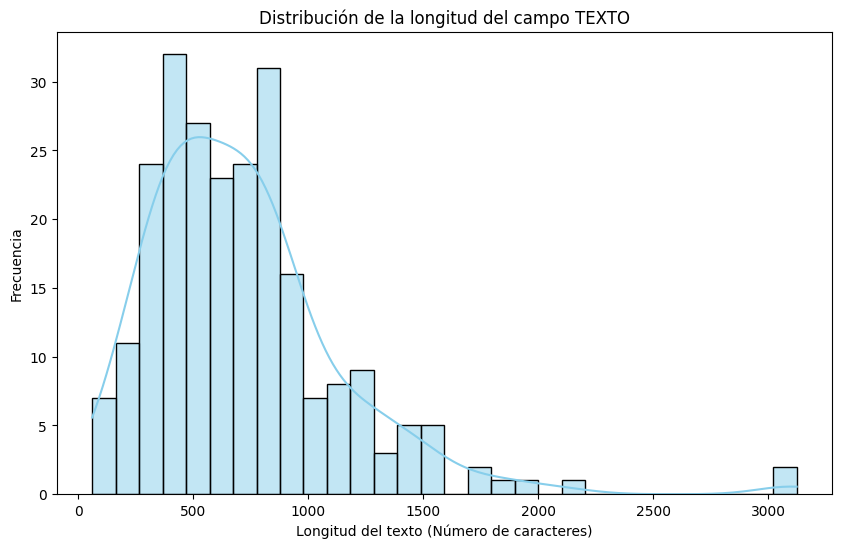

,MULTIPLES,TEXTO_LENGTH
count,239.00,239.00
mean,0.49,719.28
std,0.50,432.44
min,0.00,60.00
25%,0.00,413.00
50%,0.00,664.00
75%,1.00,876.00
max,1.00,3123.00


In [6]:
# Creamos otra columna en el df con la longitud del texto en caracteres
# apply() es uno de los métodos más importantes de pandas: aplica una función a cada elemento de una columna,
# uno por uno, y devuelve el resultado como una nueva serie
# len(): la función nativa de Python que cuenta caracteres de una cadena de texto
df_clasbin['TEXTO_LENGTH'] = df_clasbin['TEXTO'].apply(len)

import matplotlib.pyplot as plt
import seaborn as sns

# Dibujamos un histograma de la longitud de caracteres (sns.histplot, bins=30, kde=True)
# plt.figure(), sns.histplot(), plt.title(), plt.xlabel(), plt.ylabel, plt.show()
# y mostramos las estadísticas descriptivas con .describe()
plt.figure(figsize=(10,6))
# kde: Curva suavizada
sns.histplot(df_clasbin['TEXTO_LENGTH'], bins=30, kde=True, color='skyblue')
plt.title('Distribución de la longitud del campo TEXTO')
plt.xlabel('Longitud del texto (Número de caracteres)')
plt.ylabel('Frecuencia')
plt.show()

df_clasbin.describe().round(2)



Después de analizar el histograma y las estadísticas descriptivas de la longitud del texto, podemos sacar varias conclusiones importantes que son muy útiles para trabajar con PLN:

1.   **Heterogeneidad en la longitud de los textos**: Tenemos textos muy cortos (mínimo de 60 caracteres) y textos muy largos (máximo de 3123 caracteres). Esto significa que no todos las notas son iguales en cuanto a la cantidad de información textual que contienen.

In [7]:
# Mostramos el texto completo de los pacientes con índice 1, 10 y 100.
# ¿Vemos diferencias claras de longitud o estilo entre ellos?
for i in [1, 10, 100]:
    texto = df_clasbin.loc[i, 'TEXTO']
    print(f"Paciente {i} | MULTIPLES = {df_clasbin.loc[i, 'MULTIPLES']} | {len(texto)} caracteres")
    print("-" * 100)
    print(textwrap.fill(texto, width=100))
    print()


[Salida eliminada en la versión pública: mostraba fragmentos de las notas clínicas]


Respondiendo a la pregunta de la celda: **sí, hay diferencias claras de estilo, no solo de longitud.** El paciente 1 es
un párrafo redactado, el 10 es una lista numerada de eventos ("1-", "2-"...) llena de fármacos y abreviaturas, y el 100
es casi un esquema de 152 caracteres. Y los tres tienen una sola neoplasia, así que la longitud cambia muchísimo (de 152 a
1093 caracteres) incluso dentro de la misma clase. Esto ya nos avisa de dos cosas: que la longitud sola no va a separar
bien las clases, y que el preprocesado tiene que aguantar listas, siglas y números.

2.   **Necesidad de preprocesamiento adaptable**: Dado que los textos varían tanto, no podemos aplicar un enfoque de preprocesamiento único para todos. Por ejemplo:

      * **Truncamiento/Padding**: Si usamos modelos de PLN que requieren una longitud de entrada fija, necesitaremos estrategias como truncar los textos muy largos o 'rellenar' (padding) los textos muy cortos. Esto debe hacerse con cuidado para no perder información crítica o añadir ruido.
      * **Análisis de densidad de información**: Los textos más cortos podrían carecer de suficiente contexto, mientras que los más largos podrían contener mucha información redundante o irrelevante para la tarea de clasificación. Es importante considerar cómo la longitud afecta la calidad de las características extraídas.

3. **Posibles diferencias entre clases**: Podría ser interesante investigar si la longitud del texto se correlaciona con la variable `MULTIPLES`.
      * ¿Los pacientes con múltiples neoplasias tienden a tener descripciones clínicas más largas o más cortas que aquellos con una única neoplasia? Esto podría ser una característica predictiva por sí misma o indicar la complejidad de los casos.

In [8]:
# ANTES DE EJECUTAR: ¿creemos que los pacientes con múltiples neoplasias
# tendrán textos más largos o más cortos que los de una única neoplasia?

# Mostramos las estadísticas descriptivas de TEXTO_LENGTH agrupadas
# por MULTIPLES, y visualizamos la distribución con un boxplot y/o violinplot
# df_clasbin.groupby()

display(df_clasbin.groupby('MULTIPLES')['TEXTO_LENGTH'].describe().round(2))


,count,mean,std,min,25%,50%,75%,max
MULTIPLES,,,,,,,,
0,121.0,623.39,344.31,60.0,385.0,525.0,812.0,1850.0
1,118.0,817.61,489.45,106.0,557.5,761.0,975.5,3123.0


En base a estos resultados, habría que tener en cuenta que los pacientes con múltiples neoplasias tienden a tener un evolutivo más largo que aquellos pacientes con una sola neoplasia. Esto significa que la longitud podría ser una **potencial característica predictiva** en el proceso de clasificación.

Antes de ejecutar apostábamos a que los informes de múltiples neoplasias serían más largos, porque hay que contar más de
una historia, y la tabla lo confirma (mediana de 761 caracteres frente a 525). Pero hay mucho solapamiento: el 25% de
los de múltiples tiene menos de 558 caracteres y el 25% de los de una sola tiene más de 812. Así que la longitud ayuda,
pero no decide sola. Más abajo lo medimos con un número (AUC = 0.639) y lo usamos como referencia mínima.

4. **Elección del modelo de PLN**: La longitud del texto también influye en la elección de los modelos:
      * Bolsas de palabras (Bag-of-Words) / TF-IDF:
          * No tienen esta limitación de longitud, pero pueden perder el contexto secuencial.
      * Redes neuronales recurrentes (RNNs, LSTMs, GRUs) /  Transformers (BERT):
          * Manejan mejor las secuencias de longitud variable, pero tienen limitaciones en la longitud máxima de entrada.
          * Si hay muchos textos extremadamente largos, podríamos necesitar dividirlos en subtareas o utilizar modelos que manejen entradas más extensas.

      


# Pipeline clásico de PLN

El pipeline clásico de PLN agrupa un conjunto de técnicas de preprocesamiento, normalización y representación del texto orientadas a convertir documentos en estructuras numéricas simples y manejables. Su forma más habitual de uso consiste en transformar el texto en vectores de frecuencias o de pesos, como Bag-of-Words o TF-IDF, para posteriormente aplicar modelos supervisados de clasificación. Este enfoque parte de una idea fundamental: antes de intentar modelar semántica compleja, conviene construir una representación estable, interpretable y computacionalmente eficiente del contenido textual.

Otro aspecto clave de este enfoque es su **interpretabilidad**. Frente a modelos más complejos, los pipelines clásicos permiten examinar directamente qué términos contribuyen más a una clasificación, qué vocabulario se ha construido y cómo afectan las decisiones de preprocesamiento al resultado final. Esta transparencia es especialmente valiosa en dominios donde interesa justificar el comportamiento del modelo o analizar errores de forma detallada.

Son varias las ventajas de este enfoque respecto a representaciones distribucionales y modelos basados en transformers:

* Construcción de baselines fuertes y reproducibles: ¿Merece la pena la complejidad adicional de otros métodos?.
* Requiere menos datos y recursos computacionales (ej. corpus pequeños, entornos reales modestos).
* Facilita el análisis del vocabulario: ¿depende la clasificación de términos específicos?.
* Comprensión del efecto del preprocesamiento: tokenización, limpieza, normalización, etc.
* Modelos más fáciles de interpretar y depurar (RegLog).

Las fases del pipeline clásico serían:

1.   Tokenización
2.   Limpieza del texto
3.   Normalización del texto
4.   Vectorización
5.   Clasificación



## 1\. Tokenización

La tokenización permite **dividir** el texto en unidades procesables para poder representarlo y analizarlo computacionalmente.

*   Puede hacerse a nivel de **oraciones** o de **palabras**
*   No es una operación neutra: condiciona el vocabulario final
*   En texto clínico no es una operación trivial, ya que hay que considerar elementos como:
    * siglas: TAC, RM, QT
    * biomarcadores: HER2, PD-L1, Ki-67 (guiones)
    * tratamientos: AC-T
    * fechas: 22/09/2025
    * porcentajes: 85%
    * estilo telegráfico: frases muy cortas y poco conectadas

### Tokenización de oraciones

No es imprescindible para BoW o TF-IDF, pero sí útil para:
* Inspeccionar la estructura del texto: relato, frases telegráficas o lista de hallazgos.
* Detectar contexto local: Si una mención aparece en la misma oración que negación, una fecha o segunda neoplasia.
   * Ej: La aparición en un texto de estas dos oraciones:
      * “Antecedente de carcinoma de mama.”
      * “Nuevo adenocarcinoma pulmonar en estudio.”
   * puede indicar que el documento tiene más de un foco tumoral.
* Preparar análisis posteriores: Trabajar con oraciones ayuda bastante para detectar entidades, eventos o revisar errores.

In [9]:
import nltk
# Modelos preentrenados que permiten identificar los límites de las oraciones
# mediante reglas probabilísticas para cada idioma. En español:
#   - signos de puntuación de final de oración, como ., ?, !
#   - abreviaturas frecuentes
#   - patrones estadísticos aprendidos para decidir si un punto cierra oración o no
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True);  # Recurso para español (el ; evita que salga 'True')


In [10]:
# Texto del paciente 0, que ya imprimimos más arriba
texto_paciente_0 = df_clasbin.loc[0, 'TEXTO']

# ¿Cuántas oraciones creemos que tendrá el texto del paciente 0?
# Escribimos nuestra estimación antes de comprobarlo.

# Tokenizamos en oraciones

oraciones = nltk.sent_tokenize(texto_paciente_0, language='spanish')

# ¿De qué tipo es la variable que devuelve? Calculamos el número total de oraciones
# y las visualizamos
print("Tipo de la variable:", type(oraciones).__name__)
print("Número total de oraciones del paciente 0:", len(oraciones))


# Implementamos una función para tokenizar y poder usarla posteriormente
# con el iterador apply
def tokenizar_oracion(text):
    if isinstance(text, str):
        return nltk.sent_tokenize(text, language='spanish')
    return []

# Aplicamos la tokenización de oraciones a la columna 'TEXTO' y la almacenamos
# en el dataframe
df_clasbin['ORACIONES'] = df_clasbin['TEXTO'].apply(tokenizar_oracion)

# Visualizamos las oraciones del paciente número 10
oraciones = df_clasbin.loc[10, 'ORACIONES']
print(f"\nOraciones del paciente 10 ({len(oraciones)} en total):\n")
for i, oracion in enumerate(oraciones):
  print(f"[{i+1}] {oracion}")

# Visualizamos las columnas 'TEXTO' y las oraciones obtenidas
# para los 5 primeros pacientes del data frame
display(df_clasbin[['TEXTO', 'ORACIONES']].head(5))


[Salida eliminada en la versión pública: mostraba fragmentos de las notas clínicas]


[Salida eliminada en la versión pública: mostraba fragmentos de las notas clínicas]


Respondiendo a la pregunta: el paciente 0 tiene 6 oraciones, que es lo que salía contando los puntos (cada frase corta de la nota acaba en punto). Pero en el paciente 10 se ve que el tokenizador solo se guía por los puntos: cuando
un elemento de la lista no acaba en punto, lo junta con el siguiente (un tratamiento y su fecha quedan unidos en una sola "oración"),
y en el paciente 3 toma el "1." de la lista como una oración entera. En texto clínico, con listas y abreviaturas, una
"oración" de NLTK no siempre es una oración de verdad, así que el número de oraciones va a ser una medida algo ruidosa.

,n_oraciones
count,239.00
mean,8.72
std,6.33
min,1.00
25%,4.00
50%,7.00
75%,12.00
max,40.00


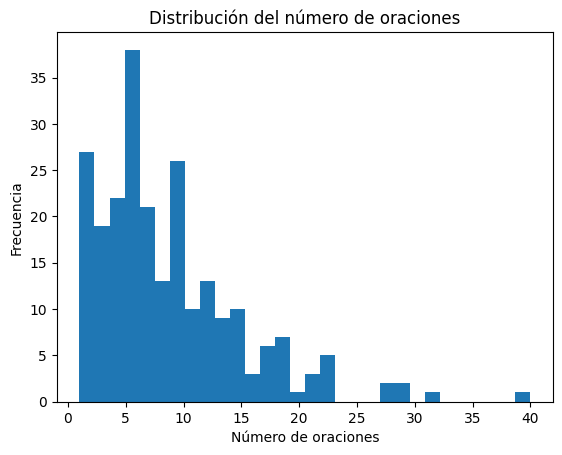

In [11]:
# Estadística descriptiva del número de oraciones

df_clasbin["n_oraciones"] = df_clasbin["ORACIONES"].apply(len)
display(df_clasbin["n_oraciones"].describe().round(2))

# Representación gráfica: histograma de la distribución del número de oraciones
plt.hist(df_clasbin["n_oraciones"], bins=30)
plt.xlabel("Número de oraciones")
plt.ylabel("Frecuencia")
plt.title("Distribución del número de oraciones")
plt.show()


,count,mean,std,min,25%,50%,75%,max
MULTIPLES,,,,,,,,
0,121.0,7.96,5.08,1.0,4.0,7.0,10.0,28.0
1,118.0,9.49,7.34,1.0,4.0,7.0,13.0,40.0


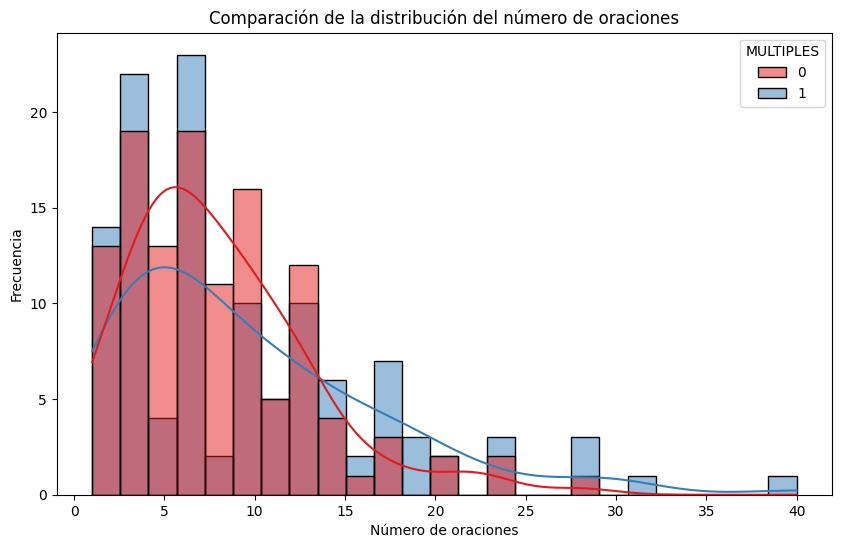

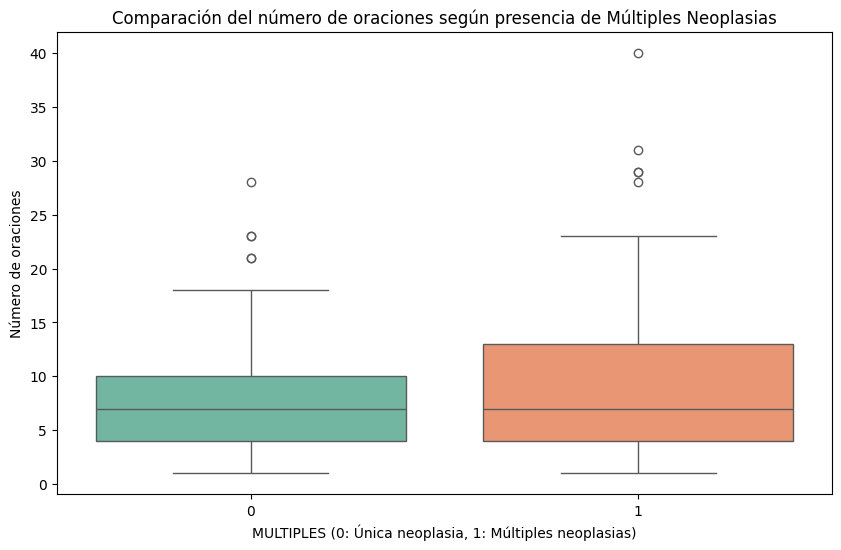

In [12]:
# 🔎 Comparamos la distribución del nº de oraciones entre
# los dos grupos de MULTIPLES, igual que hicimos con TEXTO_LENGTH.
#

display(df_clasbin.groupby('MULTIPLES')["n_oraciones"].describe().round(2))

plt.figure(figsize=(10,6))

# Dibujamos el histograma separando por la variable MULTIPLES
sns.histplot(
    data=df_clasbin,
    x='n_oraciones',
    hue='MULTIPLES',
    bins=25,
    kde=True,
    palette='Set1',
    alpha=0.5 # Añadimos transparencia para ver bien el solapamiento
)

plt.title('Comparación de la distribución del número de oraciones')
plt.xlabel('Número de oraciones')
plt.ylabel('Frecuencia')
plt.show()

plt.figure(figsize=(10,6))
sns.boxplot(x='MULTIPLES', y='n_oraciones', data=df_clasbin, hue='MULTIPLES', palette='Set2', legend=False)
plt.title('Comparación del número de oraciones según presencia de Múltiples Neoplasias')
plt.xlabel('MULTIPLES (0: Única neoplasia, 1: Múltiples neoplasias)')
plt.ylabel('Número de oraciones')
plt.show()

> ¿El número de oraciones separa tan bien los dos grupos como la longitud en caracteres, o aporta una información distinta (pensemos en textos con oraciones muy cortas vs. muy largas)?

In [13]:
# Respondemos a la pregunta con un número: el AUC que sale si usamos directamente
# cada medida de longitud como "puntuación" del paciente, sin entrenar nada.
# 0.5 sería no separar nada y 1 separar perfecto.
from sklearn.metrics import roc_auc_score
for col, nombre in [('TEXTO_LENGTH', 'Nº de caracteres'), ('n_oraciones', 'Nº de oraciones')]:
    print(f"{nombre:<17} -> AUC = {roc_auc_score(df_clasbin['MULTIPLES'], df_clasbin[col]):.3f}")

Nº de caracteres  -> AUC = 0.639
Nº de oraciones   -> AUC = 0.535


Respondiendo a la pregunta: **no, el número de oraciones casi no separa los dos grupos**.
Si usamos directamente cada medida como "puntuación" del paciente, el nº de caracteres da un
AUC de 0.639 y el nº de oraciones solo 0.535, que es casi como tirar una moneda.

Cuadra con las tablas de arriba: la mediana de oraciones es la misma en los dos grupos (7 y 7),
mientras que en caracteres hay bastante diferencia (525 frente a 761). O sea que los informes
de múltiples neoplasias son más largos, pero no porque tengan más oraciones sino porque las que
tienen son más largas (más diagnósticos y tratamientos metidos en cada línea).

Me apunto ese 0.639 de la longitud, porque más adelante lo usamos como referencia: un modelo de
texto que no lo supere no estaría aprendiendo nada más allá de "informe largo = múltiples".

### Tokenización de palabras

Después de la tokenización de oraciones, el siguiente paso fundamental es la **tokenización de palabras (word tokenization)**. Este proceso consiste en dividir cada oración, o el texto completo, en unidades más pequeñas: las palabras individuales o "tokens".

Aunque las funciones de creación de matrices de frecuencia (como `TfidfVectorizer`) realizan una tokenización interna, es importante entender y poder aplicar `nltk.word_tokenize` de forma explícita es crucial, ya que:

*   **Flexibilidad:** Permite un control más fino sobre cómo se definen las palabras (por ejemplo, cómo manejar la puntuación, números, etc.).
*   **Preprocesamiento:** Es un paso previo esencial para otras técnicas de PLN como la eliminación de "stop words", la lematización o el stemming.
*   **Análisis detallado:** Facilita el análisis de la frecuencia de palabras, la construcción de vocabularios, y la preparación para modelos de "Bag-of-Words" o "TF-IDF" cuando se desea una cadena de preprocesamiento personalizada.

[Salida eliminada en la versión pública: mostraba fragmentos de las notas clínicas]


[Salida eliminada en la versión pública: mostraba fragmentos de las notas clínicas]


El texto del paciente 0 ha sido dividido en 53 palabras/tokens.


,count,mean,std,min,25%,50%,75%,max
MULTIPLES,,,,,,,,
0,121.0,117.76,63.35,11.0,75.00,102.0,145.0,332.0
1,118.0,155.14,86.54,16.0,104.75,140.0,186.0,540.0


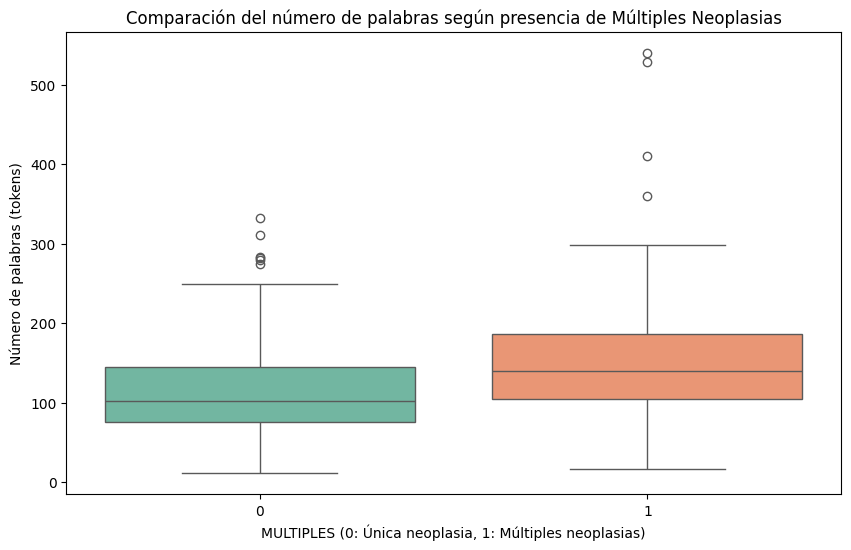

In [14]:
# Implementamos una función para tokenizar el texto en palabras, para
# poder usarla posteriormente con el iterador apply
def tokenize_words(text):
    # Comprobamos que el valor sea una cadena de texto (string)
    if isinstance(text, str):
        return nltk.word_tokenize(text, language='spanish')
    else:
        return []

# Aplicamos la tokenización de palabras a la columna 'TEXTO' y almacenamos
# el resultado en una nueva columna del dataframe
df_clasbin['PALABRAS'] = df_clasbin['TEXTO'].apply(tokenize_words)

# Visualizamos las palabras obtenidas para el paciente 0
# Separamos los tokens con | para ver bien dónde corta cada uno
print("Tokens del paciente 0:\n")
print(textwrap.fill(' | '.join(df_clasbin.loc[0, 'PALABRAS']), width=100))
print()

# Visualizamos las columnas 'TEXTO' y las palabras obtenidas
# para los 5 primeros pacientes del data frame
display(df_clasbin[['TEXTO', 'PALABRAS']].head(5))

# Contamos el número de tokens (palabras y signos de puntuación) del paciente 0
num_palabras_paciente_0 = len(df_clasbin.loc[0, 'PALABRAS'])

print(f"El texto del paciente 0 ha sido dividido en {num_palabras_paciente_0} palabras/tokens.")

# Ahora queremos saber si el número de palabras es buen predictor
df_clasbin['n_palabras'] = df_clasbin['PALABRAS'].apply(len)
display(df_clasbin.groupby('MULTIPLES')['n_palabras'].describe().round(2))

plt.figure(figsize=(10, 6))
sns.boxplot(x='MULTIPLES', y='n_palabras', data=df_clasbin, hue='MULTIPLES', palette='Set2', legend=False)
plt.title('Comparación del número de palabras según presencia de Múltiples Neoplasias')
plt.xlabel('MULTIPLES (0: Única neoplasia, 1: Múltiples neoplasias)')
plt.ylabel('Número de palabras (tokens)')
plt.show()


Aquí se ven varias cosas importantes para el texto clínico. NLTK separa los signos sueltos como tokens propios (".",
",", "("), rompe "=>" en "=" y ">", y separa el "+" de "BMO +", pero deja "R-B" junto. Es decir, lo que pasa con las
siglas y los biomarcadores depende de cómo estén escritos, y eso lo retomamos en el 6.4 al decidir si quitar la
puntuación. El número de palabras cuenta lo mismo que los caracteres: mediana de 140 palabras en los de múltiples
frente a 102 en los de una sola.

## 2\. Limpieza

Una vez ejecutada la discretización del texto en unidades atómicas o tokens, el siguiente paso lógico en el pipeline de preprocesamiento es el filtrado de componentes con baja densidad informativa.

### Stopwords

No todas las unidades resultantes de la tokenización poseen el mismo peso estadístico o semántico. Términos funcionales en español como las preposiciones «de», «por» o «en» presentan una frecuencia de aparición extremadamente alta en cualquier corpus, pero su contribución a la comprensión del contexto por parte de un modelo es mínima. Técnicamente, clasificamos estos elementos como **stopwords** o **palabras vacías**.

En muchas tareas de PLN, su eliminación es una decisión de diseño fundamental, ya que permite reducir significativamente la dimensionalidad del espacio de características y eliminar el ruido semántico. De este modo, optimizamos el rendimiento computacional al permitir que los algoritmos se centren exclusivamente en los términos con mayor carga informativa y capacidad discriminatoria.

In [15]:
from nltk.corpus import stopwords

# Cargamos el corpus de stopwords
nltk.download('stopwords', quiet=True)

# Convertimos la lista a un conjunto para usar operadores aritméticos:
# - : diferencia
# | : unión
# & : intersección
stopwords_español = set(stopwords.words('spanish'))
print(f"NLTK trae {len(stopwords_español)} stopwords en español:\n")
print(textwrap.fill(', '.join(sorted(stopwords_español)), width=100))

# Importante: Para texto clínico conviene adaptarlas a la tarea antes de usarlas.
conservar = {"no", "sin", "con", "contra", "antes", "desde", "hasta", "entre"}
stopwords_revisadas = stopwords_español - conservar
print(f"\nDespués de conservar {sorted(conservar)} nos quedan {len(stopwords_revisadas)}.")


NLTK trae 313 stopwords en español:

a, al, algo, algunas, algunos, ante, antes, como, con, contra, cual, cuando, de, del, desde, donde,
durante, e, el, ella, ellas, ellos, en, entre, era, erais, eran, eras, eres, es, esa, esas, ese,
eso, esos, esta, estaba, estabais, estaban, estabas, estad, estada, estadas, estado, estados,
estamos, estando, estar, estaremos, estará, estarán, estarás, estaré, estaréis, estaría, estaríais,
estaríamos, estarían, estarías, estas, este, estemos, esto, estos, estoy, estuve, estuviera,
estuvierais, estuvieran, estuvieras, estuvieron, estuviese, estuvieseis, estuviesen, estuvieses,
estuvimos, estuviste, estuvisteis, estuviéramos, estuviésemos, estuvo, está, estábamos, estáis,
están, estás, esté, estéis, estén, estés, fue, fuera, fuerais, fueran, fueras, fueron, fuese,
fueseis, fuesen, fueses, fui, fuimos, fuiste, fuisteis, fuéramos, fuésemos, ha, habida, habidas,
habido, habidos, habiendo, habremos, habrá, habrán, habrás, habré, habréis, habría, habríais,
h

In [16]:
# Implementamos una función que elimine las stopwords revisadas de una
# lista de palabras, para poder usarla después con apply
def remove_stopwords(word_list):
    # Usamos stopwords_revisadas aquí de manera tradicional
    palabras_filtradas = []
    for word in word_list:
        if word.lower() not in stopwords_revisadas:
            palabras_filtradas.append(word)
    return palabras_filtradas

# Otra manera:
# def remove_stopwords(word_list):
  # return [word for word in word_list if word.lower() not in stopwords_revisadas]
# Es una construcción muy típica de Python llamada list comprehension o comprensión de listas.
# [expresión for elemento in iterable if condición]

# Aplicamos la función para eliminar stopwords a la columna 'PALABRAS'
df_clasbin['PALABRAS_SIN_STOP'] = df_clasbin['PALABRAS'].apply(remove_stopwords)

# Visualizamos las columnas con el texto, las palabras y las palabras
# sin stopwords para las primeras filas
display(df_clasbin[['TEXTO', 'PALABRAS', 'PALABRAS_SIN_STOP']].head())

[Salida eliminada en la versión pública: mostraba fragmentos de las notas clínicas]


NLTK trae 313 stopwords, pero no las podemos quitar todas a ciegas: entre ellas están "no" y "sin", y en un informe
clínico no es lo mismo "metástasis" que "sin metástasis". Por eso conservamos 8 (no, sin, con, contra, antes, desde,
hasta, entre) y quitamos las otras 305. En la tabla se ve el efecto: en el paciente 1 desaparecen "a" o "los", pero en
el 4 se mantiene el "con". Si esta decisión ayuda de verdad lo comprobamos en el apartado 6 (sin quitar stopwords y
quitando la lista completa) y otra vez con TF-IDF en el 7.2.

### Signos de puntuación

De manera análoga al filtrado de stopwords que acabamos de analizar, el tratamiento de los signos de puntuación y caracteres especiales es una etapa de normalización crítica. Mientras que para el ojo humano estos símbolos —como comas, puntos o hashtags— son esenciales para estructurar la semántica, para muchos algoritmos representan ruido innecesario que incrementa la dimensionalidad del espacio de características sin aportar valor predictivo.

No obstante, al igual que ocurría con las palabras funcionales, la decisión de eliminar o conservar estos elementos depende estrictamente de la arquitectura del modelo y el objetivo del procesamiento.

*   En tareas de **reconocimiento de entidades nombradas o NER** (encontrar palabras en documentos), nuestro objetivo es reducir la dimensionalidad y eliminar el ruido. En este contexto, caracteres como barras, hashtags o signos de interrogación no aportan valor discriminatorio y dificultan la indexación de términos clave. Por ello, es una práctica estándar eliminarlos para simplificar el análisis estadístico y mejorar la eficiencia del clasificador.

*   Sin embargo, en tareas como el **Resumen Automático o generación de texto**, la puntuación actúa como el soporte estructural de la oración. Sin ella, el modelo perdería la capacidad de representar límites sintácticos y pausas semánticas, lo que resultaría en una salida incoherente o gramaticalmente incorrecta.

En definitiva, en PLN tratamos la puntuación no como un elemento fijo, sino como una variable de diseño que ajustamos según los requisitos de integridad del sistema final.

En este baseline clásico se eliminan los signos de puntuación para reducir ruido en la representación basada en frecuencias, aunque en tareas más complejas o sensibles al contexto podrían conservarse parcialmente.

In [17]:
import string

# Cadena con todos los caracteres de puntuación estándar
print("Signos de puntuación que vamos a quitar:", string.punctuation)
# Si queremos conservar alguno:
puntuacion_parcial = string.punctuation.replace(":", "")

# Creamos una tabla de traducción (diccionario internamente) para eliminar la puntuación
# str.maketrans(a, b, c)
#  a: caracteres originales que quieres sustituir
#  b: caracteres nuevos por los que quieres sustituirlos
#  c: caracteres que quieres ¿eliminar?
#  Ejemplo: tabla2 = str.maketrans('áéíóú', 'aeiou', '.,;:')
translator = str.maketrans('', '', string.punctuation)

# Función para eliminar los signos de puntuación
def remove_punctuation(word_list):
    palabras_limpias = []
    for word in word_list:
        palabra_traducida = word.translate(translator)
        if palabra_traducida != '':
            palabras_limpias.append(palabra_traducida)
    return palabras_limpias

# Aplicamos la función para eliminar signos de puntuación
df_clasbin['PALABRAS_LIMPIAS'] = df_clasbin['PALABRAS_SIN_STOP'].apply(remove_punctuation)

# Visualizamos las primeras filas con la nueva columna
display(df_clasbin[['TEXTO', 'PALABRAS_SIN_STOP', 'PALABRAS_LIMPIAS']].head())

Signos de puntuación que vamos a quitar: !"#$%&'()*+,-./:;<=>?@[\]^_`{|}~


[Salida eliminada en la versión pública: mostraba fragmentos de las notas clínicas]


Al quitar la puntuación desaparecen los tokens que solo eran signos (".", ",", "-", ":"), que es lo que buscábamos. El
problema es que `translate` también borra los signos que van dentro de una palabra: "R-B" pasa a ser "RB", y un "HER2+"
se quedaría en "HER2", perdiendo el "positivo". Lo dejamos así porque es lo de por defecto, pero me lo apunto como una
decisión que hay que comprobar, y lo hacemos en el 6.4.

## 3\. Normalización

La siguiente etapa en la fase de preprocesamiento es la normalización,  que busca reducir la variabilidad lingüística y estandarizar las palabras a una forma común. Esta tarea facilita el análisis posterior al agrupar diferentes formas de una palabra bajo un mismo concepto, y entre las técnicas más comunes de normalización se encuentran la conversión a minúsculas (**lower casing**), **stemming** y la **lematización**.

### Lowercasing

Una técnica básica de normalización es convertir todo el texto a minúsculas. Esto ayuda a evitar que palabras como “mama”, “en las que en algunos casos puede aparecer con algún carácter en mayúsculas, se traten como términos diferentes, lo que podría distorsionar el análisis de frecuencia y la extracción de características, al inflar el vocabulario y confundir al modelo.

In [18]:
# Implementamos una función que convierta a minúsculas cada palabra de la lista,
# para poder usarla después con apply
# <palabra>.lower()
def minusculas(word_list):
    return [word.lower() for word in word_list]

# Aplicamos la función a la columna 'PALABRAS_LIMPIAS' y almacenamos el resultado
# en una nueva columna del dataframe
df_clasbin['PALABRAS_MIN'] = df_clasbin['PALABRAS_LIMPIAS'].apply(minusculas)

# Visualizamos las columnas 'TEXTO', 'PALABRAS_LIMPIAS' y 'PALABRAS_MIN'
# para los 5 primeros pacientes del data frame
display(df_clasbin[['TEXTO', 'PALABRAS_LIMPIAS', 'PALABRAS_MIN']].head(5))

[Salida eliminada en la versión pública: mostraba fragmentos de las notas clínicas]


Ahora "Mujer" y "mujer" cuentan como la misma palabra, que es lo que queremos para no inflar el vocabulario. El precio
es que las siglas también pasan a minúsculas ("DL" → "dl"). Si nos sale mejor no pasar a minúsculas lo probamos en el 6.2.

### Stemming

El stemming es una técnica de normalización que reduce cada palabra a una raíz aproximada, normalmente eliminando sufijos de forma mecánica, sin tener en cuenta si el resultado coincide con una palabra real del idioma.

Su ventaja es que es rápido y sencillo, pero en español suele ser menos recomendable que la lematización (es una **lengua flexiva**), especialmente en textos clínicos, porque puede generar formas artificiales o poco interpretables.

Por ejemplo, palabras como corrí, correr y corriendo pueden reducirse todas a una raíz como corr, que no es una palabra válida; de forma similar, en lenguaje clínico podría agrupar variantes útiles de manera poco transparente y dificultar la interpretación del vocabulario final. Por ello, en este contexto se prefiere la lematización, que intenta llevar las palabras a su forma base correcta, como correr.

In [19]:
# SnowballStemmer es el stemmer estándar de NLTK para español
from nltk.stem import SnowballStemmer

# Por dentro, aplica una serie de reglas de recorte de sufijos en varias fases,
# cada una más agresiva que la anterior si se cumplen ciertas condiciones (longitud mínima de la palabra,
# terminaciones concretas, etc.). Para español, las reglas buscan sufijos típicos de:
# - plurales (-s, -es)
# - femeninos/masculinos (-a, -o)
# - sufijos verbales (-ando, -iendo, -ar, -er, -ir, -ía, etc.)
# - sufijos derivativos (-mente, -anza, -ico, etc.)
stemmer = SnowballStemmer('spanish')

for palabra in ["diagnosticada", "diagnosticó", "diagnosticar", "diagnóstico", "corriendo", "correr"]:
    print(f"{palabra:<15} -> {stemmer.stem(palabra)}")

diagnosticada   -> diagnostic
diagnosticó     -> diagnostic
diagnosticar    -> diagnostic
diagnóstico     -> diagnost
corriendo       -> corr
correr          -> corr


El ejemplo enseña los dos problemas del stemming en español. Junta bien "diagnosticada", "diagnosticó" y
"diagnosticar" en "diagnostic", pero "diagnóstico" se queda en "diagnost" por la tilde, así que la misma familia de
palabras acaba en dos raíces distintas. Y "corr" no es una palabra que se pueda leer, lo que complica interpretar el
modelo. Por eso el baseline usa lematización, aunque el stemming no lo descartamos sin probarlo (6, 6.2 y 8.5).

### Lematización

La lematización reduce variantes morfológicas de una misma palabra a una forma base común, favoreciendo una representación más compacta del vocabulario. Por ejemplo, "diagnosticada", "diagnosticó" o "diagnosticar", pueden aproximarse a
"**diagnosticar**".

En texto clínico suele ser útil, pero no siempre mejora todo, ya que a veces simplifica bien, mientras que otras veces deforma términos clínicos o siglas.

In [20]:
# spaCy es una librería de Python para Procesamiento del Lenguaje Natural,
# pensada para uso "de producción" (rápida, eficiente, fácil de integrar),
# a diferencia de nltk, que es más bien una librería didáctica/académica con funciones sueltas.
# El modelo es_dep_news_trf (sección 6.1) necesita esta librería, y tiene que
# estar instalada ANTES de importar spaCy, porque si no spaCy no la reconoce
# hasta reiniciar el entorno de Colab
!pip install -q "spacy-curated-transformers>=0.2.2,<1.0.0" > /dev/null 2>&1
import spacy

# Descargamos e instalamos el modelo de spaCy preentrenado para español
try:
    # es → idioma (español)
    # core → pipeline "completo": incluye tokenizador, etiquetador POS (categoría gramatical),
    #   lematizador, parser de dependencias sintácticas y reconocimiento de entidades (NER)
    # news → corpus de entrenamiento: noticias y texto genérico (no específico de dominio clínico)
    # sm → tamaño small (el más ligero y rápido;
    #   también existen md, lg y trf, más grandes y precisos pero más lentos)
    nlp = spacy.load("es_core_news_sm")
except OSError:
    # Lo descargamos sin que llene la salida con el progreso de pip
    !python -m spacy download es_core_news_sm > /dev/null 2>&1
    nlp = spacy.load("es_core_news_sm")

# Ejemplo:
doc = nlp("diagnosticada diagnosticó diagnosticar diagnóstico")
for token in doc:
    print(f"{token.text:<15} -> {token.lemma_}") # Ojo al guión bajo

# Función de lematización
def lematizacion(word_list):
    # une todas las palabras de la lista en una sola cadena de texto, separadas
    # por espacios. Esto es necesario porque spaCy trabaja con cadenas de texto
    # completas para procesar el contexto.
    doc = nlp(" ".join(word_list))
    # Extraemos el lema de cada token (el guión bajo de lemma es convención de spaCy)
    return [token.lemma_ for token in doc]

# Aclaración: .join() es un método de los strings, y se llama sobre el string que quieres
# usar entre cada elemento de la lista, no al principio del resultado.

# Aplicamos la función de lematización a la columna 'PALABRAS_MIN'
df_clasbin['PALABRAS_LEMAS'] = df_clasbin['PALABRAS_MIN'].apply(lematizacion)

# Mostramos el resultado
display(df_clasbin[['TEXTO', 'PALABRAS_MIN', 'PALABRAS_LEMAS']].head())

diagnosticada   -> diagnosticado
diagnosticó     -> diagnosticar
diagnosticar    -> diagnosticar
diagnóstico     -> diagnóstico


[Salida eliminada en la versión pública: mostraba fragmentos de las notas clínicas]


Con el modelo pequeño (`sm`) la lematización tampoco es perfecta: "diagnosticada" se queda en "diagnosticado" (lo toma
como adjetivo y no como verbo), y en el paciente 2 convierte "glándula" en "glándular", que ni siquiera existe. O sea que
el lematizador también se equivoca con el vocabulario médico. Esto nos llevó a preguntarnos si un modelo de spaCy más
grande lematizaría mejor, que es justo lo que probamos en el 6.1 (y con `lg` sí mejora el AUC).

## 4\. Bag-of-Words (BoW)

La matriz **Bag-of-Words** constituye una de las formas más simples y clásicas de representar texto de manera numérica. Cada documento se transforma en un vector de frecuencias sobre un vocabulario común, de modo que el modelo puede trabajar con los textos como entradas estructuradas. Aunque ignora el orden de las palabras y la sintaxis, este enfoque sigue siendo muy útil como baseline por su sencillez, interpretabilidad y capacidad para capturar señal léxica relevante.

Consiste en una representación numérica en la que:
* cada fila es un documento
* cada columna es una palabra del vocabulario
* cada celda indica cuántas veces aparece esa palabra en ese documento


In [21]:
# CountVectorizer es una clase de scikit-learn que convierte una colección de
# textos en una matriz numérica Bag-of-Words: cuenta cuántas veces aparece cada palabra en cada documento.
from sklearn.feature_extraction.text import CountVectorizer

# Unimos las palabras lematizadas en una sola cadena por documento
df_clasbin['TEXTO_PREPROCESADO'] = df_clasbin['PALABRAS_LEMAS'].apply(lambda x: ' '.join(x))

# Inicializamos CountVectorizer
# max_features puede limitar el tamaño del vocabulario para manejar la dimensionalidad
vectorizer = CountVectorizer(
    min_df=5, # Ignorar términos que aparecen en menos de 5 documentos (para filtrar ruido)
    max_df=0.8 # Ignorar términos que aparecen en más del 80% de los documentos (para filtrar stopwords muy comunes no eliminadas)
)

# Ajustamos y transformamos los datos para crear la matriz BoW
bow_matrix = vectorizer.fit_transform(df_clasbin['TEXTO_PREPROCESADO'])

# Mostramos el tamaño de la matriz BoW
print("Dimensiones de la matriz BoW:", bow_matrix.shape)

# Convertimos la matriz a DataFrame para una mejor visualización
bow_df = pd.DataFrame(bow_matrix.toarray(), columns=vectorizer.get_feature_names_out())

# Primeras 5 filas de la matriz BoW
display(bow_df.head())

Dimensiones de la matriz BoW: (239, 651)


,01,02,03,10,100,11,12,13,14,15,...,volumen,vs,x4,xelox,zoladex,área,él,óseo,último,único
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0


La matriz tiene 239 filas (una por informe) y 651 columnas (las palabras que salen en al menos 5 informes y en no más
del 80%). Casi todas las celdas son ceros, porque cada informe usa solo una pequeña parte del vocabulario. También se ve
que entran números ("01", "100", "15"...), que vienen de fechas y dosis. Los dejamos, porque el `min_df=5` ya tira los
que salen en muy pocos informes.

In [22]:
# Análisis básico del resultado
print("\nLas 20 palabras más frecuentes (y su recuento total):")
# Sumamos las frecuencias de cada palabra en todos los documentos
word_counts = bow_matrix.sum(axis=0)
# Creamos un DataFrame para las palabras y sus conteos
words_freq_df = pd.DataFrame({
    'word': vectorizer.get_feature_names_out(),
    'count': word_counts.tolist()[0]
})
# Ordenamos por conteo y mostramos las 20 principales
display(words_freq_df.sort_values(by='count', ascending=False).head(20))


Las 20 palabras más frecuentes (y su recuento total):


,word,count
120,año,242
259,estadio,175
434,negativo,173
441,no,151
388,mama,149
91,adyuvante,148
151,carcinoma,145
563,rt,137
338,iniciar,131
620,tratamiento,129


Las palabras más frecuentes son de oncología en general ("estadio", "carcinoma", "adyuvante", "tratamiento", "her2"), y
lo normal es que salgan en informes de las dos clases, así que ser frecuente no quiere decir que sirva para distinguirlas.
Lo que sí llama la atención es que "no" y "sin" están entre las 20 primeras, lo que confirma que hicimos bien en no
quitarlas como stopwords. Qué palabras separan de verdad las clases lo vemos en el apartado 9.

### Regresión logística
La regresión logística es un modelo supervisado clásico muy utilizado en clasificación. En texto, trabaja sobre una representación vectorial del documento y aprende un peso para cada característica del vocabulario. Su principal ventaja en este contexto es que proporciona un baseline sencillo, robusto e interpretable

**Importante:** Lo que se usa en lugar de "stepwise" aquí es regularización, que hace una selección de variables de forma implícita ("embedded"), no mediante tests estadísticos iterativos sino penalizando el tamaño de los coeficientes dentro de la propia optimización:

*   **L2 (Ridge)** — la que usamos por defecto con `LogisticRegression (solver='liblinear')` — no elimina variables (no las pone a 0), pero encoge los coeficientes de las menos útiles, reduciendo su influencia y el sobreajuste.
*   **L1 (Lasso)** — también disponible con `liblinear` pasando el parámetro `penalty='l1'` — sí puede poner coeficientes exactamente a 0, actuando como una selección de variables real y automática, muy usada precisamente en texto/BoW por la alta dimensionalidad.

In [23]:
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import numpy as np

# ¿X? La matriz BoW que acabamos de construir (una fila por paciente,
#     una columna por palabra del vocabulario)
X = bow_matrix
# ¿y? La etiqueta que queremos predecir
y = df_clasbin['MULTIPLES']

# Validación Cruzada Estratificada
# shuffle=True - Se aleatorizan los datos antes del split
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# max_iter: número máximo de iteraciones que el algoritmo de optimización del
#           modelo realizará para encontrar los mejores pesos (coeficientes)
#           que minimicen la función de pérdida.
# solver: Algoritmo para la optimización del modelo
#         - liblinear: eficiente para datasets pequeños y medianos,
#           y es compatible con las penalizaciones L1 y L2 (regularización)
modelo_RL = LogisticRegression(max_iter=1000, random_state=42, solver='liblinear')

# Obtenemos las puntuaciones de precisión para cada fold
scores = cross_val_score(modelo_RL, X, y, cv=skf, scoring='accuracy')
print(f"Accuracy promedio: {np.mean(scores):.4f} (+/- {np.std(scores):.4f})")

# Obtenemos las predicciones para cada muestra cuando estuvo en el conjunto de prueba
# Es lo que se conoce como  "out-of-fold predictions" (a veces abreviado OOF predictions)
y_pred_cv = cross_val_predict(modelo_RL, X, y, cv=skf)

# Para usar esta función hace falta la clase, no la probabilidad
print(classification_report(y, y_pred_cv))

print("\nMatriz de confusión:")
print(confusion_matrix(y, y_pred_cv))


Accuracy promedio: 0.6231 (+/- 0.0550)
              precision    recall  f1-score   support

           0       0.62      0.65      0.64       121
           1       0.62      0.59      0.61       118

    accuracy                           0.62       239
   macro avg       0.62      0.62      0.62       239
weighted avg       0.62      0.62      0.62       239


Matriz de confusión:
[[79 42]
 [48 70]]


Este primer modelo, con todo por defecto, acierta el 62% de los pacientes. La matriz de confusión dice que se le escapan
48 de los 118 pacientes con múltiples neoplasias (recall de 0.59) y que da 42 falsas alarmas. Es mejor que tirar una
moneda, pero no mucho. Además, el accuracy no es la métrica que nos interesa para comparar modelos, así que antes de
seguir decidimos qué métricas vamos a mirar.

### ¿Qué métrica miramos en cada momento?

Antes de ponernos a lanzar modelos conviene dejar claro qué medimos, porque si no
acabamos comparando números que no significan lo mismo. Aquí la clase positiva es
`MULTIPLES = 1` (el paciente tiene varias neoplasias):

* **Precision**: de los pacientes que el modelo marca como múltiples, cuántos lo
  son de verdad. Si esto es bajo, estamos dando muchas falsas alarmas.
* **Recall**: de los pacientes que realmente tienen múltiples neoplasias, cuántos
  conseguimos detectar. En un contexto clínico este suele ser el que más duele, porque
  dejar escapar un segundo tumor es peor que revisar un informe de más.
* **F1-score**: la media armónica de las dos anteriores. Es el resumen que usamos
  cuando ya tenemos el modelo elegido y queremos fijar el umbral de decisión.
* **AUC**: mide cómo de bien ordena el modelo a los pacientes por probabilidad,
  sin depender del umbral de 0.5. Como aquí las clases están casi equilibradas y
  lo que queremos es **comparar modelos entre sí**, esta es la métrica principal.

Resumiendo, el criterio que seguimos en clase: **AUC para comparar modelos**,
**F1 (y el par precision/recall) para decidir el umbral** una vez elegido uno.

Un matiz sobre el umbral: cuando lo fijamos en el apartado 8.7 no usamos el F1, sino un objetivo de recall (detectar al menos el 90% de los pacientes con múltiples neoplasias). El F1 da el mismo peso a los falsos positivos que a los falsos negativos, y en este problema dejar escapar un paciente con varias neoplasias es peor que revisar un informe de más, como decimos arriba al hablar del recall. Por eso ahí miramos el par precision/recall en vez de su media armónica.

In [24]:
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score
import pandas as pd
import warnings

# A partir de aquí lanzamos muchos modelos seguidos y sklearn llena la salida de
# avisos de versiones (sobre todo con penalty). Los silenciamos para poder leer
# las tablas, que es lo que interesa.
warnings.filterwarnings('ignore')

# Como vamos a repetir la misma evaluación un montón de veces (cambiando el
# preprocesamiento, la representación o el algoritmo), nos montamos una función
# para no estar copiando y pegando el mismo bloque todo el rato.
def evaluar_modelo(modelo, X, y, nombre, cv=skf):
    # Clases out-of-fold: cada paciente lo predice un modelo que NO lo vio entrenando
    y_pred = cross_val_predict(modelo, X, y, cv=cv)

    # Probabilidades out-of-fold, que son las que hacen falta para el AUC.
    # Algunos modelos (como SVC sin probability=True) no tienen predict_proba,
    # así que en ese caso tiramos de decision_function.
    try:
        y_proba = cross_val_predict(modelo, X, y, cv=cv, method='predict_proba')[:, 1]
    except AttributeError:
        y_proba = cross_val_predict(modelo, X, y, cv=cv, method='decision_function')

    return {
        'Modelo': nombre,
        'Nº features': X.shape[1],
        'Precision': precision_score(y, y_pred),
        'Recall': recall_score(y, y_pred),
        'F1': f1_score(y, y_pred),
        'AUC': roc_auc_score(y, y_proba)
    }

# Y otra función para ir enseñando los resultados en forma de tabla ordenada
def tabla_resultados(resultados, ordenar_por='AUC'):
    tabla = pd.DataFrame(resultados).sort_values(by=ordenar_por, ascending=False)
    return tabla.style.format({'Precision': '{:.4f}', 'Recall': '{:.4f}',
                               'F1': '{:.4f}', 'AUC': '{:.4f}'}).hide(axis='index')


## 5\. Baseline: regresión logística L1 vs L2

El primer resultado de referencia lo sacamos con el preprocesamiento "por defecto"
que hemos ido montando arriba (tokenización con NLTK, stopwords revisadas,
fuera puntuación, minúsculas y lematización con spaCy) y la matriz BoW con
`min_df=5` y `max_df=0.8`.

Sobre esa misma representación entrenamos las dos regresiones logísticas
regularizadas que pide el enunciado, con validación cruzada estratificada de 5
particiones:

* **L2 (Ridge)**: encoge los coeficientes pero no los pone a cero.
* **L1 (Lasso)**: sí los pone a cero, así que además hace selección de variables.
  Con 651 columnas y solo 239 pacientes esto pinta bien a priori.

#### Nuestro baseline

Para que quede claro desde aquí hasta el final, **este es el baseline** contra el que
comparamos todas las mejoras del informe (es lo que el enunciado llama "preprocesamiento
por defecto visto en clase"):

> **Baseline** = tokenización con NLTK + stopwords de NLTK revisadas (conservando "no", "sin",
> "con"...) + quitar puntuación + minúsculas + lematización con `es_core_news_sm` + BoW con
> `min_df=5` y `max_df=0.8` + **regresión logística L2** (`C=1`), evaluado con CV
> estratificada de 5 folds.

Cogemos L2 como baseline porque es la regresión logística "normal" (la que usamos en clase con `liblinear` por defecto), y L1 la tratamos como la primera variación. Aun así, como pide el enunciado, en cada variante que probamos entrenamos siempre los dos modelos (L1 y L2), y cuando hablamos de L1 con el mismo preprocesado que el baseline lo decimos así, "L1 con el preprocesado del baseline". Con la partición de `random_state=42` el baseline sale con AUC = 0.70, pero en el 5.1 vemos que ese número depende mucho de la partición, y el valor de referencia de verdad es el de 30 semillas: **AUC ≈ 0.73** (0.731 en el 5.1 y 0.733 con el vectorizador dentro del Pipeline, en la tabla del 6.2; la diferencia la explicamos en el 6.3).

#### ¿Por qué estos parámetros?

No quiero dar ningún valor por hecho, así que dejo apuntado de dónde sale cada uno. Algunos son
los de clase y los usamos tal cual para tener el punto de partida que pide el enunciado, pero
todos los que pueden cambiar el resultado los ponemos a prueba más adelante:

| Parámetro | Valor | De dónde sale | Dónde lo comprobamos |
|---|---|---|---|
| Folds de la CV | 5 | Lo pide el enunciado | 5.1: 3, 5 y 10 folds |
| `random_state` del reparto | 42 | Para que se pueda reproducir | 5.1: 30 semillas distintas |
| Nº de semillas | 30 | La desviación entre semillas es de ~0.02, así que el error de la media de 30 es ~0.02/√30 ≈ 0.004: suficiente para ver diferencias de 1 centésima | — |
| Stopwords, puntuación, minúsculas, lematización | Lo de clase | El preprocesado "por defecto" | 6, 6.1, 6.2 y 6.4 (y las stopwords otra vez con TF-IDF en el 7.2) |
| `min_df` | 5 | De clase: fuera las palabras que salen en menos de 5 informes (~2%) | 6 (`min_df=2`) y 8.5 (2, 5 y 10) |
| `max_df` | 0.8 | De clase: fuera las que salen en más del 80% de informes | 8.5 (0.8 y 1.0) |
| Unigramas, BoW de conteos | Lo de clase | — | 7 y 7.1 (n-gramas), 7.2 (TF-IDF), 8.5 (BoW binaria y TF-IDF con todos los algoritmos) |
| `C` | 1 | Valor por defecto de sklearn | 5.1 y 7.3 con CV anidada |
| `solver` | `liblinear` | Admite L1 y L2 y va bien con pocos datos | Solo cambia cómo se optimiza, no el modelo |
| `max_iter` | 1000 | Para asegurarnos de que converge | Si converge, no cambia el resultado |

In [25]:
# Los dos modelos del enunciado. Lo único que cambia entre ellos es penalty.
# C=1.0 es el valor por defecto (C es la inversa de la fuerza de regularización:
# cuanto más pequeño, más castiga a los coeficientes grandes).
modelo_L1 = LogisticRegression(penalty='l1', C=1.0, solver='liblinear',
                               max_iter=1000, random_state=42)
modelo_L2 = LogisticRegression(penalty='l2', C=1.0, solver='liblinear',
                               max_iter=1000, random_state=42)

resultados_baseline = [
    evaluar_modelo(modelo_L1, X, y, 'RegLog L1 (Lasso)'),
    evaluar_modelo(modelo_L2, X, y, 'RegLog L2 (Ridge)')
]

display(tabla_resultados(resultados_baseline))


Modelo,Nº features,Precision,Recall,F1,AUC
RegLog L1 (Lasso),651,0.6636,0.6017,0.6311,0.7020
RegLog L2 (Ridge),651,0.6250,0.5932,0.6087,0.7013


Lo que sacamos de aquí:

* Las dos van parecidas, pero **L1 queda por delante** en F1 (0.631 frente a
  0.609). En AUC están prácticamente empatadas (~0.70).
* El AUC de 0.70 significa que el modelo ordena bastante mejor que el azar (0.5),
  pero tampoco es para tirar cohetes. Hay margen de mejora.
* El recall ronda el 0.60: se nos escapan 4 de cada 10 pacientes con múltiples
  neoplasias, que es justo el error que peor nos vendría en la práctica.

Que L1 gane tiene sentido: con 651 columnas y 239 pacientes tenemos muchísimas
más variables que casos, y poner coeficientes a cero ayuda a no sobreajustar.
A partir de aquí, el baseline (L2) es la referencia contra la que comparamos todo lo demás, y L1 la seguimos entrenando a su lado en cada variante. Eso sí, los números de referencia definitivos no son los de esta tabla, sino los de 30 semillas (5.1 y 6.2), porque como vemos justo debajo con una sola partición no son fiables.

### 5.1 ¿Son robustos estos resultados?

Los números de arriba salen de **una sola** validación cruzada: 5 folds con
`random_state=42`, es decir, una forma concreta de repartir los 239 pacientes.
Con tan pocos pacientes, otro reparto podría dar métricas bastante distintas, así
que antes de usar el baseline como referencia para todo lo demás comprobamos si
es estable o si hemos tenido suerte (o mala suerte) con esa partición.

Seguimos el esquema de clase: cambiamos el `random_state` de la validación
cruzada y repetimos `cross_val_score` con la configuración del baseline
(lematización + stopwords revisadas + BoW con `min_df=5`, `max_df=0.8` y
regresión logística L2, el `modelo_RL` del apartado 4). Lo hacemos con 30
semillas (`range(30)`) y con 3, 5 y 10 folds, para ver también si el número de
particiones influye.

Usamos `cross_validate`, que es lo mismo que `cross_val_score` pero calcula
varias métricas de una vez. Cada valor de la tabla es la media de los folds para
una semilla.

In [26]:
from sklearn.model_selection import cross_validate
from scipy import stats

semillas = list(range(30))
lista_folds = [3, 5, 10]
metricas = ['Precision', 'Recall', 'F1', 'AUC']
scoring = {'Precision': 'precision', 'Recall': 'recall', 'F1': 'f1', 'AUC': 'roc_auc'}

filas = []
for n_folds in lista_folds:
    for semilla in semillas:
        # Lo único que cambia es cómo se reparten los pacientes en los folds
        cv_semilla = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=semilla)
        r = cross_validate(modelo_RL, X, y, cv=cv_semilla, scoring=scoring)
        fila = {'Folds': n_folds, 'Semilla': semilla}
        fila.update({m: r[f'test_{m}'].mean() for m in metricas})
        filas.append(fila)

robustez = pd.DataFrame(filas)

# Resumen: media, desviación típica, mínimo y máximo de cada métrica
# a lo largo de las 30 semillas, para cada número de folds
resumen = robustez.groupby('Folds')[metricas].agg(['mean', 'std', 'min', 'max'])
resumen.columns = [f'{m} {e}' for m, e in resumen.columns]
resumen = resumen.T
resumen.columns = [f'{k} folds' for k in resumen.columns]
resumen.index = (resumen.index.str.replace(' mean', ' (media)').str.replace(' std', ' (desv.)')
                 .str.replace(' min', ' (mín.)').str.replace(' max', ' (máx.)'))
display(resumen.style.format('{:.3f}'))

,3 folds,5 folds,10 folds
Precision (media),0.677,0.672,0.678
Precision (desv.),0.025,0.025,0.024
Precision (mín.),0.614,0.620,0.641
Precision (máx.),0.730,0.729,0.724
Recall (media),0.634,0.640,0.643
Recall (desv.),0.034,0.030,0.032
Recall (mín.),0.576,0.577,0.574
Recall (máx.),0.695,0.703,0.695
F1 (media),0.651,0.652,0.653
F1 (desv.),0.024,0.024,0.025


Partición original (random_state=42): AUC = 0.703 | F1 = 0.607
Semillas con 5 folds que dan un AUC más alto que la original: 30 de 30
Semillas con 5 folds que dan un F1 más alto que la original:  29 de 30


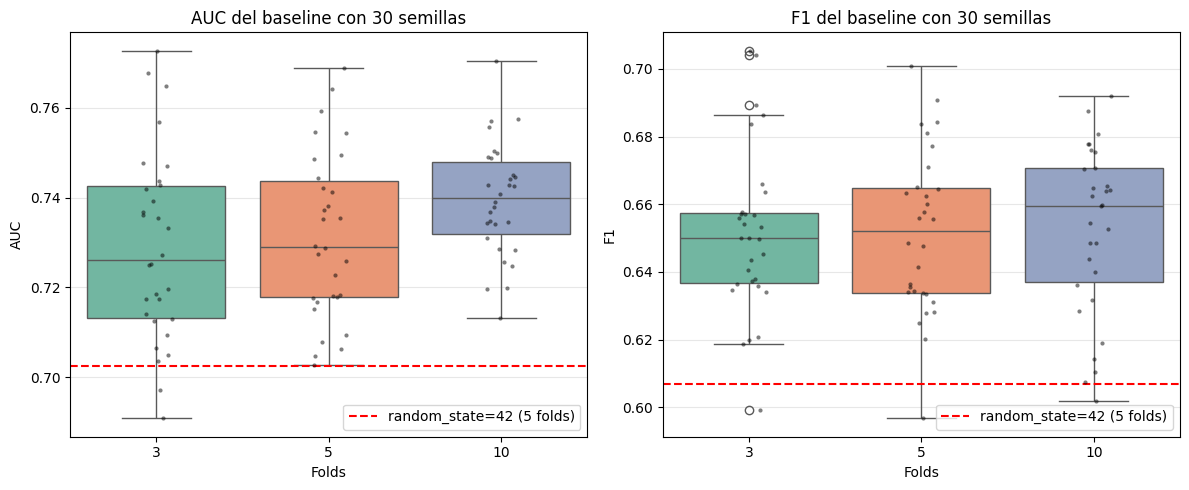

In [27]:
# Dónde cae nuestra partición original (5 folds, random_state=42) dentro de la
# distribución de las 30 semillas
original = cross_validate(modelo_RL, X, y, cv=skf, scoring=scoring)
auc_42, f1_42 = original['test_AUC'].mean(), original['test_F1'].mean()
r5 = robustez[robustez['Folds'] == 5]

print(f"Partición original (random_state=42): AUC = {auc_42:.3f} | F1 = {f1_42:.3f}")
print(f"Semillas con 5 folds que dan un AUC más alto que la original: "
      f"{(r5['AUC'] > auc_42).sum()} de {len(r5)}")
print(f"Semillas con 5 folds que dan un F1 más alto que la original:  "
      f"{(r5['F1'] > f1_42).sum()} de {len(r5)}")

fig, ejes = plt.subplots(1, 2, figsize=(12, 5))
for eje, metrica, valor_42 in zip(ejes, ['AUC', 'F1'], [auc_42, f1_42]):
    sns.boxplot(data=robustez, x='Folds', y=metrica, hue='Folds', palette='Set2', legend=False, ax=eje)
    sns.stripplot(data=robustez, x='Folds', y=metrica, color='black', size=3, alpha=0.5, ax=eje)
    eje.axhline(valor_42, color='red', linestyle='--', label='random_state=42 (5 folds)')
    eje.set_title(f'{metrica} del baseline con 30 semillas')
    eje.grid(axis='y', alpha=0.3)
    eje.legend(loc='lower right')
plt.tight_layout()
plt.show()

Lo que vemos:

* **Cambiar la semilla mueve bastante los resultados.** Con 5 folds, el AUC va
  de 0.703 a 0.769 según cómo se repartan los pacientes, y el F1 de 0.597 a 0.701.
  La desviación típica es de unas 2 centésimas en las dos métricas.
* **Nuestra partición original es de las peores.** Con `random_state=42` sale
  AUC = 0.703, y las 30 semillas dan un AUC más alto (la peor de las 30 también
  sale 0.703 con tres decimales, pero queda justo por encima, como dice la salida:
  30 de 30). En F1 pasa casi lo mismo (29
  de 30). O sea que el baseline de la tabla de arriba está **infravalorado**: lo
  esperable para esta configuración es más bien AUC ≈ 0.73 y F1 ≈ 0.65.
* **Aun así, el modelo no se viene abajo con ninguna semilla.** El peor AUC con
  5 folds es ese 0.703, prácticamente igual que el de la partición original, nunca baja de 0.69 con ningún número de folds, y la
  precision y el recall se mueven en rangos parecidos (0.62-0.73 y 0.57-0.70).
* El número de folds influye poco: las medias son casi iguales con 3, 5 y 10, y
  solo el AUC con 10 folds sube algo (0.739) y varía menos.

Esto me hace pensar que hay que tener cuidado con las comparaciones del resto del
informe: si cambiar solo la semilla mueve el AUC hasta 6 centésimas, una mejora de
1-2 centésimas entre dos configuraciones medida con una sola partición puede ser
puro azar.

#### Tests estadísticos: ¿cambia algo el número de folds?

Para comparar las medias de los tres grupos (3, 5 y 10 folds) usamos tests no
paramétricos, porque con 30 valores por grupo no queremos dar por hecho que se
distribuyen como una normal:

* **Kruskal-Wallis**: compara los tres grupos a la vez. La hipótesis nula es que
  todos vienen de la misma distribución.
* **Wilcoxon de rangos con signo**: compara los grupos de dos en dos. Es un test
  **pareado**, porque cada semilla aparece en los tres grupos, así que
  comparamos semilla con semilla.

In [28]:
filas = []
for metrica in ['AUC', 'F1']:
    grupos = [robustez.loc[robustez['Folds'] == k].sort_values('Semilla')[metrica].values
              for k in lista_folds]
    filas.append({'Métrica': metrica, 'Comparación': '3 vs 5 vs 10 (Kruskal-Wallis)',
                  'Diferencia media': np.nan, 'p-valor': stats.kruskal(*grupos).pvalue})
    for (i, a), (j, b) in [((0, 3), (1, 5)), ((1, 5), (2, 10)), ((0, 3), (2, 10))]:
        filas.append({'Métrica': metrica, 'Comparación': f'{a} vs {b} folds (Wilcoxon)',
                      'Diferencia media': (grupos[j] - grupos[i]).mean(),
                      'p-valor': stats.wilcoxon(grupos[i], grupos[j]).pvalue})

tabla_folds = pd.DataFrame(filas)
display(tabla_folds.style.format({'Diferencia media': '{:+.4f}', 'p-valor': '{:.4f}'}, na_rep='')
        .hide(axis='index'))

Métrica,Comparación,Diferencia media,p-valor
AUC,3 vs 5 vs 10 (Kruskal-Wallis),,0.0432
AUC,3 vs 5 folds (Wilcoxon),+0.0025,0.5028
AUC,5 vs 10 folds (Wilcoxon),+0.0081,0.0026
AUC,3 vs 10 folds (Wilcoxon),+0.0105,0.0175
F1,3 vs 5 vs 10 (Kruskal-Wallis),,0.8036
F1,3 vs 5 folds (Wilcoxon),+0.0001,0.8872
F1,5 vs 10 folds (Wilcoxon),+0.0012,0.6263
F1,3 vs 10 folds (Wilcoxon),+0.0014,0.9838


* En **F1** el número de folds no cambia nada: Kruskal-Wallis da p = 0.80 y
  ninguna comparación por parejas se acerca a 0.05 (las diferencias son de
  milésimas).
* En **AUC** sí hay diferencia (Kruskal-Wallis p = 0.043). Por parejas, 3 y 5
  folds son equivalentes (p = 0.50), y lo que marca la diferencia son los 10
  folds, que suben el AUC en torno a 1 centésima (p = 0.003 frente a 5 folds).

Mi explicación es que con 10 folds cada modelo entrena con el 90% de los
pacientes en vez del 80%, y con tan pocos datos esos pacientes de más se notan
un poco. De todas formas, 1 centésima es menos que la desviación típica que
provoca cambiar la semilla, así que en la práctica la conclusión no depende de si
usamos 3, 5 o 10 folds.

Un matiz: estos tests tratan las 30 semillas como si fueran 30 experimentos
independientes, y no lo son del todo, porque todas usan los mismos 239
pacientes. Eso hace que los p-valores salgan algo más pequeños de lo que
deberían, así que el p = 0.043 de Kruskal-Wallis lo cogería con pinzas.

#### ¿Es mejor que el azar?

Que el AUC sea estable no quiere decir que el modelo haya aprendido algo. Para
comprobarlo hacemos un **test de permutaciones**: desordenamos las etiquetas
`MULTIPLES` al azar 1000 veces, repetimos la misma validación cruzada cada vez y
miramos cuántas de esas versiones "sin sentido" llegan al AUC del modelo real. La
hipótesis nula es que no hay relación entre el texto y la etiqueta.

AUC con las etiquetas reales:          0.703
AUC con etiquetas desordenadas: media  0.499 | máximo 0.648
p-valor:                               0.0010


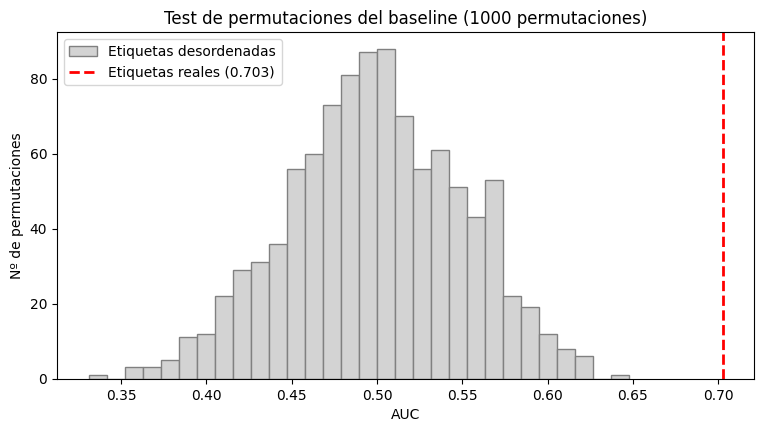

In [29]:
from sklearn.model_selection import permutation_test_score

auc_real, auc_permutados, p_valor = permutation_test_score(
    modelo_RL, X, y, cv=skf, scoring='roc_auc',
    n_permutations=1000, random_state=42, n_jobs=-1)

print(f"AUC con las etiquetas reales:          {auc_real:.3f}")
print(f"AUC con etiquetas desordenadas: media  {auc_permutados.mean():.3f} | máximo {auc_permutados.max():.3f}")
print(f"p-valor:                               {p_valor:.4f}")

plt.figure(figsize=(9, 4.5))
plt.hist(auc_permutados, bins=30, color='lightgray', edgecolor='gray', label='Etiquetas desordenadas')
plt.axvline(auc_real, color='red', linestyle='--', linewidth=2, label=f'Etiquetas reales ({auc_real:.3f})')
plt.xlabel('AUC')
plt.ylabel('Nº de permutaciones')
plt.title('Test de permutaciones del baseline (1000 permutaciones)')
plt.legend()
plt.show()

Aquí no hay duda: ninguna de las 1000 permutaciones llega al AUC real. Con las
etiquetas desordenadas el AUC se queda alrededor de 0.50 (lo que daría tirar una
moneda) y el máximo que se alcanza por casualidad es 0.648, bastante por debajo
de 0.703. El p-valor de 0.001 es el más pequeño que se puede obtener con 1000
permutaciones, así que **el baseline aprende algo real** del texto, y eso con la
partición que peor le sienta de todas las que hemos probado.

#### ¿Es mejor que mirar solo la longitud?

En el análisis exploratorio vimos que los informes de múltiples neoplasias son más largos, y
que la longitud sola ya da un AUC de 0.639. El test de permutaciones nos dice que el modelo
aprende algo, pero podría ser solo eso: que haya aprendido que "más palabras = más probable que
sean múltiples". Para descartarlo comparamos el baseline con un modelo que **solo** ve la
longitud del informe, con las mismas 30 semillas.

In [30]:
# Modelo "tonto" que solo ve la longitud del informe (en caracteres, en escala
# logarítmica porque hay textos de 60 y de 3000 caracteres), evaluado con las
# mismas 30 semillas y 5 folds que el baseline.
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

X_longitud = np.log(df_clasbin[['TEXTO_LENGTH']].values)
modelo_longitud = make_pipeline(StandardScaler(), LogisticRegression())

auc_longitud = np.array([
    cross_val_score(modelo_longitud, X_longitud, y, scoring='roc_auc',
                    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=s)).mean()
    for s in semillas])
auc_baseline_30 = robustez.query('Folds == 5').sort_values('Semilla')['AUC'].values

print(f"Solo la longitud:  AUC = {auc_longitud.mean():.3f} ± {auc_longitud.std(ddof=1):.3f}")
print(f"Baseline (BoW L2): AUC = {auc_baseline_30.mean():.3f} ± {auc_baseline_30.std(ddof=1):.3f}")
print(f"El baseline gana en {(auc_baseline_30 > auc_longitud).sum()} de 30 semillas "
      f"(Wilcoxon p = {stats.wilcoxon(auc_baseline_30, auc_longitud).pvalue:.2e})")

Solo la longitud:  AUC = 0.639 ± 0.004
Baseline (BoW L2): AUC = 0.731 ± 0.019
El baseline gana en 30 de 30 semillas (Wilcoxon p = 1.86e-09)


El baseline le saca casi una décima a la longitud (0.731 frente a 0.639) y gana en las 30
semillas, así que el modelo sí está usando el contenido del texto y no solo lo largo que es.
Curiosamente, el modelo de longitud casi no varía entre semillas (± 0.004): con una sola
variable no hay mucho que se pueda sobreajustar.

#### ¿Y L1 frente a L2 con otras semillas?

Arriba elegíamos L1 porque ganaba en F1 con la partición de `random_state=42`.
Repetimos esa comparación con las 30 semillas (5 folds), usando las **mismas
particiones** para los dos modelos, de forma que cada semilla nos da una pareja de
valores y podemos usar otra vez Wilcoxon pareado.

In [31]:
filas = []
for semilla in semillas:
    cv_semilla = StratifiedKFold(n_splits=5, shuffle=True, random_state=semilla)
    for nombre, modelo in [('L1', modelo_L1), ('L2', modelo_L2)]:
        r = cross_validate(modelo, X, y, cv=cv_semilla, scoring={'F1': 'f1', 'AUC': 'roc_auc'})
        filas.append({'Semilla': semilla, 'Modelo': nombre,
                      'F1': r['test_F1'].mean(), 'AUC': r['test_AUC'].mean()})

l1_vs_l2 = pd.DataFrame(filas).pivot(index='Semilla', columns='Modelo')

filas = []
for metrica in ['AUC', 'F1']:
    l1, l2 = l1_vs_l2[(metrica, 'L1')], l1_vs_l2[(metrica, 'L2')]
    filas.append({'Métrica': metrica, 'Media L1': l1.mean(), 'Media L2': l2.mean(),
                  'Diferencia (L1 - L2)': (l1 - l2).mean(),
                  'Semillas en las que gana L1': f'{(l1 > l2).sum()} de {len(l1)}',
                  'p-valor (Wilcoxon)': stats.wilcoxon(l1, l2).pvalue})
display(pd.DataFrame(filas).style.format({'Media L1': '{:.3f}', 'Media L2': '{:.3f}',
                                          'Diferencia (L1 - L2)': '{:+.3f}',
                                          'p-valor (Wilcoxon)': '{:.4f}'}).hide(axis='index'))

Métrica,Media L1,Media L2,Diferencia (L1 - L2),Semillas en las que gana L1,p-valor (Wilcoxon)
AUC,0.745,0.731,+0.014,21 de 30,0.0007
F1,0.670,0.652,+0.019,22 de 30,0.0002


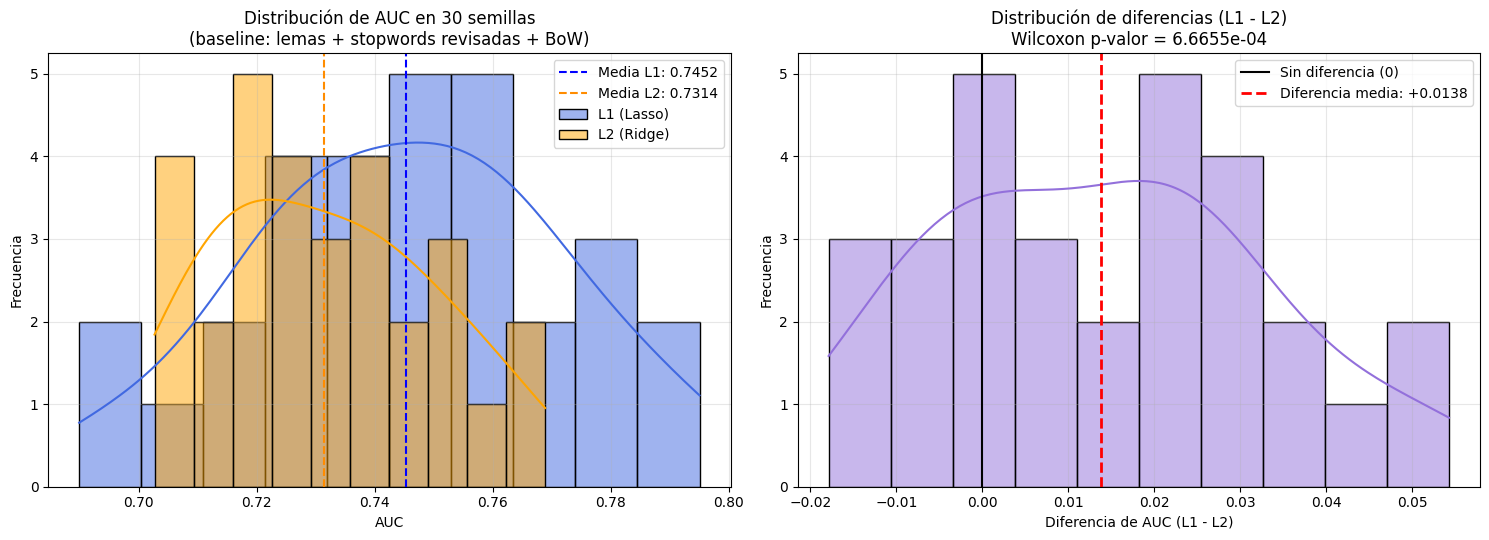

In [32]:
from scipy.stats import wilcoxon

# AUC de cada modelo en las 30 semillas (mismas particiones para los dos)
aucs_L1 = l1_vs_l2[('AUC', 'L1')].values
aucs_L2 = l1_vs_l2[('AUC', 'L2')].values
dif = aucs_L1 - aucs_L2               # diferencia pareada, semilla a semilla
p_wilcoxon = wilcoxon(aucs_L1, aucs_L2).pvalue

fig, ejes = plt.subplots(1, 2, figsize=(15, 5.5))

# --- Izquierda: los dos histogramas superpuestos, con su curva y su media
sns.histplot(aucs_L1, bins=10, kde=True, color='royalblue', alpha=0.5, label='L1 (Lasso)', ax=ejes[0])
sns.histplot(aucs_L2, bins=10, kde=True, color='orange', alpha=0.5, label='L2 (Ridge)', ax=ejes[0])
ejes[0].axvline(aucs_L1.mean(), color='blue', linestyle='--', label=f'Media L1: {aucs_L1.mean():.4f}')
ejes[0].axvline(aucs_L2.mean(), color='darkorange', linestyle='--', label=f'Media L2: {aucs_L2.mean():.4f}')
ejes[0].set_title(f'Distribución de AUC en {len(dif)} semillas\n(baseline: lemas + stopwords revisadas + BoW)')
ejes[0].set_xlabel('AUC')
ejes[0].set_ylabel('Frecuencia')
ejes[0].legend()
ejes[0].grid(alpha=0.3)

# --- Derecha: distribución de las diferencias (L1 - L2)
sns.histplot(dif, bins=10, kde=True, color='mediumpurple', alpha=0.5, ax=ejes[1])
ejes[1].axvline(0, color='black', linewidth=1.5, label='Sin diferencia (0)')
ejes[1].axvline(dif.mean(), color='red', linestyle='--', linewidth=2,
                label=f'Diferencia media: {dif.mean():+.4f}')
ejes[1].set_title(f'Distribución de diferencias (L1 - L2)\nWilcoxon p-valor = {p_wilcoxon:.4e}')
ejes[1].set_xlabel('Diferencia de AUC (L1 - L2)')
ejes[1].set_ylabel('Frecuencia')
ejes[1].legend()
ejes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

Con 30 semillas la elección de L1 sale reforzada: gana en F1 en 22 de las 30
semillas y en AUC en 21, con una ventaja media de 1-2 centésimas (p < 0.001 en
las dos métricas). Con la partición de `random_state=42` las dos parecían
empatadas en AUC, pero repitiendo con otras semillas L1 queda algo por delante
también ahí. Aun así la diferencia es pequeña, del mismo orden que la variación
por semilla, y el matiz de antes sobre la independencia de las semillas también
vale aquí.

#### Validación cruzada anidada

Hasta ahora `C` (la inversa de la fuerza de regularización) se ha quedado en su
valor por defecto, 1.0. Si quisiéramos elegirla mirando qué valor da mejor AUC en
la propia validación cruzada, estaríamos haciendo trampa: elegiríamos el
hiperparámetro con los mismos datos con los que luego medimos, y el resultado
saldría optimista.

La forma correcta es la **validación cruzada anidada** (doble validación
cruzada):

* El **bucle externo** (5 folds) separa en cada vuelta unos pacientes de test que
  el modelo no ve para nada.
* El **bucle interno** (otros 5 folds, solo con los pacientes de entrenamiento)
  prueba varios valores de `C` con `GridSearchCV` y se queda con el mejor.
* El modelo con esa `C` se evalúa en el test del bucle externo.

Así la elección de `C` forma parte del entrenamiento y lo que medimos fuera es
honesto. Lo repetimos también con las 30 semillas y lo comparamos con el baseline
de `C=1` en las mismas particiones externas.

In [33]:
from sklearn.model_selection import GridSearchCV

valores_C = {'C': [0.001, 0.01, 0.1, 1, 10, 100]}

filas = []
C_elegidas = []
for semilla in semillas:
    externa = StratifiedKFold(n_splits=5, shuffle=True, random_state=semilla)
    interna = StratifiedKFold(n_splits=5, shuffle=True, random_state=semilla + 100)

    # GridSearchCV es el bucle interno: dentro de cada fold externo busca la mejor C
    busqueda = GridSearchCV(modelo_RL, valores_C, cv=interna, scoring='roc_auc')
    r = cross_validate(busqueda, X, y, cv=externa, scoring={'F1': 'f1', 'AUC': 'roc_auc'},
                       return_estimator=True)

    C_elegidas += [modelo.best_params_['C'] for modelo in r['estimator']]
    filas.append({'Semilla': semilla, 'F1': r['test_F1'].mean(), 'AUC': r['test_AUC'].mean()})

anidada = pd.DataFrame(filas)
fija = robustez[robustez['Folds'] == 5].sort_values('Semilla')

filas = []
for metrica in ['AUC', 'F1']:
    filas.append({'Métrica': metrica,
                  'C = 1 (baseline)': f"{fija[metrica].mean():.3f} ± {fija[metrica].std():.3f}",
                  'C elegida con CV anidada': f"{anidada[metrica].mean():.3f} ± {anidada[metrica].std():.3f}",
                  'Diferencia (anidada - fija)': anidada[metrica].values.mean() - fija[metrica].values.mean(),
                  'p-valor (Wilcoxon)': stats.wilcoxon(anidada[metrica].values, fija[metrica].values).pvalue})
display(pd.DataFrame(filas).style.format({'Diferencia (anidada - fija)': '{:+.3f}',
                                          'p-valor (Wilcoxon)': '{:.4f}'}).hide(axis='index'))

# Qué C ha elegido el bucle interno en cada uno de los 150 folds externos (30 semillas x 5)
print("\nValor de C elegido en los 150 folds externos:")
print(pd.Series(C_elegidas).value_counts().sort_index().to_string())

Métrica,C = 1 (baseline),C elegida con CV anidada,Diferencia (anidada - fija),p-valor (Wilcoxon)
AUC,0.731 ± 0.019,0.733 ± 0.019,+0.001,0.9193
F1,0.652 ± 0.024,0.668 ± 0.019,+0.016,0.0010



Valor de C elegido en los 150 folds externos:
0.001      76
0.010      30
0.100      32
1.000       7
10.000      4
100.000     1


Lo que sacamos de la validación cruzada anidada:

* **En AUC no cambia nada**: 0.733 frente a 0.731, p = 0.92. Ajustar `C` no
  mejora la capacidad del modelo para ordenar a los pacientes, y también nos dice
  que el AUC del baseline con `C = 1` no estaba inflado por haber elegido mal
  el hiperparámetro.
* **En F1 sí mejora un poco**: de 0.652 a 0.668 (p = 0.001), y además varía algo
  menos entre semillas.
* **El bucle interno casi nunca elige `C = 1`**: solo en 7 de los 150 folds. La
  mitad de las veces se va a `C = 0.001`, que es la regularización más fuerte de
  la rejilla, y casi siempre a valores ≤ 0.1. Tiene sentido, porque con 651
  columnas y 239 pacientes al modelo le conviene que le recorten mucho los
  coeficientes.
* Que la `C` elegida cambie tanto de un fold a otro también me dice que no hay
  un valor claramente mejor, sino que hay una zona bastante plana entre 0.001 y
  0.1 donde el modelo funciona parecido.

**Respuesta a la pregunta:** sí, considero que los resultados del baseline son
robustos en el sentido de que el modelo es claramente mejor que el azar con
cualquier semilla, número de folds o valor de `C`, y su AUC se mantiene en torno
a 0.73 ± 0.02. Lo que no es robusto es el número concreto: el 0.70 de
`random_state=42` era la partición más desfavorable de todas, y diferencias de
1-2 centésimas entre configuraciones no se pueden tomar como mejoras reales si
solo las hemos medido con una partición.

## 6\. ¿Y si cambiamos las decisiones de preprocesamiento?

Todo el preprocesamiento de arriba lo hemos hecho siguiendo lo que se suele hacer
"por defecto", pero el enunciado pide justo lo contrario: comprobar **con datos**
si esas decisiones ayudan de verdad en este problema concreto o si las estamos
arrastrando por costumbre.

Las variantes que vamos a probar son:

| Variante | Qué cambia |
|---|---|
| **Baseline** | stopwords revisadas + lematización (lo de arriba) |
| **Sin normalizar** | nos quedamos en minúsculas, sin lematizar |
| **Stemming** | cambiamos la lematización de spaCy por el stemmer de Snowball |
| **Sin quitar stopwords** | nos quedamos con todas las palabras |
| **Stopwords completas** | quitamos TODAS las stopwords, también el "no", "sin", etc. |
| **Vocabulario amplio** | baseline pero con `min_df=2` en vez de 5 |

Para no repetir el mismo bloque seis veces nos montamos una función que encadena los
pasos del pipeline según lo que le pidamos.

In [34]:
# Función que rehace el preprocesamiento según las opciones que le pasemos.
# Reutiliza las funciones que ya definimos arriba (remove_stopwords,
# remove_punctuation, minusculas, lematizacion) para no reinventar nada.
def preprocesar(serie_textos, quitar_stopwords=True, stopwords_set=None,
                normalizacion='lemas'):
    # 1. Tokenización en palabras
    palabras = serie_textos.apply(tokenize_words)

    # 2. Limpieza: stopwords (opcional) + puntuación
    if quitar_stopwords:
        sw = stopwords_set if stopwords_set is not None else stopwords_revisadas
        palabras = palabras.apply(lambda lista: [p for p in lista if p.lower() not in sw])
    palabras = palabras.apply(remove_punctuation)

    # 3. Normalización: siempre minúsculas, y encima lemas / stems / nada
    palabras = palabras.apply(minusculas)
    if normalizacion == 'lemas':
        palabras = palabras.apply(lematizacion)
    elif normalizacion == 'stem':
        palabras = palabras.apply(lambda lista: [stemmer.stem(p) for p in lista])

    # 4. Volver a unir en una cadena por documento, que es lo que espera CountVectorizer
    return palabras.apply(lambda lista: ' '.join(lista))

# Las seis configuraciones que queremos comparar.
# Cada una es: (nombre, opciones del preprocesado, min_df del vectorizador)
configuraciones = [
    ('Baseline (stopwords rev. + lemas)', dict(), 5),
    ('Sin normalizar (solo minúsculas)',  dict(normalizacion='ninguna'), 5),
    ('Stemming en vez de lematización',   dict(normalizacion='stem'), 5),
    ('Sin quitar stopwords',              dict(quitar_stopwords=False), 5),
    ('Stopwords completas de NLTK',       dict(stopwords_set=stopwords_español), 5),
    ('Baseline con min_df=2',             dict(), 2),
]

resultados_prepro = []
textos_por_config = {}   # nos los guardamos para reutilizarlos después

for nombre, opciones, min_df in configuraciones:
    print(f"Procesando: {nombre} ...")
    textos = preprocesar(df_clasbin['TEXTO'], **opciones)
    textos_por_config[nombre] = textos

    vec = CountVectorizer(min_df=min_df, max_df=0.8)
    X_var = vec.fit_transform(textos)

    for etiqueta, modelo in [('L1', modelo_L1), ('L2', modelo_L2)]:
        fila = evaluar_modelo(modelo, X_var, y, f'{nombre} — {etiqueta}')
        resultados_prepro.append(fila)

display(tabla_resultados(resultados_prepro))


Procesando: Baseline (stopwords rev. + lemas) ...
Procesando: Sin normalizar (solo minúsculas) ...
Procesando: Stemming en vez de lematización ...
Procesando: Sin quitar stopwords ...
Procesando: Stopwords completas de NLTK ...
Procesando: Baseline con min_df=2 ...


Modelo,Nº features,Precision,Recall,F1,AUC
Stemming en vez de lematización — L1,660,0.7000,0.6525,0.6754,0.7435
Sin quitar stopwords — L2,687,0.6545,0.6102,0.6316,0.7181
Sin quitar stopwords — L1,687,0.6667,0.6102,0.6372,0.7172
Stopwords completas de NLTK — L2,647,0.6283,0.6017,0.6147,0.7139
Baseline con min_df=2 — L2,1682,0.6604,0.5932,0.6250,0.7114
Stopwords completas de NLTK — L1,647,0.6542,0.5932,0.6222,0.7067
Baseline con min_df=2 — L1,1682,0.6574,0.6017,0.6283,0.7030
Baseline (stopwords rev. + lemas) — L1,651,0.6636,0.6017,0.6311,0.7020
Baseline (stopwords rev. + lemas) — L2,651,0.6250,0.5932,0.6087,0.7013
Sin normalizar (solo minúsculas) — L1,659,0.6827,0.6017,0.6396,0.6931


Esto sí que me ha sorprendido bastante:

* La configuración que mejor sale es **stemming + L1**, con F1 = 0.675 y
  AUC = 0.744. Es una mejora clara sobre el baseline (F1 0.609, AUC 0.701) y sobre L1 con el preprocesado del baseline (F1 0.631, AUC 0.702), al menos con esta
  partición (en el 6.2 lo comprobamos con 30 semillas).
* O sea que en este corpus **el stemming funciona mejor que la lematización**,
  justo al revés de lo que decíamos en la parte teórica. Mi primera sospecha es
  que tenga que ver con el modelo de spaCy que estamos usando: `es_core_news_sm`
  es el más pequeño de los que hay para español. Lo compruebo justo debajo.
* Quitar las stopwords apenas cambia nada (0.702 vs 0.717 de AUC). Tiene sentido:
  el `max_df=0.8` del vectorizador ya se está cargando las palabras que salen en
  casi todos los documentos, así que estamos haciendo el mismo trabajo dos veces.
* Ampliar el vocabulario con `min_df=2` tampoco mejora: pasamos de 651 a 1682
  columnas y el AUC se queda igual. Solo estamos metiendo palabras raras que
  aparecen en dos o tres informes y que el modelo no puede aprovechar.
* En **F1**, L1 le gana a L2 en todas las variantes (en AUC no siempre: sin
  quitar stopwords, con las stopwords completas y con `min_df=2` gana L2 por poco), lo que
  refuerza la idea de que aquí la selección de variables es lo que manda.

### 6.1 ¿Es culpa del modelo de spaCy?

Hasta ahora hemos lematizado con `es_core_news_sm`, que es el modelo más ligero.
spaCy tiene otros tres para español:

* `es_core_news_md` y `es_core_news_lg`: el mismo pipeline pero más grandes (con
  vectores de palabras), en teoría más precisos.
* `es_dep_news_trf`: basado en transformers. Es el más pesado y bastante más
  lento.

Los cuatro están entrenados con noticias, ninguno con texto clínico. Repetimos el
baseline (stopwords revisadas + lematización + BoW) cambiando **solo** el modelo
de spaCy, para ver si la diferencia con el stemming viene de ahí.

In [35]:
# Los cuatro modelos de spaCy para español, de más pequeño a más grande
modelos_spacy = ['es_core_news_sm', 'es_core_news_md', 'es_core_news_lg', 'es_dep_news_trf']

resultados_spacy = []
for nombre_modelo in modelos_spacy:
    print(f"Lematizando con {nombre_modelo} ...")
    try:
        nlp = spacy.load(nombre_modelo)
    except OSError:
        !python -m spacy download {nombre_modelo} > /dev/null 2>&1
        nlp = spacy.load(nombre_modelo)

    # preprocesar() llama a lematizacion(), que usa la variable nlp, así que al
    # cambiar nlp cambiamos el modelo con el que se lematiza
    textos = preprocesar(df_clasbin['TEXTO'])
    X_spacy = CountVectorizer(min_df=5, max_df=0.8).fit_transform(textos)

    for etiqueta, modelo in [('L1', modelo_L1), ('L2', modelo_L2)]:
        resultados_spacy.append(evaluar_modelo(modelo, X_spacy, y, f'{nombre_modelo} — {etiqueta}'))

    # Cómo lematiza cada modelo algunas palabras clínicas del corpus
    ejemplo = nlp('sincrónica hemicolectomía adenocarcinomas metástasis')
    print('   ', ', '.join(f'{t.text} -> {t.lemma_}' for t in ejemplo))

# Volvemos a dejar el modelo pequeño, que es el que usa el resto del notebook
nlp = spacy.load('es_core_news_sm')

display(tabla_resultados(resultados_spacy))


Lematizando con es_core_news_sm ...
    sincrónica -> sincrónico, hemicolectomía -> hemicolectomía, adenocarcinomas -> adenocarcinoma, metástasis -> metástasis
Lematizando con es_core_news_md ...
    sincrónica -> sincrónico, hemicolectomía -> hemicolectomir, adenocarcinomas -> adenocarcinoma, metástasis -> metástasis
Lematizando con es_core_news_lg ...
    sincrónica -> sincrónico, hemicolectomía -> hemicolectomía, adenocarcinomas -> adenocarcinoma, metástasis -> metástasis
Lematizando con es_dep_news_trf ...
    sincrónica -> sincrónico, hemicolectomía -> hemicolectomía, adenocarcinomas -> adenocarcinoma, metástasis -> metástasi


Modelo,Nº features,Precision,Recall,F1,AUC
es_core_news_lg — L1,666,0.6990,0.6102,0.6516,0.7438
es_core_news_md — L1,661,0.6875,0.6525,0.6696,0.7356
es_dep_news_trf — L1,657,0.6729,0.6102,0.6400,0.7238
es_core_news_lg — L2,666,0.6579,0.6356,0.6466,0.7212
es_core_news_md — L2,661,0.6491,0.6271,0.6379,0.7080
es_dep_news_trf — L2,657,0.6667,0.5763,0.6182,0.7065
es_core_news_sm — L1,651,0.6636,0.6017,0.6311,0.7020
es_core_news_sm — L2,651,0.6250,0.5932,0.6087,0.7013


Pues en parte sí que era eso:

* Con `lg` la lematización llega a AUC = 0.744, prácticamente lo mismo que el
  stemming (0.7438 frente a 0.7435), y `md` se queda cerca (0.736). O sea que buena parte de la ventaja
  del stemming venía de estar usando el modelo pequeño.
* En F1 el stemming sigue algo por delante (0.675, frente a 0.670 de `md` y 0.652
  de `lg`).
* `trf`, que es el más grande y el más lento, no es el mejor (AUC 0.724). Para
  esta tarea, más grande no significa mejor.
* Viendo cómo lematiza cada uno, se nota que ninguno está hecho para texto
  clínico: `md` convierte "hemicolectomía" en "hemicolectomir", como si fuera
  un verbo, y `trf` deja "metástasis" en
  "metástasi". Son fallos pequeños, pero en un corpus de 239 informes cada palabra
  partida en dos columnas cuenta.

**Decisión provisional**: con esta partición el stemming y la lematización con `lg`
empatan en AUC (0.7435 frente a 0.7438) y el stemming gana algo en F1. Pero en el
apartado 5.1 vimos que solo cambiar la semilla mueve el AUC hasta 6 centésimas, así
que una diferencia de 3 diezmilésimas no dice nada. Antes de decidir lo comprobamos
con las 30 semillas.

### 6.2 Elegimos el preprocesado con 30 semillas

La decisión de arriba sale de **una sola** partición (`random_state=42`), y en el
apartado 5.1 vimos que solo cambiar la semilla ya mueve el AUC del baseline hasta 6
centésimas. Las diferencias entre preprocesados son de 1-4 centésimas, así que con
una partición no podemos fiarnos de cuál gana.

Hacemos lo mismo que en el 5.1: evaluamos cada preprocesado con regresión logística
(L1 y L2) en las **mismas 30 semillas** (`range(30)`, 5 folds), nos quedamos con el
que tenga mejor AUC medio y lo comparamos con los siguientes con **Wilcoxon pareado**
(cada semilla es la misma partición para todos, así que los valores van por parejas).

Metemos las seis variantes del apartado 6 y, además, la lematización con
`es_core_news_md` y `es_core_news_lg`, que en el 6.1 salían muy cerca del stemming. También probamos a **no pasar el texto a
minúsculas**, con lemas `sm` y `lg`, porque a una compañera de clase le subía bastante
el AUC del baseline así.
El `trf` lo dejamos fuera porque en el 6.1 salía peor que `lg` y es muchísimo más
lento.

Un cambio respecto a lo anterior: ahora el `CountVectorizer` va **dentro de un
Pipeline** junto al modelo, así que en cada fold el vocabulario se construye solo con
los pacientes de entrenamiento. En el 6.3 explicamos por qué.

In [36]:
from sklearn.pipeline import make_pipeline

# Textos de las dos lematizaciones con modelos grandes de spaCy (apartado 6.1),
# para meterlas también en la comparación. preprocesar() usa la variable nlp.
for nombre_modelo in ['es_core_news_md', 'es_core_news_lg']:
    nlp = spacy.load(nombre_modelo)
    textos_por_config[f'Lematización con {nombre_modelo}'] = preprocesar(df_clasbin['TEXTO'])
nlp = spacy.load('es_core_news_sm')

# Variantes SIN pasar a minúsculas (lo que le funcionó a una compañera de clase).
# Ojo: CountVectorizer pasa a minúsculas por defecto, así que además hay que
# ponerle lowercase=False, si no la prueba no cambiaría nada.
def preprocesar_mayus(serie_textos):
    palabras = serie_textos.apply(tokenize_words)
    palabras = palabras.apply(lambda lista: [p for p in lista if p.lower() not in stopwords_revisadas])
    palabras = palabras.apply(remove_punctuation)
    palabras = palabras.apply(lematizacion)   # sin minusculas()
    return palabras.apply(lambda lista: ' '.join(lista))

for nombre_modelo, etiqueta_modelo in [('es_core_news_sm', 'sm'), ('es_core_news_lg', 'lg')]:
    nlp = spacy.load(nombre_modelo)
    textos_por_config[f'Lemas {etiqueta_modelo} con mayúsculas'] = preprocesar_mayus(df_clasbin['TEXTO'])
nlp = spacy.load('es_core_news_sm')
con_mayusculas = {'Lemas sm con mayúsculas', 'Lemas lg con mayúsculas'}

# min_df de cada configuración (todas con 5 menos la de vocabulario amplio)
min_df_config = {nombre: min_df for nombre, _, min_df in configuraciones}

# Ahora el CountVectorizer va DENTRO de un Pipeline, así que en cada fold el
# vocabulario se construye solo con los pacientes de entrenamiento (sin fuga).
guardado = cargar('6_2_prepro_30')
if guardado is not None:
    prepro_30 = guardado
else:
    filas = []
    for nombre, textos in textos_por_config.items():
        print(f"Evaluando con 30 semillas: {nombre} ...")
        for etiqueta, modelo in [('L1', modelo_L1), ('L2', modelo_L2)]:
            pipe = make_pipeline(CountVectorizer(min_df=min_df_config.get(nombre, 5), max_df=0.8,
                                                 lowercase=nombre not in con_mayusculas), modelo)
            for semilla in semillas:
                cv_semilla = StratifiedKFold(n_splits=5, shuffle=True, random_state=semilla)
                r = cross_validate(pipe, textos, y, cv=cv_semilla, scoring={'F1': 'f1', 'AUC': 'roc_auc'})
                filas.append({'Preprocesado': nombre, 'Modelo': etiqueta, 'Semilla': semilla,
                              'F1': r['test_F1'].mean(), 'AUC': r['test_AUC'].mean()})

    prepro_30 = pd.DataFrame(filas)
    guardar('6_2_prepro_30', prepro_30)

# Media ± desviación de cada configuración a lo largo de las 30 semillas
resumen_prepro = (prepro_30.groupby(['Preprocesado', 'Modelo'])[['AUC', 'F1']]
                  .agg(['mean', 'std']))
resumen_prepro.columns = [f'{m} {e}' for m, e in resumen_prepro.columns]
resumen_prepro = resumen_prepro.sort_values('AUC mean', ascending=False).reset_index()
display(resumen_prepro.style.format({'AUC mean': '{:.3f}', 'AUC std': '{:.3f}',
                                     'F1 mean': '{:.3f}', 'F1 std': '{:.3f}'}).hide(axis='index'))


Preprocesado,Modelo,AUC mean,AUC std,F1 mean,F1 std
Lematización con es_core_news_lg,L1,0.778,0.021,0.695,0.026
Stemming en vez de lematización,L1,0.765,0.023,0.696,0.029
Lemas sm con mayúsculas,L2,0.763,0.016,0.679,0.024
Lematización con es_core_news_md,L1,0.761,0.023,0.680,0.027
Sin quitar stopwords,L1,0.754,0.022,0.675,0.029
Lemas sm con mayúsculas,L1,0.753,0.022,0.680,0.028
Lemas lg con mayúsculas,L1,0.752,0.022,0.681,0.032
Lematización con es_core_news_lg,L2,0.747,0.018,0.666,0.022
Baseline (stopwords rev. + lemas),L1,0.746,0.026,0.670,0.027
Baseline con min_df=2,L1,0.745,0.025,0.674,0.028


Modelo,Comparación,Métrica,Diferencia media,Semillas en las que gana la 1ª,p-valor (Wilcoxon)
L1,Lematización con es_core_news_lg vs Stemming en vez de lematización,AUC,+0.013,26 de 30,< 0.0001
L1,Lematización con es_core_news_lg vs Stemming en vez de lematización,F1,-0.000,15 de 30,0.7303
L1,Lematización con es_core_news_lg vs Lematización con es_core_news_md,AUC,+0.017,29 de 30,< 0.0001
L1,Lematización con es_core_news_lg vs Lematización con es_core_news_md,F1,+0.015,25 de 30,0.0003
L1,Lematización con es_core_news_lg vs Baseline (stopwords rev. + lemas),AUC,+0.033,30 de 30,< 0.0001
L1,Lematización con es_core_news_lg vs Baseline (stopwords rev. + lemas),F1,+0.025,27 de 30,< 0.0001
L2,Lematización con es_core_news_lg vs Stopwords completas de NLTK,AUC,+0.003,18 de 30,0.0699
L2,Lematización con es_core_news_lg vs Stopwords completas de NLTK,F1,+0.000,16 de 30,0.8712
L2,Lematización con es_core_news_lg vs Baseline (stopwords rev. + lemas),AUC,+0.014,29 de 30,< 0.0001
L2,Lematización con es_core_news_lg vs Baseline (stopwords rev. + lemas),F1,+0.011,24 de 30,0.0003


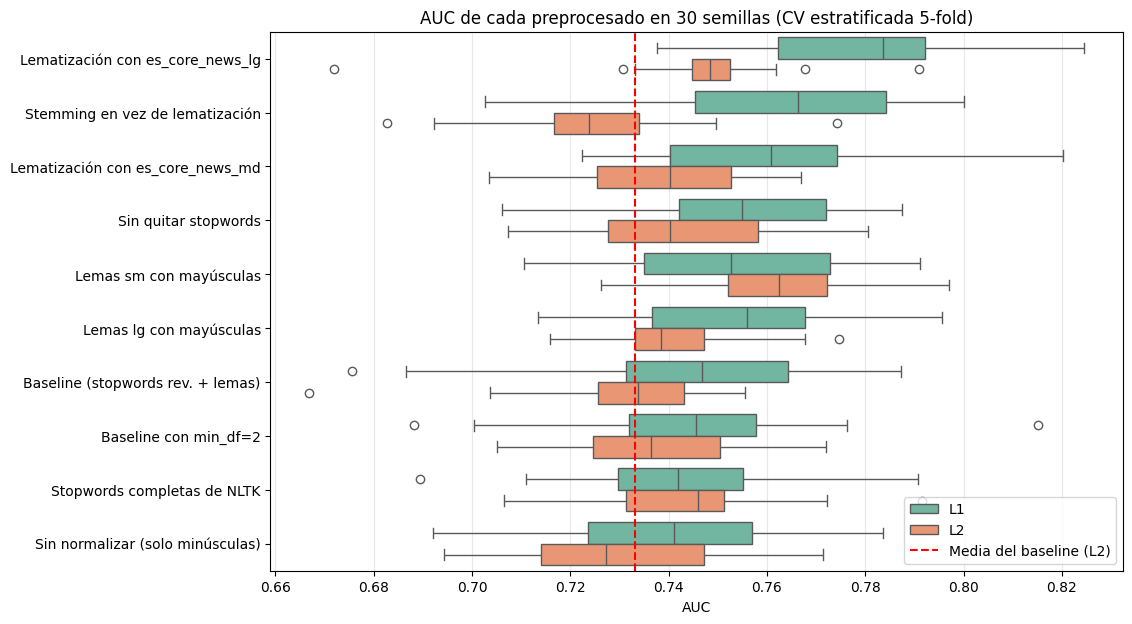

In [37]:
# Las dos mejores configuraciones con L1, comparadas semilla a semilla
# (mismas 30 particiones para las dos, así que Wilcoxon pareado)
def auc_por_semilla(preprocesado, modelo):
    sel = prepro_30[(prepro_30['Preprocesado'] == preprocesado) & (prepro_30['Modelo'] == modelo)]
    return sel.sort_values('Semilla').set_index('Semilla')

comparaciones = [
    ('Lematización con es_core_news_lg', 'Stemming en vez de lematización', 'L1'),
    ('Lematización con es_core_news_lg', 'Lematización con es_core_news_md', 'L1'),
    ('Lematización con es_core_news_lg', 'Baseline (stopwords rev. + lemas)', 'L1'),
    ('Lematización con es_core_news_lg', 'Stopwords completas de NLTK', 'L2'),
    ('Lematización con es_core_news_lg', 'Baseline (stopwords rev. + lemas)', 'L2'),
    ('Stemming en vez de lematización', 'Baseline (stopwords rev. + lemas)', 'L2'),
    ('Lemas sm con mayúsculas', 'Baseline (stopwords rev. + lemas)', 'L2'),
    ('Lemas sm con mayúsculas', 'Baseline (stopwords rev. + lemas)', 'L1'),
    ('Lemas lg con mayúsculas', 'Lematización con es_core_news_lg', 'L1'),
    ('Lemas lg con mayúsculas', 'Lematización con es_core_news_lg', 'L2'),
    ('Lematización con es_core_news_lg', 'Lemas sm con mayúsculas', 'L1'),
]
filas = []
for a, b, modelo in comparaciones:
    for metrica in ['AUC', 'F1']:
        va, vb = auc_por_semilla(a, modelo)[metrica], auc_por_semilla(b, modelo)[metrica]
        filas.append({'Modelo': modelo, 'Comparación': f'{a}  vs  {b}', 'Métrica': metrica,
                      'Diferencia media': (va - vb).mean(),
                      'Semillas en las que gana la 1ª': f'{(va > vb).sum()} de {len(va)}',
                      'p-valor (Wilcoxon)': stats.wilcoxon(va, vb).pvalue})
display(pd.DataFrame(filas).style.format({'Diferencia media': '{:+.3f}',
                                          'p-valor (Wilcoxon)': lambda p: '< 0.0001' if p < 0.0001 else f'{p:.4f}'}).hide(axis='index'))

# Gráfico: AUC de cada preprocesado en las 30 semillas, separado por L1 / L2
orden = (prepro_30[prepro_30['Modelo'] == 'L1'].groupby('Preprocesado')['AUC']
         .mean().sort_values(ascending=False).index)
plt.figure(figsize=(11, 7))
sns.boxplot(data=prepro_30, y='Preprocesado', x='AUC', hue='Modelo', order=orden, palette='Set2')
plt.axvline(prepro_30.query("Preprocesado == 'Baseline (stopwords rev. + lemas)' and Modelo == 'L2'")['AUC'].mean(),
            color='red', linestyle='--', label='Media del baseline (L2)')
plt.title('AUC de cada preprocesado en 30 semillas (CV estratificada 5-fold)')
plt.ylabel('')
plt.legend(loc='lower right')
plt.grid(axis='x', alpha=0.3)
plt.show()


Esto cambia la decisión de arriba:

* **Con L1 gana la lematización con `es_core_news_lg`**: AUC = 0.778 ± 0.021, frente
  a 0.765 del stemming y 0.761 de `md`. Le gana al stemming en 26 de las 30 semillas
  (p < 0.0001) y a L1 con el preprocesado del baseline en las 30.
* En F1, `lg` y el stemming empatan (0.695 frente a 0.696, p = 0.73).
* **Con L2, `lg` (0.747) mejora al baseline (0.733) en 29 de 30 semillas, pero no
  es la primera**: con L2 la mejor es "Lemas sm con mayúsculas" (0.763), que comentamos
  en el punto siguiente. Además, con L2 el stemming pasa a ser **el peor de todos** (0.725),
  por debajo incluso del baseline: pierde contra él en 25 de 30 semillas (p < 0.0001). O sea, la ventaja del stemming
  del apartado 6 solo existía con L1 y con la partición de `random_state=42`.
* **Mantener las mayúsculas** depende del lematizador. Con lemas `sm` y L2 mejora
  mucho respecto al baseline: de 0.733 a 0.763, y gana en las 30 semillas (p < 0.0001).
  Eso puede explicar por qué a mi compañera le subía bastante el AUC, y con una sola
  partición la mejora puede parecer incluso mayor de lo que es. Pero con lemas `lg`
  las mayúsculas **empeoran** (de 0.778 a 0.752 con L1, pierde en 29 de 30 semillas),
  y el mejor modelo con mayúsculas (`sm` + L2, 0.763) se queda por debajo de `lg` en
  minúsculas con L1 (0.778). Mi hipótesis (no lo he comprobado) es que el modelo `sm` lematiza peor muchas
  palabras en minúsculas (siglas como HER2 o RT, nombres de fármacos...) y las
  mayúsculas le ayudan a reconocerlas, mientras que `lg` ya las reconoce bien y las
  mayúsculas solo parten la misma palabra en dos columnas ("Mama" y "mama").
* Con L2, `lg` y las stopwords completas de NLTK están prácticamente empatadas
  (+0.003, p = 0.07).
* L1 le gana a L2 en todos los preprocesados menos con las stopwords completas, donde
  empatan (0.743 frente a 0.744), y con lemas `sm` con mayúsculas, donde gana L2.
* Las medias salen más altas que en la tabla del apartado 6 (por ejemplo, L1 con el preprocesado del baseline:
  0.746 frente a 0.702) porque `random_state=42` era de las particiones más
  desfavorables, como ya vimos en el 5.1.

**Decisión**: cambio de opinión respecto al apartado 6 y me quedo con la
**lematización con `es_core_news_lg`** para los n-gramas y para el resto de
algoritmos. Con L1 es la mejor de todas (0.778), por encima también de la mejor opción con L2
(lemas `sm` con mayúsculas, 0.763). Con L2 no es la primera, pero mejora claramente al
baseline, y con 30 semillas la diferencia con el stemming es clara. Con una sola partición habría elegido mal, que es
justo lo que nos avisaba el apartado 5.1.

### 6.3 ¿Nos afectaba la fuga del `CountVectorizer`?

Hasta el 6.1 (y también en los apartados 7 y 8) construimos la matriz BoW con los 239
textos **antes** de la validación cruzada. Eso es una pequeña fuga de información: los
pacientes de test ayudan a decidir qué palabras entran en el vocabulario (por el
`min_df=5` y el `max_df=0.8`), aunque nunca se usa su etiqueta.

Como en el 6.2 ya usamos el Pipeline, podemos comparar el baseline con y sin fuga en
las mismas 30 semillas y ver si nos estaba inflando los resultados.

In [38]:
# Mismo baseline, mismas 30 semillas y mismos 5 folds, con y sin fuga:
#  - "con fuga": la matriz X del apartado 4, con el vocabulario sacado de los 239 textos
#  - "sin fuga": el Pipeline del apartado 6.2, que saca el vocabulario solo del train de cada fold
filas = []
for etiqueta, con_fuga in [('L1', l1_vs_l2[('AUC', 'L1')]), ('L2', l1_vs_l2[('AUC', 'L2')])]:
    sin_fuga = auc_por_semilla('Baseline (stopwords rev. + lemas)', etiqueta)['AUC']
    filas.append({'Modelo': etiqueta,
                  'AUC con fuga': con_fuga.mean(), 'AUC sin fuga': sin_fuga.mean(),
                  'Diferencia (con - sin)': (con_fuga - sin_fuga).mean(),
                  'p-valor (Wilcoxon)': stats.wilcoxon(con_fuga.values, sin_fuga.values).pvalue})
display(pd.DataFrame(filas).style.format({'AUC con fuga': '{:.3f}', 'AUC sin fuga': '{:.3f}',
                                          'Diferencia (con - sin)': '{:+.4f}',
                                          'p-valor (Wilcoxon)': lambda p: '< 0.0001' if p < 0.0001 else f'{p:.4f}'}).hide(axis='index'))


Modelo,AUC con fuga,AUC sin fuga,Diferencia (con - sin),p-valor (Wilcoxon)
L1,0.745,0.746,-0.0003,0.5963
L2,0.731,0.733,-0.0017,0.0803


La fuga no nos estaba inflando nada: la diferencia es de milésimas, va incluso al
revés (sin fuga sale un pelín mejor) y no es significativa (p = 0.60 con L1 y
p = 0.08 con L2). Tiene sentido, porque la fuga no usa etiquetas y lo único que hace
es cambiar alguna palabra que está justo en el límite del `min_df=5`.

Por eso dejo las tablas rápidas de una sola partición de los apartados 7 y 8 como
estaban (matriz construida antes de la validación cruzada). Todo lo que medimos con 30
semillas a partir de aquí (7.1, 7.2, 7.3 y todo el 8 desde el 8.1) ya va con el
Pipeline, que es lo correcto.

### 6.4 ¿Y la puntuación?

Repasando los pasos del preprocesado, hay uno que nunca hemos puesto a prueba: quitar los signos
de puntuación. Lo hicimos porque era lo de por defecto, pero en texto clínico hay cosas como
"Ki-67", "HER2+" o "R-B" donde el signo está dentro de la palabra, así que puede que importe.
Lo comprobamos sobre el preprocesado ganador del 6.2 (lemas `lg`), con L1 y L2 y 30 semillas.

In [39]:
# Mismo preprocesado que el ganador (stopwords revisadas + minúsculas + lemas lg),
# pero SIN el paso de quitar los signos de puntuación.
# Ojo: CountVectorizer usa por defecto token_pattern = r"(?u)\b\w\w+\b", es decir,
# solo se queda con "palabras" de 2 o más letras/números. Eso hace que:
#   - los signos sueltos (".", ",", "(") desaparezcan igual aunque no los quitemos
#   - lo que cambia de verdad son las palabras con signos DENTRO:
#       con remove_punctuation:  "Ki-67" -> "ki67"   "HER2+" -> "her2"   "R-B" -> "rb"
#       sin remove_punctuation:  "Ki-67" -> "ki", "67"          "R-B" -> (se pierde, son 2 letras sueltas)
formato_p = lambda p: '< 0.0001' if p < 0.0001 else f'{p:.4f}'
textos_lg = textos_por_config['Lematización con es_core_news_lg']

nlp = spacy.load('es_core_news_lg')
def preprocesar_con_puntuacion(serie_textos):
    palabras = serie_textos.apply(tokenize_words)
    palabras = palabras.apply(lambda lista: [p for p in lista if p.lower() not in stopwords_revisadas])
    palabras = palabras.apply(minusculas)          # sin remove_punctuation
    palabras = palabras.apply(lematizacion)
    return palabras.apply(lambda lista: ' '.join(lista))
textos_con_puntuacion = preprocesar_con_puntuacion(df_clasbin['TEXTO'])
nlp = spacy.load('es_core_news_sm')

# Cómo queda un ejemplo con cada opción
vec_tmp = CountVectorizer()
print("Paciente 0 quitando puntuación:   ", vec_tmp.build_analyzer()(textos_lg.iloc[0])[:18])
print("Paciente 0 sin quitar puntuación: ", vec_tmp.build_analyzer()(textos_con_puntuacion.iloc[0])[:18])

filas = []
for nombre, textos in [('Quitando puntuación (el que teníamos)', textos_lg),
                       ('Sin quitar puntuación', textos_con_puntuacion)]:
    for etiqueta, modelo in [('L1', modelo_L1), ('L2', modelo_L2)]:
        pipe = make_pipeline(CountVectorizer(min_df=5, max_df=0.8), modelo)
        for semilla in semillas:
            r = cross_validate(pipe, textos, y, scoring={'F1': 'f1', 'AUC': 'roc_auc'},
                               cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=semilla))
            filas.append({'Puntuación': nombre, 'Modelo': etiqueta, 'Semilla': semilla,
                          'AUC': r['test_AUC'].mean(), 'F1': r['test_F1'].mean()})
puntuacion_30 = pd.DataFrame(filas)

filas = []
for etiqueta in ['L1', 'L2']:
    a = puntuacion_30.query("Modelo == @etiqueta and Puntuación == 'Quitando puntuación (el que teníamos)'").sort_values('Semilla')
    b = puntuacion_30.query("Modelo == @etiqueta and Puntuación == 'Sin quitar puntuación'").sort_values('Semilla')
    filas.append({'Modelo': etiqueta,
                  'AUC quitando puntuación': f"{a['AUC'].mean():.3f} ± {a['AUC'].std():.3f}",
                  'AUC sin quitarla': f"{b['AUC'].mean():.3f} ± {b['AUC'].std():.3f}",
                  'Diferencia (sin - con)': f"{(b['AUC'].values - a['AUC'].values).mean():+.3f}",
                  'Gana "sin quitar"': f"{(b['AUC'].values > a['AUC'].values).sum()} de 30",
                  'p-valor (Wilcoxon)': formato_p(stats.wilcoxon(b['AUC'].values, a['AUC'].values).pvalue)})
display(pd.DataFrame(filas).style.hide(axis='index'))

[Salida eliminada en la versión pública: mostraba fragmentos de las notas clínicas]


Modelo,AUC quitando puntuación,AUC sin quitarla,Diferencia (sin - con),"Gana ""sin quitar""",p-valor (Wilcoxon)
L1,0.778 ± 0.021,0.771 ± 0.023,-0.008,11 de 30,0.0155
L2,0.747 ± 0.018,0.743 ± 0.017,-0.004,12 de 30,0.1981


Quitar la puntuación sale algo mejor con L1 (0.778 frente a 0.771; gana en 19 de las 30
semillas, p = 0.016) y con L2 da igual (p = 0.20). La diferencia es pequeña, y viendo el ejemplo
se entiende por qué: los signos sueltos el `CountVectorizer` ya los tiraba él solo, así que lo
único que cambia es qué pasa con palabras como "R-B" (el esquema rituximab-bendamustina), que
quitando la puntuación se queda como `rb` y sin quitarla desaparece, porque se parte en dos
letras sueltas y el vectorizador ignora las palabras de una letra.

**Decisión**: sigo quitando la puntuación, que es lo que ya teníamos y sale igual o algo mejor.

> **Modelo actual**: stopwords revisadas + quitar puntuación + minúsculas + lemas `lg` + BoW
> (`min_df=5`, `max_df=0.8`) + **RegLog L1** → AUC 0.778 ± 0.021 (30 semillas), frente a
> 0.733 del baseline.

## 7\. Añadiendo n-gramas

Hasta ahora cada columna de la matriz es una palabra suelta, así que el modelo no
distingue entre "neoplasia sincrónica" y las dos palabras por separado en frases
distintas. Con `ngram_range` le decimos a `CountVectorizer` que además de palabras
sueltas construya secuencias de dos (bigramas) y tres (trigramas) palabras
consecutivas.

La idea es que expresiones como "segunda neoplasia" o "doble primario" tienen
mucho más significado juntas que sueltas. La pega es que el vocabulario se
dispara, y con 239 pacientes eso puede salir caro.

In [40]:
# Partimos de la configuración ganadora del apartado 6.2 (lematización con es_core_news_lg)
textos_mejor = textos_por_config['Lematización con es_core_news_lg']

resultados_ngramas = []

# ngram_range=(1,1) → solo palabras sueltas (unigramas)
# ngram_range=(1,2) → palabras + bigramas
# ngram_range=(1,3) → palabras + bigramas + trigramas
for rango, nombre in [((1, 1), 'Solo palabras'),
                      ((1, 2), 'Palabras + bigramas'),
                      ((1, 3), 'Palabras + bigramas + trigramas')]:
    vec_ng = CountVectorizer(min_df=5, max_df=0.8, ngram_range=rango)
    X_ng = vec_ng.fit_transform(textos_mejor)

    for etiqueta, modelo in [('L1', modelo_L1), ('L2', modelo_L2)]:
        resultados_ngramas.append(evaluar_modelo(modelo, X_ng, y, f'{nombre} — {etiqueta}'))

display(tabla_resultados(resultados_ngramas))

# Curiosidad: ¿qué bigramas y trigramas ha encontrado que pasen el filtro min_df=5?
vec_ng = CountVectorizer(min_df=5, max_df=0.8, ngram_range=(2, 3))
vec_ng.fit(textos_mejor)
print(f"\nBigramas y trigramas que aparecen en 5 o más informes: {len(vec_ng.get_feature_names_out())}")
print(list(vec_ng.get_feature_names_out())[:25])


Modelo,Nº features,Precision,Recall,F1,AUC
Solo palabras — L1,666,0.6990,0.6102,0.6516,0.7438
Palabras + bigramas — L1,989,0.6827,0.6017,0.6396,0.7402
Palabras + bigramas + trigramas — L1,1040,0.6827,0.6017,0.6396,0.7397
Palabras + bigramas + trigramas — L2,1040,0.6348,0.6186,0.6266,0.7262
Palabras + bigramas — L2,989,0.6372,0.6102,0.6234,0.7256
Solo palabras — L2,666,0.6579,0.6356,0.6466,0.7212



Bigramas y trigramas que aparecen en 5 o más informes: 374
['100 ki67', '100 rp', '100 rp 100', '11 cm', '12 cm', '12 mm', '13 mm', '15 mm', '1ª línea', '2019 con', '2021 carcinoma', '2021 progresión', '2022 progresión', '2023 iniciar', '2023 progresión', '2024 iniciar', '2024 progresión', '25 mm', '30 her2', '51 año', '54 año', '57 año', '58 año', '64 año', '65 año']


Aquí la conclusión es bastante clara: **los n-gramas no aportan nada**.

* Con L1, que es el mejor modelo, añadir bigramas baja el AUC (0.744 → 0.740) y el F1
  (0.652 → 0.640), y con trigramas se queda igual que con bigramas.
* Con L2 el AUC sube un pelín (0.721 → 0.726), pero sigue por debajo de L1 con palabras
  sueltas.
* Las diferencias son tan pequeñas que, con 239 pacientes, perfectamente podrían
  ser ruido del reparto en folds.

¿Por qué no funciona? Pues porque pasamos de 666 a 1040 columnas y solo ganamos
unas pocas secuencias que además repiten información que el modelo ya tenía con
las palabras sueltas. Con un corpus tan pequeño, un bigrama tiene que aparecer en
bastantes informes para que el filtro `min_df=5` lo deje pasar, y si miramos la
lista de los que sobreviven la mayoría son cosas como "51 año", "12 mm" o
"2023 iniciar": edades, medidas y fechas que no distinguen a un paciente con un
tumor de uno con varios. Los bigramas que de verdad nos interesarían
("segunda neoplasia", "doble primario") son demasiado raros y el filtro se los
carga antes de llegar al modelo.

**Decisión**: me quedo con palabras sueltas, que además es más interpretable.

### 7.1 ¿Y con 30 semillas?

La tabla de arriba sale otra vez de una sola partición. Igual que hicimos con el
preprocesado en el 6.2, repetimos la comparación de n-gramas sobre el modelo
ganador (lemas `lg`) en las mismas 30 semillas, con el `CountVectorizer` dentro del
Pipeline, y comparamos cada opción contra "solo palabras" con Wilcoxon pareado.

In [41]:
# N-gramas con 30 semillas sobre el modelo ganador (lemas lg + L1), y también con L2.
# Igual que en el 6.2: CountVectorizer dentro del Pipeline y mismas 30 particiones.
guardado = cargar('7_1_ngramas_30')
if guardado is not None:
    ngramas_30 = guardado
else:
    filas = []
    for rango, nombre in [((1, 1), 'Solo palabras'),
                          ((1, 2), 'Palabras + bigramas'),
                          ((1, 3), 'Palabras + bigramas + trigramas')]:
        for etiqueta, modelo in [('L1', modelo_L1), ('L2', modelo_L2)]:
            pipe = make_pipeline(CountVectorizer(min_df=5, max_df=0.8, ngram_range=rango), modelo)
            for semilla in semillas:
                cv_semilla = StratifiedKFold(n_splits=5, shuffle=True, random_state=semilla)
                r = cross_validate(pipe, textos_mejor, y, cv=cv_semilla, scoring={'F1': 'f1', 'AUC': 'roc_auc'})
                filas.append({'Representación': nombre, 'Modelo': etiqueta, 'Semilla': semilla,
                              'F1': r['test_F1'].mean(), 'AUC': r['test_AUC'].mean()})
    ngramas_30 = pd.DataFrame(filas)
    guardar('7_1_ngramas_30', ngramas_30)

# Cada representación contra "Solo palabras", semilla a semilla (Wilcoxon pareado)
formato_p = lambda p: '< 0.0001' if p < 0.0001 else f'{p:.4f}'
filas = []
for etiqueta in ['L1', 'L2']:
    base = ngramas_30.query("Modelo == @etiqueta and Representación == 'Solo palabras'").sort_values('Semilla')
    for nombre in ['Solo palabras', 'Palabras + bigramas', 'Palabras + bigramas + trigramas']:
        otra = ngramas_30.query("Modelo == @etiqueta and Representación == @nombre").sort_values('Semilla')
        fila = {'Modelo': etiqueta, 'Representación': nombre,
                'AUC': f"{otra['AUC'].mean():.3f} ± {otra['AUC'].std():.3f}",
                'F1': f"{otra['F1'].mean():.3f} ± {otra['F1'].std():.3f}"}
        if nombre != 'Solo palabras':
            dif = otra['AUC'].values - base['AUC'].values
            fila['Dif. AUC vs solo palabras'] = f'{dif.mean():+.3f}'
            fila['p-valor (Wilcoxon, AUC)'] = formato_p(stats.wilcoxon(otra['AUC'].values, base['AUC'].values).pvalue)
        filas.append(fila)
display(pd.DataFrame(filas).fillna('').style.hide(axis='index'))


Modelo,Representación,AUC,F1,Dif. AUC vs solo palabras,"p-valor (Wilcoxon, AUC)"
L1,Solo palabras,0.778 ± 0.021,0.695 ± 0.026,,
L1,Palabras + bigramas,0.775 ± 0.022,0.693 ± 0.025,-0.004,0.0001
L1,Palabras + bigramas + trigramas,0.774 ± 0.022,0.692 ± 0.025,-0.004,< 0.0001
L2,Solo palabras,0.747 ± 0.018,0.666 ± 0.022,,
L2,Palabras + bigramas,0.741 ± 0.018,0.661 ± 0.019,-0.006,< 0.0001
L2,Palabras + bigramas + trigramas,0.741 ± 0.018,0.663 ± 0.020,-0.006,< 0.0001


Con 30 semillas se confirma lo de antes, y además se ve que los n-gramas no solo no
ayudan sino que **empeoran un poco**:

* Con L1 el AUC baja de 0.778 a 0.775 con bigramas y a 0.774 con trigramas. Es poco
  (unas 4 milésimas), pero pasa en casi todas las semillas (p < 0.001).
* Con L2 pasa lo mismo (0.747 → 0.741).
* Con la partición de `random_state=42` parecía que con L2 los bigramas subían un
  pelín el AUC, y con 30 semillas se ve que no. Otra vez la misma lección que en el
  5.1 y el 6.2.

**Decisión**: confirmo palabras sueltas.

### 7.2 ¿Y con TF-IDF?

En clase también vimos TF-IDF, que en vez de contar cuántas veces sale cada palabra le da más
peso a las que son frecuentes en un informe pero raras en el resto. El enunciado (apartado 4)
pide aplicarla manteniendo la mejor configuración que tenemos y los modelos L1 y L2, y decidir si
cambiar la ponderación aporta una mejora consistente. Así que lo probamos con el mejor preprocesado
(lemas `lg`), L1 y L2 y las mismas 30 semillas.

In [42]:
from sklearn.feature_extraction.text import TfidfVectorizer

# BoW frente a TF-IDF sobre el mejor preprocesado (lemas lg), con L1 y L2, en las
# mismas 30 semillas y con el vectorizador dentro del Pipeline.
# Ojo: TF-IDF normaliza cada documento (los valores pasan a estar entre 0 y 1),
# así que la misma C no castiga igual que con conteos. Para no comparar con
# ventaja, probamos también C = 3 y C = 10 en las dos representaciones.
guardado = cargar('7_2_tfidf_30')
if guardado is not None:
    tfidf_30 = guardado
else:
    filas = []
    for nombre_rep, Vec in [('BoW', CountVectorizer), ('TF-IDF', TfidfVectorizer)]:
        for etiqueta in ['L1', 'L2']:
            for C in [1, 3, 10]:
                modelo = LogisticRegression(penalty=etiqueta.lower(), C=C, solver='liblinear',
                                            max_iter=1000, random_state=42)
                pipe = make_pipeline(Vec(min_df=5, max_df=0.8), modelo)
                for semilla in semillas:
                    r = cross_validate(pipe, textos_mejor, y, scoring={'F1': 'f1', 'AUC': 'roc_auc'},
                                       cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=semilla))
                    filas.append({'Representación': nombre_rep, 'Modelo': etiqueta, 'C': C, 'Semilla': semilla,
                                  'AUC': r['test_AUC'].mean(), 'F1': r['test_F1'].mean()})
    tfidf_30 = pd.DataFrame(filas)
    guardar('7_2_tfidf_30', tfidf_30)

tabla = (tfidf_30.groupby(['Modelo', 'C', 'Representación'])['AUC'].mean().unstack().round(3))
tabla['Dif. (TF-IDF - BoW)'] = tabla['TF-IDF'] - tabla['BoW']
display(tabla)

# Lo mejor de cada representación, comparado semilla a semilla
mejor_bow = tfidf_30.query("Representación == 'BoW' and Modelo == 'L1' and C == 1").sort_values('Semilla')['AUC'].values
mejor_tfidf_conf = tfidf_30[tfidf_30['Representación'] == 'TF-IDF'].groupby(['Modelo', 'C'])['AUC'].mean().idxmax()
mejor_tfidf = tfidf_30[(tfidf_30['Representación'] == 'TF-IDF') & (tfidf_30['Modelo'] == mejor_tfidf_conf[0])
                       & (tfidf_30['C'] == mejor_tfidf_conf[1])].sort_values('Semilla')['AUC'].values
print(f"\nMejor TF-IDF ({mejor_tfidf_conf[0]}, C = {mejor_tfidf_conf[1]}): AUC = {mejor_tfidf.mean():.3f}")
print(f"BoW L1, C = 1:                AUC = {mejor_bow.mean():.3f}")
print(f"BoW gana en {(mejor_bow > mejor_tfidf).sum()} de 30 semillas "
      f"(Wilcoxon p = {formato_p(stats.wilcoxon(mejor_bow, mejor_tfidf).pvalue)})")

Representación    BoW  TF-IDF  Dif. (TF-IDF - BoW)
Modelo C                                          
L1     1        0.778   0.690               -0.088
       3        0.768   0.734               -0.034
       10       0.761   0.730               -0.031
L2     1        0.747   0.720               -0.027
       3        0.741   0.726               -0.015
       10       0.737   0.726               -0.011


Mejor TF-IDF (L1, C = 3): AUC = 0.734
BoW L1, C = 1:                AUC = 0.778
BoW gana en 30 de 30 semillas (Wilcoxon p = < 0.0001)


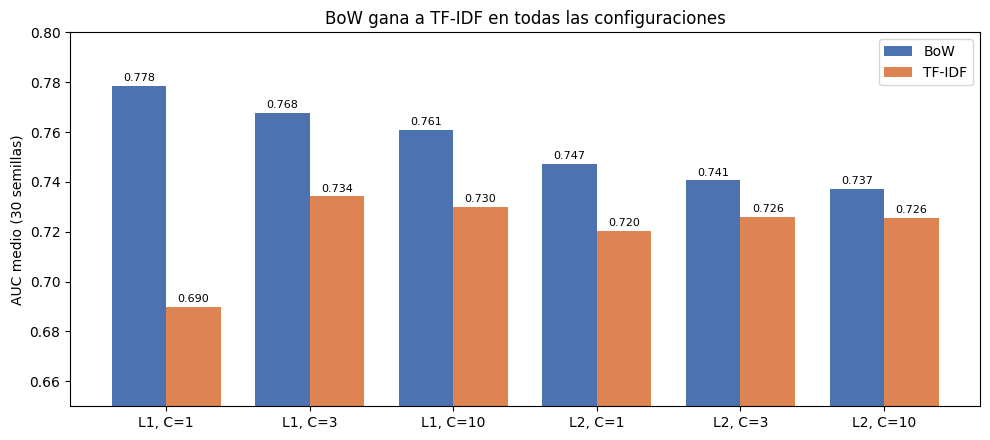

In [43]:
# Gráfica: BoW vs TF-IDF para cada modelo y cada C (media de las 30 semillas)
media_rep = tfidf_30.groupby(['Modelo', 'C', 'Representación'])['AUC'].mean().unstack()
etiquetas = [f'{m}, C={c}' for m, c in media_rep.index]
x = np.arange(len(etiquetas))
fig, ax = plt.subplots(figsize=(10, 4.5))
for k, (rep, color) in enumerate([('BoW', '#4C72B0'), ('TF-IDF', '#DD8452')]):
    barras = ax.bar(x + (k - 0.5) * 0.38, media_rep[rep], width=0.38, label=rep, color=color)
    ax.bar_label(barras, fmt='%.3f', fontsize=8, padding=2)
ax.set_xticks(x, etiquetas)
ax.set_ylim(0.65, 0.80)
ax.set_ylabel('AUC medio (30 semillas)')
ax.set_title('BoW gana a TF-IDF en todas las configuraciones')
ax.legend()
plt.tight_layout()
plt.show()

TF-IDF sale peor en **todos** los casos:

* Con la `C` por defecto la diferencia es enorme con L1 (0.690 frente a 0.778). Pero eso es en
  parte un efecto de escala: TF-IDF deja los valores entre 0 y 1, y con `C = 1` la L1 castiga
  tanto que se carga casi todas las palabras. Por eso probamos también `C = 3` y `C = 10`.
* Aun así, el mejor TF-IDF (L1 con `C = 3`: 0.734) se queda más de 4 centésimas por debajo de la
  BoW de siempre, que gana en las 30 semillas.

Mi hipótesis (no la he comprobado) es que aquí las palabras que más ayudan (`neoplasia`,
`sincrónico`, los órganos...) no son raras, y que se repitan sí que dice algo: si
"carcinoma" sale muchas veces en un informe es más probable que haya más de uno. Justo eso es lo
que TF-IDF penaliza.

**Decisión**: me quedo con BoW de conteos.

#### ¿Hay que volver a revisar las stopwords con TF-IDF?

Antes de dar TF-IDF por descartado hay una pega que me parece razonable, y que además el enunciado
pide comprobar. El IDF ya le baja el peso a las palabras que salen en casi todos los informes, que
es justo lo que hacíamos "a mano" al quitar las stopwords. ¿No será que con TF-IDF quitar las
stopwords sobra, o incluso que le hemos quitado palabras que él ya sabía tratar? En el apartado 6
la decisión de quitarlas la tomamos con la BoW de conteos, y con TF-IDF no tiene por qué salir igual.

Así que repetimos lo de arriba con los mismos lemas `lg`, pero **sin quitar las stopwords**, y
comparamos cada configuración con la misma quitándolas, semilla a semilla. Antes miramos cuántas
stopwords llegan de verdad a la matriz, porque el `max_df=0.8` ya tira por su cuenta las palabras
que salen en casi todos los informes.

In [44]:
# ¿Hay que revisar las stopwords con TF-IDF? El IDF ya le baja el peso a las palabras que salen
# en casi todos los informes, que es justo lo que hacíamos "a mano" al quitar las stopwords.
# Repetimos el 7.2 con los mismos lemas lg, pero esta vez SIN quitar las stopwords.
nlp = spacy.load('es_core_news_lg')
textos_lg_con_stop = preprocesar(df_clasbin['TEXTO'], quitar_stopwords=False)
nlp = spacy.load('es_core_news_sm')

# Antes de nada: ¿cuántas stopwords llegan de verdad a la matriz? Con max_df=0.8 el propio
# vectorizador ya tira las palabras que salen en más del 80% de los informes.
vec = TfidfVectorizer(min_df=5, max_df=0.8).fit(textos_lg_con_stop)
stop_dentro = sorted(set(vec.get_feature_names_out()) & stopwords_revisadas)
print(f"Vocabulario sin quitar stopwords: {len(vec.get_feature_names_out())} palabras")
print(f"Stopwords que entran en el vocabulario: {len(stop_dentro)}")
print(textwrap.fill(', '.join(stop_dentro), width=100))
vocab_sin_max_df = CountVectorizer(min_df=5).fit(textos_lg_con_stop).get_feature_names_out()
tiradas_max_df = sorted(set(vocab_sin_max_df) - set(vec.get_feature_names_out()))
print(f"\nPalabras que tira el max_df=0.8 por salir en más del 80% de los informes: {tiradas_max_df}\n")

guardado = cargar('7_2_tfidf_con_stop_30')
if guardado is not None:
    tfidf_con_stop_30 = guardado
else:
    # Mismo experimento que en el 7.2 (L1 y L2, C = 1, 3 y 10, 30 semillas), solo con TF-IDF
    filas = []
    for etiqueta in ['L1', 'L2']:
        for C in [1, 3, 10]:
            modelo = LogisticRegression(penalty=etiqueta.lower(), C=C, solver='liblinear',
                                        max_iter=1000, random_state=42)
            pipe = make_pipeline(TfidfVectorizer(min_df=5, max_df=0.8), modelo)
            for semilla in semillas:
                r = cross_validate(pipe, textos_lg_con_stop, y, scoring={'F1': 'f1', 'AUC': 'roc_auc'},
                                   cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=semilla))
                filas.append({'Modelo': etiqueta, 'C': C, 'Semilla': semilla,
                              'AUC': r['test_AUC'].mean(), 'F1': r['test_F1'].mean()})
    tfidf_con_stop_30 = pd.DataFrame(filas)
    guardar('7_2_tfidf_con_stop_30', tfidf_con_stop_30)

# Cada configuración contra la misma con las stopwords quitadas (la del 7.2), semilla a semilla
filas = []
for etiqueta in ['L1', 'L2']:
    for C in [1, 3, 10]:
        quitando = tfidf_30.query("Representación == 'TF-IDF' and Modelo == @etiqueta and C == @C").sort_values('Semilla')['AUC'].values
        sin_quitar = tfidf_con_stop_30.query("Modelo == @etiqueta and C == @C").sort_values('Semilla')['AUC'].values
        filas.append({'Modelo': etiqueta, 'C': C,
                      'TF-IDF quitando stopwords (7.2)': f"{quitando.mean():.3f}",
                      'TF-IDF sin quitar stopwords': f"{sin_quitar.mean():.3f} ± {sin_quitar.std(ddof=1):.3f}",
                      'Diferencia': f"{(sin_quitar - quitando).mean():+.3f}",
                      'Gana sin quitarlas': f"{(sin_quitar > quitando).sum()} de 30",
                      'p-valor (Wilcoxon)': formato_p(stats.wilcoxon(sin_quitar, quitando).pvalue)})
display(pd.DataFrame(filas).style.hide(axis='index'))

# Y el mejor TF-IDF sin stopwords contra la BoW de siempre (L1, C = 1)
mejor_conf = tfidf_con_stop_30.groupby(['Modelo', 'C'])['AUC'].mean().idxmax()
mejor_sin_quitar = tfidf_con_stop_30.query("Modelo == @mejor_conf[0] and C == @mejor_conf[1]").sort_values('Semilla')['AUC'].values
print(f"\nMejor TF-IDF sin quitar stopwords ({mejor_conf[0]}, C = {mejor_conf[1]}): AUC = {mejor_sin_quitar.mean():.3f}")
print(f"BoW L1, C = 1 (quitando stopwords):          AUC = {mejor_bow.mean():.3f}")
print(f"BoW gana en {(mejor_bow > mejor_sin_quitar).sum()} de 30 semillas "
      f"(Wilcoxon p = {formato_p(stats.wilcoxon(mejor_bow, mejor_sin_quitar).pvalue)})")


Vocabulario sin quitar stopwords: 692 palabras
Stopwords que entran en el vocabulario: 22
al, ante, como, del, durante, el, estar, este, mi, mucho, más, ni, otro, para, pero, por, que,
sobre, su, uno, ya, él

Palabras que tira el max_df=0.8 por salir en más del 80% de los informes: ['con', 'de', 'en']



Modelo,C,TF-IDF quitando stopwords (7.2),TF-IDF sin quitar stopwords,Diferencia,Gana sin quitarlas,p-valor (Wilcoxon)
L1,1,0.690,0.675 ± 0.016,-0.014,0 de 30,< 0.0001
L1,3,0.734,0.701 ± 0.027,-0.034,0 de 30,< 0.0001
L1,10,0.730,0.698 ± 0.029,-0.033,0 de 30,< 0.0001
L2,1,0.720,0.713 ± 0.018,-0.007,7 de 30,0.0002
L2,3,0.726,0.720 ± 0.019,-0.006,7 de 30,0.0005
L2,10,0.726,0.721 ± 0.020,-0.004,9 de 30,0.0277



Mejor TF-IDF sin quitar stopwords (L2, C = 10): AUC = 0.721
BoW L1, C = 1 (quitando stopwords):          AUC = 0.778
BoW gana en 30 de 30 semillas (Wilcoxon p = < 0.0001)


**Sin quitar las stopwords, TF-IDF va peor, no mejor.** Pierde en las seis configuraciones: con
L1 unas 3 centésimas (en las 30 semillas) y con L2 menos de una centésima, pero también de forma
consistente (p < 0.03 en todas). El mejor TF-IDF sin quitarlas (L2 con `C = 10`: 0.721) queda
todavía más lejos de la BoW (0.778).

La primera parte de la salida explica por qué la idea de "el IDF ya se encarga" no funciona aquí.
Las palabras vacías que salen en casi todos los informes ("de", "en") ya las tiraba el `max_df=0.8`,
así que el IDF no llega a actuar sobre ellas. Las stopwords que se cuelan en el vocabulario son 22
palabras como "que", "para", "por" o "durante", que no salen en todos los informes y por eso el IDF
no las castiga tanto. Lo único que hacen es añadir ruido.

**Decisión**: con TF-IDF también hay que quitar las stopwords, así que la decisión del apartado 6 no
cambia. Y TF-IDF sigue por debajo de la BoW de conteos, así que **me quedo con la BoW**.

### 7.3 Ajustamos la `C` del mejor modelo

En el 5.1 ajustamos la `C` con validación cruzada anidada, pero solo para el
baseline (L2 con lemas `sm`). El modelo con el que nos hemos quedado (L1 con lemas
`lg`) sigue con `C = 1`, el valor por defecto. Antes de compararlo con otros
algoritmos intentamos mejorarlo ajustando la `C` con el mismo esquema anidado,
también con 30 semillas:

* **Bucle externo** (5 folds): mide.
* **Bucle interno** (`GridSearchCV`, 5 folds solo con el train): elige la `C`.

Probamos `C` = 0.01, 0.1, 0.3, 1, 3, 10 y 100.

In [45]:
# Validación cruzada anidada para elegir la C del modelo ganador (lemas lg + L1),
# igual que hicimos en el 5.1 con el baseline, pero ahora con el Pipeline:
#  - bucle externo: 5 folds (30 semillas) para medir
#  - bucle interno: GridSearchCV con otros 5 folds, solo con el train, para elegir C
valores_C = {'logisticregression__C': [0.01, 0.1, 0.3, 1, 3, 10, 100]}
pipe_mejor = make_pipeline(CountVectorizer(min_df=5, max_df=0.8), modelo_L1)

guardado = cargar('7_3_anidada_mejor')
if guardado is not None:
    anidada_mejor, C_elegidas_mejor = guardado
else:
    filas, C_elegidas_mejor = [], []
    for semilla in semillas:
        externa = StratifiedKFold(n_splits=5, shuffle=True, random_state=semilla)
        interna = StratifiedKFold(n_splits=5, shuffle=True, random_state=semilla + 100)
        busqueda = GridSearchCV(pipe_mejor, valores_C, cv=interna, scoring='roc_auc')
        r = cross_validate(busqueda, textos_mejor, y, cv=externa,
                           scoring={'F1': 'f1', 'AUC': 'roc_auc'}, return_estimator=True)
        C_elegidas_mejor += [m.best_params_['logisticregression__C'] for m in r['estimator']]
        filas.append({'Semilla': semilla, 'F1': r['test_F1'].mean(), 'AUC': r['test_AUC'].mean()})
    anidada_mejor = pd.DataFrame(filas)
    guardar('7_3_anidada_mejor', (anidada_mejor, C_elegidas_mejor))

# Comparamos con la C = 1 por defecto en las mismas particiones externas (6.2)
fija_mejor = auc_por_semilla('Lematización con es_core_news_lg', 'L1')
filas = []
for metrica in ['AUC', 'F1']:
    a, f = anidada_mejor[metrica].values, fija_mejor[metrica].values
    filas.append({'Métrica': metrica,
                  'C = 1 (por defecto)': f'{f.mean():.3f} ± {f.std(ddof=1):.3f}',
                  'C elegida con CV anidada': f'{a.mean():.3f} ± {a.std(ddof=1):.3f}',
                  'Diferencia (anidada - fija)': f'{(a - f).mean():+.3f}',
                  'p-valor (Wilcoxon)': formato_p(stats.wilcoxon(a, f).pvalue)})
display(pd.DataFrame(filas).style.hide(axis='index'))

print("\nValor de C elegido en los 150 folds externos:")
print(pd.Series(C_elegidas_mejor).value_counts().sort_index().to_string())


Métrica,C = 1 (por defecto),C elegida con CV anidada,Diferencia (anidada - fija),p-valor (Wilcoxon)
AUC,0.778 ± 0.021,0.765 ± 0.023,-0.013,0.0002
F1,0.695 ± 0.026,0.690 ± 0.030,-0.005,0.1026



Valor de C elegido en los 150 folds externos:
0.1       5
0.3      48
1.0      64
3.0      16
10.0     12
100.0     5


Aquí el resultado va al revés de lo que esperaba: **ajustar la `C` no mejora el
modelo, lo empeora un poco**.

* El AUC baja de 0.778 a 0.765 (p = 0.0002) y el F1 se queda prácticamente igual
  (0.695 frente a 0.690, p = 0.10).
* El bucle interno elige `C = 1` o `C = 0.3` en 112 de los 150 folds, o sea que la `C` por
  defecto ya estaba en la zona buena. Cuando se equivoca es porque elige con solo
  el 80% del train de cada fold, y con tan pocos pacientes esa elección es ruidosa.
* Esto también quiere decir que el 0.778 del 6.2 no estaba inflado: no elegimos la
  `C` mirando los resultados, la dejamos por defecto.

**Decisión**: me quedo con `C = 1`. El mejor modelo de regresión logística queda
así: **lematización con `es_core_news_lg`, minúsculas, stopwords revisadas, BoW de
palabras sueltas (`min_df=5`, `max_df=0.8`) y regresión logística L1 con `C = 1`**,
con AUC = 0.778 ± 0.021 y F1 = 0.695 ± 0.026 en 30 semillas. Este es el modelo de
referencia para comparar con el resto de algoritmos.

> **Modelo actual**: lemas `lg` + BoW + **RegLog L1** (`C = 1`) → AUC 0.778 ± 0.021, frente a
> 0.733 del baseline (+0.045).

## 8\. Ampliando a otros algoritmos

Hasta aquí todo ha sido regresión logística. Ahora, manteniendo la mejor
configuración (lematización con `es_core_news_lg` + BoW de palabras sueltas, `min_df=5`), ampliamos la
comparación a otras familias de clasificadores:

* **SVM lineal**: busca el hiperplano que separa las clases con el mayor margen
  posible. En texto suele ir muy bien porque los datos son dispersos y de
  dimensión alta.
* **SVM con kernel RBF**: lo mismo pero permitiendo fronteras no lineales.
* **Random Forest**: un montón de árboles entrenados sobre muestras y variables
  distintas, y luego se vota. Captura interacciones entre palabras que un modelo
  lineal no puede.
* **Naive Bayes multinomial**: el clásico de toda la vida para BoW. Asume que las
  palabras son independientes entre sí (lo cual es mentira, pero funciona).
* **Red neuronal (MLP)**: una capa oculta de 100 neuronas, para ver si una no
  linealidad más "general" aporta algo.

Igual que en el 6 y el 7, primero hacemos una pasada rápida con la partición de siempre
(`random_state=42`), todos evaluados exactamente igual, y luego lo comprobamos con 30
semillas en el 8.1. De momento cada algoritmo va con los valores por defecto de sklearn
(y 500 árboles en el bosque), solo para tener una primera foto: en el 8.2 ajustamos los
hiperparámetros de todos con validación cruzada anidada y en el 8.4 miramos cuántos árboles
hacen falta.

In [46]:
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.neural_network import MLPClassifier

# La representación ganadora: lematización con es_core_news_lg + palabras sueltas
vectorizer_final = CountVectorizer(min_df=5, max_df=0.8)
X_final = vectorizer_final.fit_transform(textos_mejor)
print("Dimensiones de la matriz final:", X_final.shape)

# probability=True en los SVC es para poder sacar predict_proba y calcular el AUC
modelos = {
    'RegLog L1 (Lasso)':  modelo_L1,
    'RegLog L2 (Ridge)':  modelo_L2,
    'SVM lineal':         SVC(kernel='linear', C=1.0, probability=True, random_state=42),
    'SVM kernel RBF':     SVC(kernel='rbf', C=1.0, probability=True, random_state=42),
    'Random Forest':      RandomForestClassifier(n_estimators=500, random_state=42, n_jobs=-1),
    'Naive Bayes':        MultinomialNB(alpha=1.0),
    'Red neuronal (MLP)': MLPClassifier(hidden_layer_sizes=(100,), max_iter=1000, random_state=42),
}

resultados_modelos = []
for nombre, modelo in modelos.items():
    print(f"Entrenando: {nombre} ...")
    resultados_modelos.append(evaluar_modelo(modelo, X_final, y, nombre))

display(tabla_resultados(resultados_modelos))


Dimensiones de la matriz final: (239, 666)
Entrenando: RegLog L1 (Lasso) ...
Entrenando: RegLog L2 (Ridge) ...
Entrenando: SVM lineal ...
Entrenando: SVM kernel RBF ...
Entrenando: Random Forest ...
Entrenando: Naive Bayes ...
Entrenando: Red neuronal (MLP) ...


Modelo,Nº features,Precision,Recall,F1,AUC
Random Forest,666,0.7658,0.7203,0.7424,0.8146
SVM kernel RBF,666,0.7700,0.6525,0.7064,0.8020
RegLog L1 (Lasso),666,0.6990,0.6102,0.6516,0.7438
RegLog L2 (Ridge),666,0.6579,0.6356,0.6466,0.7212
SVM lineal,666,0.6765,0.5847,0.6273,0.6982
Red neuronal (MLP),666,0.6053,0.5847,0.5948,0.6677
Naive Bayes,666,0.5920,0.6271,0.6091,0.6586


Y aquí está el salto de verdad: **Random Forest se despega del resto** con
AUC = 0.815 y F1 = 0.742, bastante por encima del baseline del principio
(AUC 0.701, F1 0.609). Detrás viene la SVM con kernel RBF (AUC 0.802).

Un par de cosas que me parecen interesantes:

* Los dos modelos que ganan son **los dos no lineales**. Eso sugiere que la
  información no está en "si aparece esta palabra, entonces múltiples", sino en
  combinaciones: por ejemplo, que aparezcan dos localizaciones tumorales
  distintas en el mismo informe. Un modelo lineal suma pesos y no puede capturar
  ese "y además".
* La SVM lineal va peor que la propia regresión logística L1 (AUC 0.698 frente a
  0.744), lo cual encaja con lo anterior: siendo lineal, no gana nada y encima no
  hace selección de variables.
* Naive Bayes es el peor (AUC 0.659). Normal, porque su hipótesis de
  independencia entre palabras es justo la que aquí no se cumple.
* La red neuronal tampoco destaca (AUC 0.668). Con 239 pacientes y 666 variables
  de entrada no tiene datos suficientes para aprender nada que no aprendan ya los
  modelos más simples.

En precision la que mejor sale es la SVM RBF (0.770), pero con un recall bastante
peor (0.653), o sea que es más conservadora: marca menos pacientes como múltiples
pero acierta más cuando lo hace. Random Forest está más equilibrado
(0.766 / 0.720), y como el coste de no detectar un segundo tumor es mayor que el
de revisar un informe de más, de momento me quedaría con Random Forest. Pero esto sale
de una sola partición, así que antes de decidir nada lo comprobamos con 30 semillas.

Un matiz: el preprocesado lo hemos elegido con regresión logística, que es lo que se
pedía, y no tiene por qué ser el mejor para todos los algoritmos (por ejemplo, al bosque
podría irle mejor el stemming). Además, aquí todo está medido con una sola partición, así
que de momento no sacamos conclusiones sobre esto: lo comprobamos con 30 semillas en el 8.5.

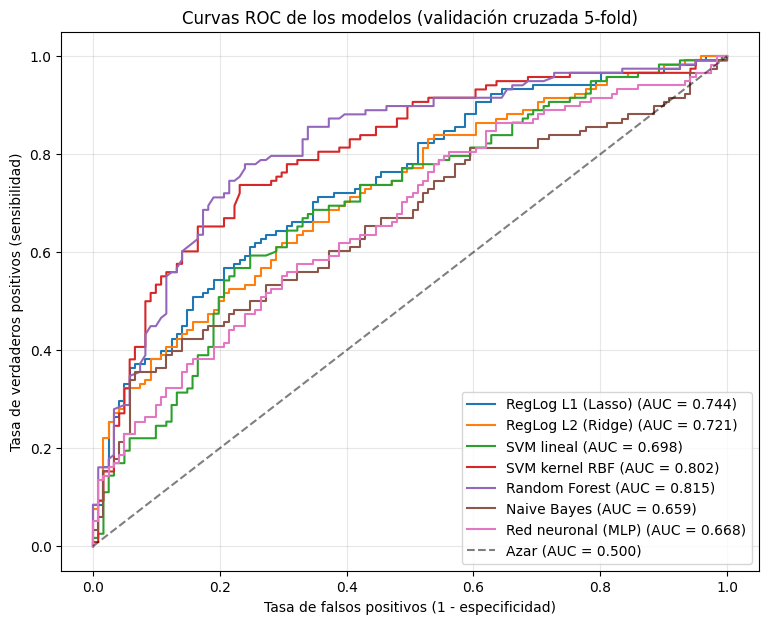

In [47]:
from sklearn.metrics import roc_curve, ConfusionMatrixDisplay

# Curva ROC de todos los modelos sobre el mismo gráfico, para verlo de un vistazo
plt.figure(figsize=(9, 7))

for nombre, modelo in modelos.items():
    y_proba = cross_val_predict(modelo, X_final, y, cv=skf, method='predict_proba')[:, 1]
    fpr, tpr, _ = roc_curve(y, y_proba)
    auc = roc_auc_score(y, y_proba)
    plt.plot(fpr, tpr, label=f'{nombre} (AUC = {auc:.3f})')

# La diagonal es el modelo que va a ciegas (AUC = 0.5)
plt.plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Azar (AUC = 0.500)')
plt.xlabel('Tasa de falsos positivos (1 - especificidad)')
plt.ylabel('Tasa de verdaderos positivos (sensibilidad)')
plt.title('Curvas ROC de los modelos (validación cruzada 5-fold)')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.show()


                          precision    recall  f1-score   support

     Única neoplasia (0)       0.74      0.79      0.76       121
Múltiples neoplasias (1)       0.77      0.72      0.74       118

                accuracy                           0.75       239
               macro avg       0.75      0.75      0.75       239
            weighted avg       0.75      0.75      0.75       239



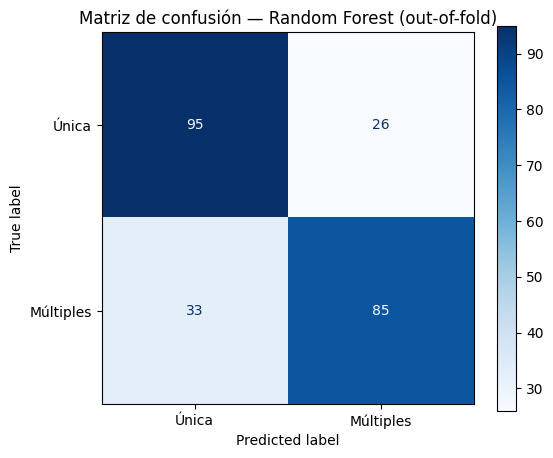

In [48]:
# Matriz de confusión del ganador, para ver dónde se equivoca exactamente
modelo_RF = modelos['Random Forest']
y_pred_rf = cross_val_predict(modelo_RF, X_final, y, cv=skf)

print(classification_report(y, y_pred_rf,
                            target_names=['Única neoplasia (0)', 'Múltiples neoplasias (1)']))

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y, y_pred_rf,
    display_labels=['Única', 'Múltiples'],
    cmap='Blues', ax=ax
)
plt.title('Matriz de confusión — Random Forest (out-of-fold)')
plt.show()


### 8.1 ¿Y con 30 semillas?

La tabla de arriba sale de una sola partición, y además de la más desfavorable para el baseline
(apartado 5.1). Ya nos ha pasado dos veces que la decisión cambia al repetir con más semillas
(el stemming en el 6.2 y los bigramas en el 7.1), así que repetimos la comparación de todos los
algoritmos con las 30 semillas, el vectorizador dentro del Pipeline y comparando cada uno contra
el mejor logístico (L1) semilla a semilla.

Modelo,AUC,F1,Precision,Recall,Dif. AUC vs L1,Gana a L1,p-valor (Wilcoxon)
Random Forest,0.827 ± 0.011,0.760 ± 0.016,0.800 ± 0.019,0.730 ± 0.019,+0.049,30 de 30,< 0.0001
SVM kernel RBF,0.805 ± 0.009,0.687 ± 0.012,0.794 ± 0.018,0.612 ± 0.015,+0.027,27 de 30,< 0.0001
RegLog L1 (Lasso),0.778 ± 0.021,0.695 ± 0.026,0.734 ± 0.029,0.669 ± 0.033,,,
RegLog L2 (Ridge),0.747 ± 0.018,0.666 ± 0.022,0.682 ± 0.025,0.659 ± 0.026,-0.031,0 de 30,< 0.0001
SVM lineal,0.743 ± 0.015,0.661 ± 0.019,0.700 ± 0.022,0.633 ± 0.023,-0.036,0 de 30,< 0.0001
Red neuronal (MLP),0.682 ± 0.022,0.620 ± 0.027,0.628 ± 0.027,0.619 ± 0.029,-0.097,0 de 30,< 0.0001
Naive Bayes,0.666 ± 0.023,0.625 ± 0.025,0.592 ± 0.024,0.669 ± 0.030,-0.112,0 de 30,< 0.0001



Random Forest vs SVM RBF: +0.022 de AUC, gana en 30 de 30 (Wilcoxon p = < 0.0001)


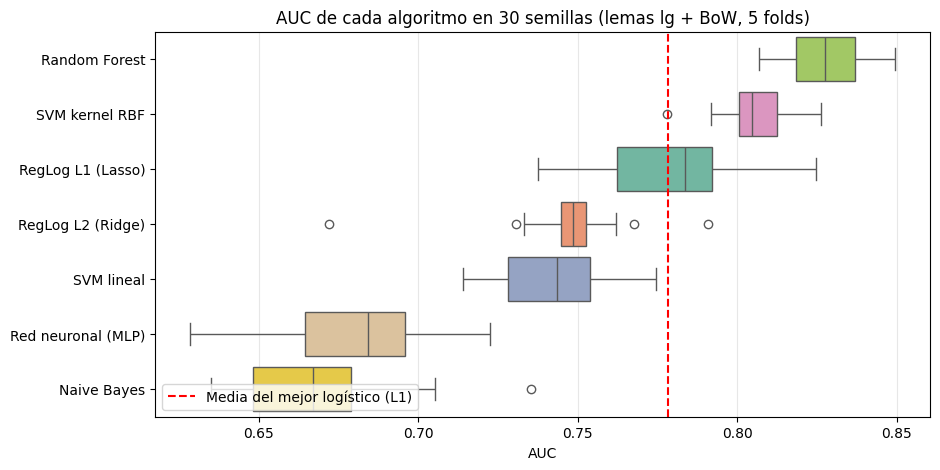

In [49]:
# Los mismos algoritmos que arriba, pero ahora:
#  - con las 30 semillas de siempre (5 folds cada una)
#  - con el CountVectorizer dentro del Pipeline (sin fuga de vocabulario)
#  - y todos con las mismas particiones, para poder compararlos semilla a semilla
scoring = {'AUC': 'roc_auc', 'F1': 'f1', 'Precision': 'precision', 'Recall': 'recall'}
guardado = cargar('8_1_algoritmos_30')
if guardado is not None:
    algoritmos_30 = guardado
else:
    filas = []
    for nombre, modelo in modelos.items():
        print(f"Evaluando con 30 semillas: {nombre} ...")
        pipe = make_pipeline(CountVectorizer(min_df=5, max_df=0.8), modelo)
        for semilla in semillas:
            r = cross_validate(pipe, textos_mejor, y, scoring=scoring, n_jobs=-1,
                               cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=semilla))
            filas.append({'Modelo': nombre, 'Semilla': semilla, **{m: r[f'test_{m}'].mean() for m in scoring}})
    algoritmos_30 = pd.DataFrame(filas)
    guardar('8_1_algoritmos_30', algoritmos_30)

# Media ± desviación, y cada modelo contra el mejor logístico (L1) semilla a semilla
ref = algoritmos_30.query("Modelo == 'RegLog L1 (Lasso)'").sort_values('Semilla')['AUC'].values
filas = []
for nombre in modelos:
    sel = algoritmos_30.query("Modelo == @nombre").sort_values('Semilla')
    fila = {'Modelo': nombre, **{m: f"{sel[m].mean():.3f} ± {sel[m].std():.3f}" for m in scoring}}
    if nombre != 'RegLog L1 (Lasso)':
        fila['Dif. AUC vs L1'] = f"{(sel['AUC'].values - ref).mean():+.3f}"
        fila['Gana a L1'] = f"{(sel['AUC'].values > ref).sum()} de 30"
        fila['p-valor (Wilcoxon)'] = formato_p(stats.wilcoxon(sel['AUC'].values, ref).pvalue)
    filas.append(fila)
tabla_81 = pd.DataFrame(filas).fillna('')
tabla_81['_orden'] = [algoritmos_30.query("Modelo == @m")['AUC'].mean() for m in tabla_81['Modelo']]
display(tabla_81.sort_values('_orden', ascending=False).drop(columns='_orden').style.hide(axis='index'))

# Random Forest contra la SVM RBF, que es la segunda
rf = algoritmos_30.query("Modelo == 'Random Forest'").sort_values('Semilla')['AUC'].values
svm = algoritmos_30.query("Modelo == 'SVM kernel RBF'").sort_values('Semilla')['AUC'].values
print(f"\nRandom Forest vs SVM RBF: {(rf - svm).mean():+.3f} de AUC, gana en {(rf > svm).sum()} de 30 "
      f"(Wilcoxon p = {formato_p(stats.wilcoxon(rf, svm).pvalue)})")

orden = algoritmos_30.groupby('Modelo')['AUC'].mean().sort_values(ascending=False).index
plt.figure(figsize=(10, 5))
sns.boxplot(data=algoritmos_30, y='Modelo', x='AUC', order=orden, hue='Modelo', palette='Set2', legend=False)
plt.axvline(ref.mean(), color='red', linestyle='--', label='Media del mejor logístico (L1)')
plt.title('AUC de cada algoritmo en 30 semillas (lemas lg + BoW, 5 folds)')
plt.ylabel('')
plt.legend(loc='lower left')
plt.grid(axis='x', alpha=0.3)
plt.show()

Esta vez la decisión de arriba se mantiene, y con más fuerza:

* **Random Forest es el mejor**: AUC 0.827 ± 0.011. Le gana al L1 en las 30 semillas (+0.049) y
  a la SVM RBF también en las 30 (+0.022). Además varía la mitad que el L1 entre semillas.
* La SVM RBF es la segunda en AUC (0.805), pero con un recall de solo 0.61: ordena bien a los
  pacientes, pero con el umbral de 0.5 se le escapan casi 4 de cada 10.
* Con 30 semillas el bosque sube de 0.815 a 0.827, otra vez porque `random_state=42` era una
  partición desfavorable.
* La red neuronal y Naive Bayes siguen siendo los peores, por debajo incluso del baseline (0.733).

Pero todos menos la regresión logística siguen con los hiperparámetros por defecto, así que
todavía no puedo decir que el RF gane "de verdad": a lo mejor una SVM bien ajustada le gana.
Eso es lo siguiente.

### 8.2 Ajustamos los hiperparámetros de todos los algoritmos

Hasta aquí la regresión logística ha tenido su `C` ajustada con validación cruzada anidada (5.1
y 7.3), pero el resto de algoritmos siguen con los valores por defecto de sklearn. Así la
comparación no es justa: a lo mejor una SVM o una red neuronal bien ajustada le gana al bosque.
Usamos el mismo esquema anidado de siempre (5 folds externos para medir, 5 internos para elegir,
30 semillas) con una rejilla para cada algoritmo. Para elegir los valores de cada rejilla:

| Algoritmo | Qué ajustamos | Por qué esos valores |
|---|---|---|
| RegLog L2 | `C` de 0.01 a 100 | La misma rejilla que en el 7.3, para poder comparar |
| SVM lineal | `C` de 0.001 a 10 | Igual que en la logística, `C` es lo que controla la regularización |
| SVM RBF | `C` (0.1-100) y `gamma` (`scale`, 0.001-0.1) | `gamma` dice lo "curvada" que puede ser la frontera; `scale` es el de por defecto |
| Random Forest | `max_features` (`sqrt`, 10%, 30%) y `min_samples_leaf` (1, 3, 5) | Cuántas palabras mira cada corte (más = árboles más fuertes pero más parecidos entre sí) y cuántos pacientes como mínimo en cada hoja (más = árboles más simples) |
| Naive Bayes | `alpha` de 0.01 a 5 | El suavizado de Laplace: cuánto "inventamos" para palabras que no salen en una clase |
| Red neuronal | neuronas (20 o 100) y `alpha` (0.0001-10) | Tamaño de la capa oculta y regularización L2 de los pesos |

El número de árboles del bosque no lo metemos aquí porque no es un hiperparámetro de los que
sobreajustan: lo miramos aparte en el 8.4.

In [50]:
# Validación cruzada anidada para TODOS los algoritmos, igual que hicimos con la C
# de la regresión logística en el 5.1 y en el 7.3:
#  - bucle externo: 5 folds x 30 semillas, para medir
#  - bucle interno: GridSearchCV con 5 folds, solo con el train, para elegir los hiperparámetros
# En las SVM quitamos probability=True: para el AUC basta con decision_function y
# así el bucle interno va mucho más rápido.
# (Esta celda tarda bastante: son 30 semillas x 5 folds x 5 folds internos x cada combinación)
rejillas = {
    'RegLog L2 (Ridge)': (LogisticRegression(penalty='l2', solver='liblinear', max_iter=1000, random_state=42),
                          {'C': [0.01, 0.1, 0.3, 1, 3, 10, 100]}),
    'SVM lineal':        (SVC(kernel='linear', random_state=42),
                          {'C': [0.001, 0.01, 0.1, 1, 10]}),
    'SVM kernel RBF':    (SVC(kernel='rbf', random_state=42),
                          {'C': [0.1, 1, 10, 100], 'gamma': ['scale', 0.001, 0.01, 0.1]}),
    'Random Forest':     (RandomForestClassifier(n_estimators=500, random_state=42),
                          {'max_features': ['sqrt', 0.1, 0.3], 'min_samples_leaf': [1, 3, 5]}),
    'Naive Bayes':       (MultinomialNB(),
                          {'alpha': [0.01, 0.1, 0.5, 1, 2, 5]}),
    'Red neuronal (MLP)': (MLPClassifier(max_iter=1000, random_state=42),
                          {'hidden_layer_sizes': [(20,), (100,)], 'alpha': [0.0001, 0.01, 1, 10]}),
}

guardado = cargar('8_2_anidada_algoritmos')
if guardado is not None:
    anidada_algoritmos, elegidos = guardado
else:
    filas, elegidos = [], []
    for nombre, (modelo, rejilla) in rejillas.items():
        print(f"CV anidada: {nombre} ...")
        paso = type(modelo).__name__.lower()          # nombre que le da make_pipeline al modelo
        rejilla_pipe = {f'{paso}__{k}': v for k, v in rejilla.items()}
        pipe = make_pipeline(CountVectorizer(min_df=5, max_df=0.8), modelo)
        for semilla in semillas:
            externa = StratifiedKFold(n_splits=5, shuffle=True, random_state=semilla)
            interna = StratifiedKFold(n_splits=5, shuffle=True, random_state=semilla + 100)
            busqueda = GridSearchCV(pipe, rejilla_pipe, cv=interna, scoring='roc_auc', n_jobs=-1)
            r = cross_validate(busqueda, textos_mejor, y, cv=externa, return_estimator=True,
                               scoring={'AUC': 'roc_auc', 'F1': 'f1'})
            filas.append({'Modelo': nombre, 'Semilla': semilla, 'AUC': r['test_AUC'].mean(), 'F1': r['test_F1'].mean()})
            elegidos += [{'Modelo': nombre, **{k.split('__')[1]: str(v) for k, v in m.best_params_.items()}}
                         for m in r['estimator']]
    anidada_algoritmos = pd.DataFrame(filas)
    elegidos = pd.DataFrame(elegidos)
    guardar('8_2_anidada_algoritmos', (anidada_algoritmos, elegidos))

# Ajustado vs por defecto (apartado 8.1), en las mismas particiones externas
filas = []
for nombre in rejillas:
    aj = anidada_algoritmos.query("Modelo == @nombre").sort_values('Semilla')['AUC'].values
    de = algoritmos_30.query("Modelo == @nombre").sort_values('Semilla')['AUC'].values
    filas.append({'Modelo': nombre,
                  'AUC por defecto': f"{de.mean():.3f} ± {de.std(ddof=1):.3f}",
                  'AUC ajustado (CV anidada)': f"{aj.mean():.3f} ± {aj.std(ddof=1):.3f}",
                  'Diferencia': f"{(aj - de).mean():+.3f}",
                  'p-valor (Wilcoxon)': formato_p(stats.wilcoxon(aj, de).pvalue)})
display(pd.DataFrame(filas).style.hide(axis='index'))

# Qué hiperparámetros elige el bucle interno en los 150 folds externos
for nombre in rejillas:
    sel = elegidos[elegidos['Modelo'] == nombre].drop(columns='Modelo').dropna(axis=1)
    print(f"\n{nombre}: combinaciones elegidas en los 150 folds externos")
    print(sel.value_counts().head(5).to_string())

Modelo,AUC por defecto,AUC ajustado (CV anidada),Diferencia,p-valor (Wilcoxon)
RegLog L2 (Ridge),0.747 ± 0.018,0.751 ± 0.020,+0.004,0.0523
SVM lineal,0.743 ± 0.015,0.785 ± 0.015,+0.042,< 0.0001
SVM kernel RBF,0.805 ± 0.009,0.797 ± 0.016,-0.008,0.0003
Random Forest,0.827 ± 0.011,0.827 ± 0.012,-0.001,0.6120
Naive Bayes,0.666 ± 0.023,0.668 ± 0.023,+0.002,0.3818
Red neuronal (MLP),0.682 ± 0.022,0.787 ± 0.017,+0.106,< 0.0001



RegLog L2 (Ridge): combinaciones elegidas en los 150 folds externos
C   
0.01    65
0.1     46
0.3     20
1        8
100      5

SVM lineal: combinaciones elegidas en los 150 folds externos
C   
0.01    126
0.1      22
1         2

SVM kernel RBF: combinaciones elegidas en los 150 folds externos
C   gamma
10  scale    47
    0.001    30
    0.01     25
1   0.01     24
    scale    12

Random Forest: combinaciones elegidas en los 150 folds externos
max_features  min_samples_leaf
0.1           3                   33
sqrt          3                   29
0.1           1                   28
sqrt          1                   28
0.3           3                   10

Naive Bayes: combinaciones elegidas en los 150 folds externos
alpha
5        101
0.01      18
0.1       13
0.5        7
2          7

Red neuronal (MLP): combinaciones elegidas en los 150 folds externos
alpha  hidden_layer_sizes
10     (100,)                147
       (20,)                   3


Lo que sacamos:

* **El Random Forest no cambia** al ajustarlo (0.827 en los dos casos, p = 0.61). El bucle interno
  va eligiendo combinaciones distintas en cada fold sin que ninguna destaque, o sea que el bosque
  está en una zona plana: sus valores por defecto ya estaban bien, y ahora lo sabemos con datos.
* **La red neuronal es la que más gana**: de 0.682 a 0.787 (+0.106). Elige casi siempre
  `alpha = 10`, la regularización más fuerte de la rejilla. Tiene sentido: con 666 entradas,
  100 neuronas y solo 190 pacientes para entrenar, sin regularizar se aprendía los pacientes de
  memoria.
* **La SVM lineal también mejora mucho** (de 0.743 a 0.785) eligiendo `C = 0.01`, es decir,
  mucha más regularización que la de por defecto. Pasa de estar por debajo del L1 a estar por
  encima.
* La SVM RBF empeora un poco al ajustarla (0.805 → 0.797). Es lo mismo que nos pasó con la `C`
  del L1 en el 7.3: el bucle interno elige con menos pacientes y su elección es ruidosa.
* L2 y Naive Bayes casi no cambian.

Hay una cosa que no me deja tranquilo: en la red neuronal, en Naive Bayes y en L2 el valor que
más se elige está en el **borde** de la rejilla (`alpha = 10`, `alpha = 5` y `C = 0.01`). Eso
quiere decir que a lo mejor el valor bueno está más allá y no lo hemos probado, así que ampliamos
la rejilla hacia ese lado antes de dar por cerrado que el bosque gana.

In [51]:
# En tres modelos el valor más elegido está en el BORDE de la rejilla (C = 0.01 en L2,
# alpha = 5 en Naive Bayes y alpha = 10 en la red neuronal), o sea que puede que el valor
# bueno de verdad esté más allá. Ampliamos la rejilla hacia ese lado y repetimos la CV anidada.
rejillas_ampliadas = {
    'RegLog L2 (Ridge)':  (rejillas['RegLog L2 (Ridge)'][0], {'C': [0.0001, 0.001, 0.003, 0.01, 0.03, 0.1]}),
    'Naive Bayes':        (MultinomialNB(), {'alpha': [2, 5, 10, 20, 50, 100]}),
    'Red neuronal (MLP)': (MLPClassifier(hidden_layer_sizes=(100,), max_iter=1000, random_state=42),
                           {'alpha': [3, 10, 30, 100]}),
}
guardado = cargar('8_2_anidada_ampliada')
if guardado is not None:
    anidada_ampliada, elegidos_amp = guardado
else:
    filas, elegidos_amp = [], []
    for nombre, (modelo, rejilla) in rejillas_ampliadas.items():
        print(f"CV anidada con la rejilla ampliada: {nombre} ...")
        paso = type(modelo).__name__.lower()
        rejilla_pipe = {f'{paso}__{k}': v for k, v in rejilla.items()}
        pipe = make_pipeline(CountVectorizer(min_df=5, max_df=0.8), modelo)
        for semilla in semillas:
            externa = StratifiedKFold(n_splits=5, shuffle=True, random_state=semilla)
            interna = StratifiedKFold(n_splits=5, shuffle=True, random_state=semilla + 100)
            busqueda = GridSearchCV(pipe, rejilla_pipe, cv=interna, scoring='roc_auc', n_jobs=-1)
            r = cross_validate(busqueda, textos_mejor, y, cv=externa, return_estimator=True,
                               scoring={'AUC': 'roc_auc', 'F1': 'f1'})
            filas.append({'Modelo': nombre, 'Semilla': semilla, 'AUC': r['test_AUC'].mean(), 'F1': r['test_F1'].mean()})
            elegidos_amp += [{'Modelo': nombre, **{k.split('__')[1]: str(v) for k, v in m.best_params_.items()}}
                             for m in r['estimator']]
    anidada_ampliada = pd.DataFrame(filas)
    elegidos_amp = pd.DataFrame(elegidos_amp)
    guardar('8_2_anidada_ampliada', (anidada_ampliada, elegidos_amp))

rf_ajustado = anidada_algoritmos.query("Modelo == 'Random Forest'").sort_values('Semilla')['AUC'].values
filas = []
for nombre in rejillas_ampliadas:
    antes = anidada_algoritmos.query("Modelo == @nombre").sort_values('Semilla')['AUC'].values
    ahora = anidada_ampliada.query("Modelo == @nombre").sort_values('Semilla')['AUC'].values
    filas.append({'Modelo': nombre,
                  'AUC rejilla original': f"{antes.mean():.3f} ± {antes.std(ddof=1):.3f}",
                  'AUC rejilla ampliada': f"{ahora.mean():.3f} ± {ahora.std(ddof=1):.3f}",
                  'Dif. vs RF ajustado': f"{(ahora - rf_ajustado).mean():+.3f}",
                  'Gana al RF': f"{(ahora > rf_ajustado).sum()} de 30",
                  'p-valor vs RF (Wilcoxon)': formato_p(stats.wilcoxon(ahora, rf_ajustado).pvalue)})
display(pd.DataFrame(filas).style.hide(axis='index'))
for nombre in rejillas_ampliadas:
    sel = elegidos_amp[elegidos_amp['Modelo'] == nombre].drop(columns='Modelo').dropna(axis=1)
    print(f"\n{nombre}: valores elegidos en los 150 folds externos")
    print(sel.value_counts().to_string())

Modelo,AUC rejilla original,AUC rejilla ampliada,Dif. vs RF ajustado,Gana al RF,p-valor vs RF (Wilcoxon)
RegLog L2 (Ridge),0.751 ± 0.020,0.747 ± 0.022,-0.079,0 de 30,< 0.0001
Naive Bayes,0.668 ± 0.023,0.726 ± 0.013,-0.101,0 de 30,< 0.0001
Red neuronal (MLP),0.787 ± 0.017,0.797 ± 0.016,-0.029,0 de 30,< 0.0001



RegLog L2 (Ridge): valores elegidos en los 150 folds externos
C     
0.1       41
0.001     36
0.03      31
0.003     25
0.0001    11
0.01       6

Naive Bayes: valores elegidos en los 150 folds externos
alpha
100      134
50        13
20         3

Red neuronal (MLP): valores elegidos en los 150 folds externos
alpha
30       121
10        29


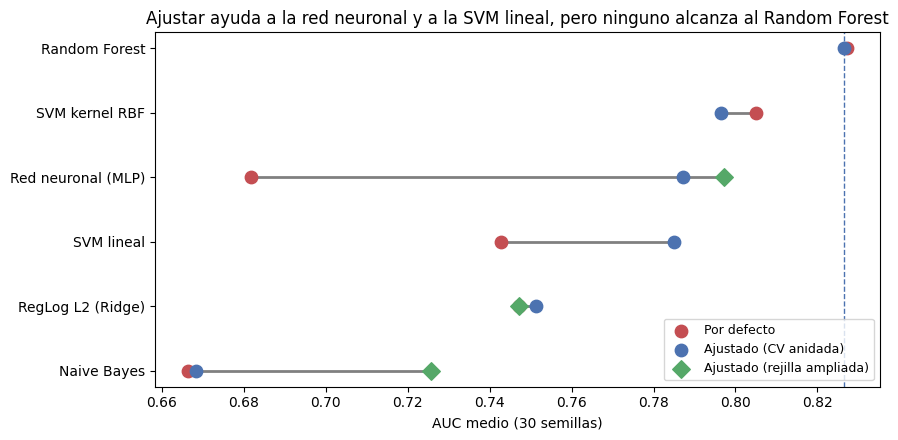

In [52]:
# Gráfica: cuánto gana cada algoritmo al ajustar sus hiperparámetros con CV anidada
por_defecto = algoritmos_30.groupby('Modelo')['AUC'].mean()
ajustado = anidada_algoritmos.groupby('Modelo')['AUC'].mean()
ampliada = anidada_ampliada.groupby('Modelo')['AUC'].mean()
orden = ajustado.sort_values().index
y_pos = np.arange(len(orden))
fig, ax = plt.subplots(figsize=(9, 4.5))
for i, m in enumerate(orden):
    final = max(ajustado[m], ampliada.get(m, -1))
    ax.plot([por_defecto[m], final], [i, i], color='grey', lw=2, zorder=1)
ax.scatter(por_defecto[orden], y_pos, s=80, color='#C44E52', label='Por defecto', zorder=2)
ax.scatter(ajustado[orden], y_pos, s=80, color='#4C72B0', label='Ajustado (CV anidada)', zorder=3)
amp = [m for m in orden if m in ampliada.index]
ax.scatter(ampliada[amp], [list(orden).index(m) for m in amp], s=80, marker='D',
           color='#55A868', label='Ajustado (rejilla ampliada)', zorder=3)
ax.axvline(ajustado['Random Forest'], color='#4C72B0', ls='--', lw=1)
ax.set_yticks(y_pos, orden)
ax.set_xlabel('AUC medio (30 semillas)')
ax.set_title('Ajustar ayuda a la red neuronal y a la SVM lineal, pero ninguno alcanza al Random Forest')
ax.legend(loc='lower right', fontsize=9)
plt.tight_layout()
plt.show()

Con la rejilla ampliada:

* La **red neuronal** sube un poco más (0.787 → 0.797) y ahora elige `alpha = 30`, que ya no
  está en el borde (también probamos 100 y casi nunca la coge). Es la segunda mejor de todas,
  pero sigue 3 centésimas por debajo del bosque y pierde contra él en las 30 semillas.
* **Naive Bayes** mejora bastante (0.668 → 0.726), pero sigue eligiendo el valor más alto
  (`alpha = 100`). Cuanto más suavizado, mejor le va, que es como decir que cuanto menos caso
  hace a las palabras concretas, mejor. Para mí eso confirma que su hipótesis de independencia
  no encaja con este problema, y como está a 10 centésimas del bosque no tiene sentido seguir
  subiéndolo.
* **L2** se queda igual (0.747). El valor que más elige ahora es `C = 0.1` (41 de 150
  folds), que es el borde superior de la rejilla ampliada, pero ese lado ya lo cubría la
  rejilla original (que llegaba hasta `C = 100`), así que no hace falta ampliar más. El
  borde inferior (`C = 0.0001`) solo lo elige en 11 folds.

**Decisión**: con todos los algoritmos ajustados con validación cruzada anidada, el **Random
Forest sigue siendo el mejor**, y además no necesita ajuste: sus valores por defecto ya están
en la zona buena.

> **Modelo actual**: lemas `lg` + BoW + **Random Forest** (500 árboles, resto por defecto) →
> AUC 0.827 ± 0.011, frente a 0.733 del baseline (+0.094).

In [53]:
# Dejamos fijada la configuración del modelo actual (el que gana en el 8.2) para no repetirla
# en cada celda de aquí en adelante:
# stopwords revisadas + quitar puntuación + minúsculas + lemas lg + BoW (min_df=5, max_df=0.8)
# + Random Forest de 500 árboles con el resto de hiperparámetros por defecto.
textos_final = textos_mejor

def crear_vectorizador_final(binary=False):
    return CountVectorizer(min_df=5, max_df=0.8, binary=binary)

def crear_rf_final():
    return RandomForestClassifier(n_estimators=500, random_state=42)

### 8.3 ¿Y algún algoritmo más?

El enunciado pide también "algún otro algoritmo adicional". Ya que lo que mejor funciona son
los árboles, probamos dos cosas más:

* **Gradient Boosting**: también son árboles, pero en vez de votar árboles independientes como
  el bosque, va añadiendo árboles pequeños que corrigen los errores de los anteriores. Lo
  ajustamos con la misma CV anidada (velocidad de aprendizaje, profundidad y nº de árboles).
* **Un ensemble** de los tres mejores modelos de familias distintas (bosque, logístico L1 y SVM
  RBF), promediando sus probabilidades. Si cada uno se equivoca con pacientes distintos, la media
  debería equivocarse menos.

In [54]:
from sklearn.ensemble import GradientBoostingClassifier, VotingClassifier

# 1) Gradient Boosting: también son árboles, pero en vez de votar árboles independientes
#    (como el bosque) va añadiendo árboles pequeños que corrigen los errores de los anteriores.
#    Lo ajustamos con la misma CV anidada que el resto (apartado 8.2).
rejilla_gb = {'gradientboostingclassifier__learning_rate': [0.05, 0.1],
              'gradientboostingclassifier__max_depth': [2, 3],
              'gradientboostingclassifier__n_estimators': [100, 300]}
pipe_gb = make_pipeline(crear_vectorizador_final(), GradientBoostingClassifier(random_state=42))
guardado = cargar('8_3_extra_30')
if guardado is not None:
    extra_30, elegidos_gb = guardado
else:
    filas, elegidos_gb = [], []
    for semilla in semillas:
        externa = StratifiedKFold(n_splits=5, shuffle=True, random_state=semilla)
        interna = StratifiedKFold(n_splits=5, shuffle=True, random_state=semilla + 100)
        busqueda = GridSearchCV(pipe_gb, rejilla_gb, cv=interna, scoring='roc_auc', n_jobs=-1)
        r = cross_validate(busqueda, textos_final, y, cv=externa, return_estimator=True,
                           scoring={'AUC': 'roc_auc', 'F1': 'f1'})
        elegidos_gb += [str({k.split('__')[1]: v for k, v in m.best_params_.items()}) for m in r['estimator']]
        filas.append({'Modelo': 'Gradient Boosting (CV anidada)', 'Semilla': semilla,
                      'AUC': r['test_AUC'].mean(), 'F1': r['test_F1'].mean()})

    # 2) Ensemble: juntamos los tres mejores modelos de familias distintas (bosque, logístico L1
    #    y SVM RBF) y promediamos sus probabilidades (voting='soft'). Si cada uno se equivoca
    #    en pacientes distintos, la media debería equivocarse menos.
    ensemble = VotingClassifier([('rf', crear_rf_final()), ('l1', modelo_L1),
                                 ('svm', SVC(kernel='rbf', C=1.0, probability=True, random_state=42))],
                                voting='soft')
    for nombre, modelo in [('Ensemble RF + L1 + SVM RBF', ensemble), ('Random Forest (el final)', crear_rf_final())]:
        pipe = make_pipeline(crear_vectorizador_final(), modelo)
        for semilla in semillas:
            r = cross_validate(pipe, textos_final, y, scoring={'AUC': 'roc_auc', 'F1': 'f1'}, n_jobs=-1,
                               cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=semilla))
            filas.append({'Modelo': nombre, 'Semilla': semilla, 'AUC': r['test_AUC'].mean(), 'F1': r['test_F1'].mean()})
    extra_30 = pd.DataFrame(filas)
    guardar('8_3_extra_30', (extra_30, elegidos_gb))

rf_ref = extra_30.query("Modelo == 'Random Forest (el final)'").sort_values('Semilla')['AUC'].values
filas = []
for nombre in extra_30['Modelo'].unique():
    v = extra_30.query("Modelo == @nombre").sort_values('Semilla')
    fila = {'Modelo': nombre, 'AUC': f"{v['AUC'].mean():.3f} ± {v['AUC'].std():.3f}",
            'F1': f"{v['F1'].mean():.3f} ± {v['F1'].std():.3f}"}
    if nombre != 'Random Forest (el final)':
        fila['Dif. AUC vs RF'] = f"{(v['AUC'].values - rf_ref).mean():+.3f}"
        fila['Gana al RF'] = f"{(v['AUC'].values > rf_ref).sum()} de 30"
        fila['p-valor (Wilcoxon)'] = formato_p(stats.wilcoxon(v['AUC'].values, rf_ref).pvalue)
    filas.append(fila)
display(pd.DataFrame(filas).fillna('').style.hide(axis='index'))
print("\nHiperparámetros que elige el bucle interno para Gradient Boosting (150 folds):")
print(pd.Series(elegidos_gb).value_counts().head(5).to_string())

Modelo,AUC,F1,Dif. AUC vs RF,Gana al RF,p-valor (Wilcoxon)
Gradient Boosting (CV anidada),0.793 ± 0.018,0.702 ± 0.028,-0.034,1 de 30,< 0.0001
Ensemble RF + L1 + SVM RBF,0.822 ± 0.014,0.725 ± 0.021,-0.005,11 de 30,0.0449
Random Forest (el final),0.827 ± 0.011,0.760 ± 0.016,,,



Hiperparámetros que elige el bucle interno para Gradient Boosting (150 folds):
{'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 300}     25
{'learning_rate': 0.1, 'max_depth': 2, 'n_estimators': 100}     22
{'learning_rate': 0.1, 'max_depth': 2, 'n_estimators': 300}     22
{'learning_rate': 0.05, 'max_depth': 2, 'n_estimators': 100}    19
{'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 100}     16


Ninguno de los dos mejora al bosque:

* **Gradient Boosting** se queda en 0.793 y pierde contra el RF en 29 de las 30 semillas. Además,
  el bucle interno elige combinaciones muy distintas en cada fold, así que no hay una
  configuración que le vaya claramente bien. Con tan pocos pacientes, ir corrigiendo errores
  árbol a árbol tiene más peligro de acabar aprendiéndose el ruido que votar muchos árboles
  independientes.
* **El ensemble** saca 0.822, prácticamente lo mismo que el bosque solo (−0.005, gana en 11 de
  30), y con un F1 más bajo. Juntar modelos no aporta nada aquí, y encima son tres modelos que
  mantener en vez de uno.

**Decisión**: sigo con el Random Forest solo, que es igual o mejor y mucho más sencillo.

### 8.4 ¿Cuántos árboles?

Los 500 árboles del bosque los pusimos sin comprobarlo. El número de árboles no es como los otros
hiperparámetros: más árboles no hacen que el bosque sobreajuste, solo hacen que la votación sea
más estable, a cambio de tardar más. Así que lo que queremos saber es a partir de cuántos
árboles el AUC deja de cambiar.

,mean,std,p-valor vs el anterior (Wilcoxon)
Árboles,,,
50,0.8077,0.0209,
100,0.8180,0.0157,< 0.0001
250,0.8238,0.0132,0.0050
500,0.8272,0.0112,0.0020
1000,0.8287,0.0118,0.0427


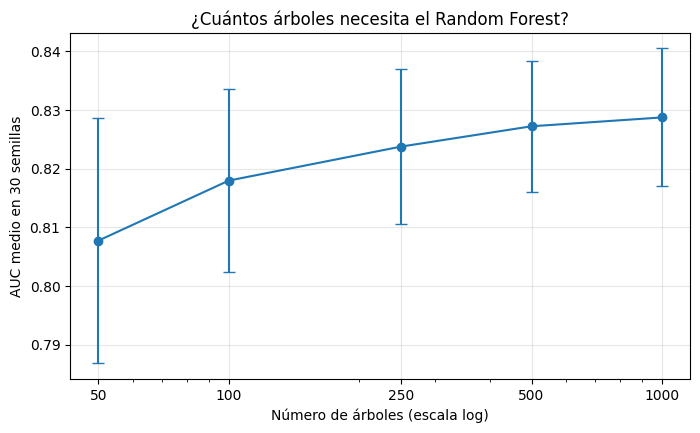

In [55]:
# AUC del Random Forest según el número de árboles, con las 30 semillas de siempre
guardado = cargar('8_4_arboles_30')
if guardado is not None:
    arboles_30 = guardado
else:
    filas = []
    for n_arboles in [50, 100, 250, 500, 1000]:
        pipe = make_pipeline(CountVectorizer(min_df=5, max_df=0.8),
                             RandomForestClassifier(n_estimators=n_arboles, random_state=42))
        for semilla in semillas:
            auc = cross_val_score(pipe, textos_mejor, y, scoring='roc_auc', n_jobs=-1,
                                  cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=semilla)).mean()
            filas.append({'Árboles': n_arboles, 'Semilla': semilla, 'AUC': auc})
    arboles_30 = pd.DataFrame(filas)
    guardar('8_4_arboles_30', arboles_30)

resumen_arboles = arboles_30.groupby('Árboles')['AUC'].agg(['mean', 'std'])
# Cada número de árboles contra el siguiente, semilla a semilla
p_siguiente = []
for a, b in zip(resumen_arboles.index[:-1], resumen_arboles.index[1:]):
    va = arboles_30.query("Árboles == @a").sort_values('Semilla')['AUC'].values
    vb = arboles_30.query("Árboles == @b").sort_values('Semilla')['AUC'].values
    p_siguiente.append(formato_p(stats.wilcoxon(vb, va).pvalue))
resumen_arboles['p-valor vs el anterior (Wilcoxon)'] = [''] + p_siguiente
display(resumen_arboles.style.format({'mean': '{:.4f}', 'std': '{:.4f}'}))

plt.figure(figsize=(8, 4.5))
plt.errorbar(resumen_arboles.index, resumen_arboles['mean'], yerr=resumen_arboles['std'],
             marker='o', capsize=4)
plt.xscale('log')
plt.xticks(resumen_arboles.index, resumen_arboles.index)
plt.xlabel('Número de árboles (escala log)')
plt.ylabel('AUC medio en 30 semillas')
plt.title('¿Cuántos árboles necesita el Random Forest?')
plt.grid(alpha=0.3)
plt.show()

De 50 a 500 árboles el AUC sube en cada escalón (de 0.808 a 0.827) y la desviación entre
semillas baja a la mitad (de 0.021 a 0.011), o sea que el bosque se vuelve más estable. De 500 a
1000 ya solo gana 0.0015, que es casi nada, con un p-valor justo en el límite (0.04) que, por lo
del matiz del 5.1 sobre las semillas, no me tomaría como una mejora real.

**Decisión**: me quedo con 500 árboles, que es donde la curva ya se ha aplanado, y tarda la mitad
que con 1000.

### 8.5 ¿Es este el mejor preprocesado para el bosque?

El preprocesado lo elegimos en el apartado 6 con regresión logística, que es lo que pide el
enunciado. Pero no tiene por qué ser el mejor para un modelo de árboles (de hecho, en el 8 dejamos
apuntado que al bosque podría irle mejor otro preprocesado, como el stemming). Como no quiero darlo por hecho,
hacemos una **búsqueda exhaustiva**: probamos todas las combinaciones de las cuatro decisiones
del preprocesado que más pueden cambiar el vocabulario (3 × 3 × 3 × 2 = 54 combinaciones).

Con 30 semillas y 500 árboles esto tardaría más de una hora, así que lo hacemos en dos pasos:
primero una criba de las 54 con 10 semillas, y luego confirmamos las 5 mejores con las 30.

In [56]:
# Búsqueda exhaustiva de preprocesado para el Random Forest.
# El preprocesado lo elegimos en el apartado 6 con regresión logística, pero eso no
# quiere decir que sea también el mejor para un modelo de árboles. Así que probamos
# TODAS las combinaciones de:
#   - stopwords:      revisadas / todas las de NLTK / no quitar ninguna
#   - normalización:  lemas con es_core_news_lg / stemming / nada (solo minúsculas)
#   - min_df:         2 / 5 / 10
#   - max_df:         0.8 / 1.0 (es decir, sin filtrar las palabras muy frecuentes)
# En total 3 x 3 x 3 x 2 = 54 combinaciones.
import itertools

# 1) Los 9 textos distintos (stopwords x normalización). Lematizamos con lg.
guardado = cargar('8_5_textos_exh')
if guardado is not None:
    textos_exh = guardado
else:
    nlp = spacy.load('es_core_news_lg')
    opciones_stop = {'revisadas': dict(), 'todas NLTK': dict(stopwords_set=stopwords_español),
                     'ninguna': dict(quitar_stopwords=False)}
    opciones_norm = {'lemas lg': 'lemas', 'stemming': 'stem', 'nada': 'ninguna'}
    textos_exh = {}
    for (n_stop, op_stop), (n_norm, op_norm) in itertools.product(opciones_stop.items(), opciones_norm.items()):
        textos_exh[(n_stop, n_norm)] = preprocesar(df_clasbin['TEXTO'], normalizacion=op_norm, **op_stop)
    nlp = spacy.load('es_core_news_sm')
    guardar('8_5_textos_exh', textos_exh)

def auc_rf(textos, min_df, max_df, semillas_usar):
    pipe = make_pipeline(CountVectorizer(min_df=min_df, max_df=max_df),
                         RandomForestClassifier(n_estimators=500, random_state=42))
    return np.array([cross_val_score(pipe, textos, y, scoring='roc_auc', n_jobs=-1,
                                     cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=s)).mean()
                     for s in semillas_usar])

# 2) Primera criba: las 54 combinaciones con 10 semillas (con 30 tardaría más de una hora)
guardado = cargar('8_5_criba')
if guardado is not None:
    criba = guardado
else:
    filas = []
    for (n_stop, n_norm), min_df, max_df in itertools.product(textos_exh, [2, 5, 10], [0.8, 1.0]):
        aucs = auc_rf(textos_exh[(n_stop, n_norm)], min_df, max_df, semillas[:10])
        filas.append({'Stopwords': n_stop, 'Normalización': n_norm, 'min_df': min_df, 'max_df': max_df,
                      'AUC (10 semillas)': aucs.mean()})
    criba = pd.DataFrame(filas).sort_values('AUC (10 semillas)', ascending=False).reset_index(drop=True)
    guardar('8_5_criba', criba)
print("Las 10 mejores combinaciones de la criba:")
display(criba.head(10).style.format({'AUC (10 semillas)': '{:.4f}', 'max_df': '{:.1f}'}).hide(axis='index'))
print("\nLas 5 peores:")
display(criba.tail(5).style.format({'AUC (10 semillas)': '{:.4f}', 'max_df': '{:.1f}'}).hide(axis='index'))

# Efecto medio de cada decisión (media de todas las combinaciones que la comparten)
for factor in ['Stopwords', 'Normalización', 'min_df', 'max_df']:
    print(f"\n{factor}: " + ' | '.join(f"{k}: {v:.4f}" for k, v in
          criba.groupby(factor)['AUC (10 semillas)'].mean().sort_values(ascending=False).items()))

Las 10 mejores combinaciones de la criba:


Stopwords,Normalización,min_df,max_df,AUC (10 semillas)
todas NLTK,stemming,10,1.0,0.8300
todas NLTK,stemming,10,0.8,0.8300
todas NLTK,lemas lg,2,1.0,0.8293
todas NLTK,lemas lg,2,0.8,0.8293
revisadas,lemas lg,2,0.8,0.8281
todas NLTK,stemming,2,1.0,0.8278
todas NLTK,stemming,2,0.8,0.8278
revisadas,stemming,10,0.8,0.8271
ninguna,stemming,10,0.8,0.8258
revisadas,stemming,5,0.8,0.8252



Las 5 peores:


Stopwords,Normalización,min_df,max_df,AUC (10 semillas)
ninguna,nada,2,0.8,0.8105
revisadas,nada,10,1.0,0.8094
ninguna,nada,5,1.0,0.8070
ninguna,nada,2,1.0,0.8026
ninguna,nada,10,1.0,0.8022



Stopwords: todas NLTK: 0.8230 | revisadas: 0.8206 | ninguna: 0.8146

Normalización: stemming: 0.8239 | lemas lg: 0.8215 | nada: 0.8129

min_df: 2: 0.8198 | 10: 0.8195 | 5: 0.8189

max_df: 0.8: 0.8210 | 1.0: 0.8178


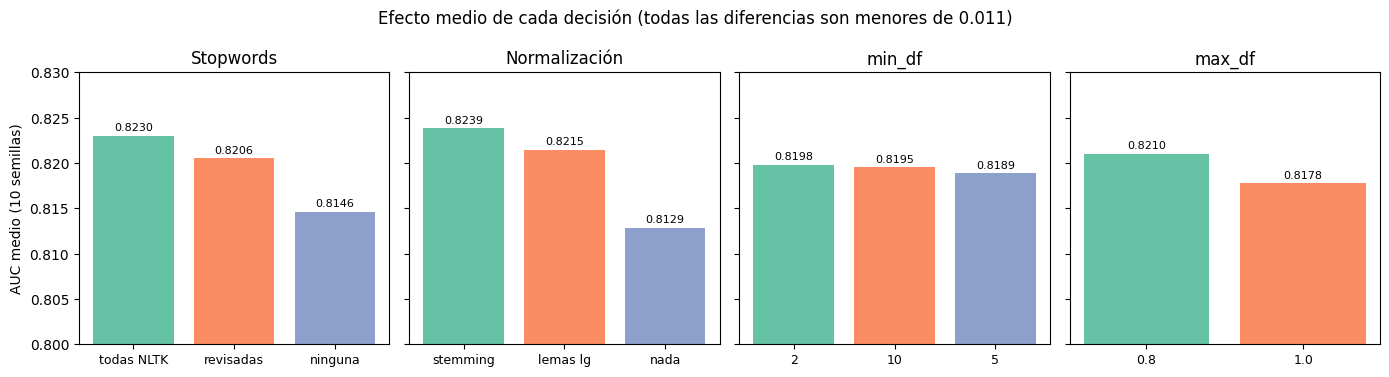

In [57]:
# Gráfica: efecto medio de cada decisión de preprocesado en la búsqueda exhaustiva
factores = ['Stopwords', 'Normalización', 'min_df', 'max_df']
efectos = {f: criba.groupby(f)['AUC (10 semillas)'].mean().sort_values(ascending=False) for f in factores}
fig, axes = plt.subplots(1, 4, figsize=(14, 3.8), sharey=True)
for ax, f in zip(axes, factores):
    barras = ax.bar([str(k) for k in efectos[f].index], efectos[f].values, color=sns.color_palette('Set2', len(efectos[f])))
    ax.bar_label(barras, fmt='%.4f', fontsize=8, padding=2)
    ax.set_title(f)
    ax.set_ylim(0.80, 0.83)
    ax.tick_params(axis='x', labelsize=9)
axes[0].set_ylabel('AUC medio (10 semillas)')
fig.suptitle('Efecto medio de cada decisión (todas las diferencias son menores de 0.011)')
plt.tight_layout()
plt.show()

In [58]:
# 3) Confirmación: las 5 mejores de la criba, ahora con las 30 semillas, y cada una
# contra la configuración que ya teníamos (stopwords revisadas + lemas lg + min_df=5 + max_df=0.8)
actual = algoritmos_30.query("Modelo == 'Random Forest'").sort_values('Semilla')['AUC'].values
guardado = cargar('8_5_confirmacion')
if guardado is not None:
    filas = guardado
else:
    filas = []
    for _, fila in criba.head(5).iterrows():
        aucs = auc_rf(textos_exh[(fila['Stopwords'], fila['Normalización'])], fila['min_df'], fila['max_df'], semillas)
        es_actual = (fila['Stopwords'], fila['Normalización'], fila['min_df'], fila['max_df']) == ('revisadas', 'lemas lg', 5, 0.8)
        filas.append({'Stopwords': fila['Stopwords'], 'Normalización': fila['Normalización'],
                      'min_df': fila['min_df'], 'max_df': fila['max_df'],
                      'AUC (30 semillas)': f"{aucs.mean():.3f} ± {aucs.std(ddof=1):.3f}",
                      'Dif. vs la actual': '' if es_actual else f"{(aucs - actual).mean():+.3f}",
                      'Gana a la actual': '' if es_actual else f"{(aucs > actual).sum()} de 30",
                      'p-valor (Wilcoxon)': '' if es_actual else formato_p(stats.wilcoxon(aucs, actual).pvalue)})
    guardar('8_5_confirmacion', filas)
print(f"Configuración actual (revisadas + lemas lg + min_df=5 + max_df=0.8): AUC = {actual.mean():.3f} ± {actual.std(ddof=1):.3f}")
display(pd.DataFrame(filas).style.hide(axis='index'))

Configuración actual (revisadas + lemas lg + min_df=5 + max_df=0.8): AUC = 0.827 ± 0.011


Stopwords,Normalización,min_df,max_df,AUC (30 semillas),Dif. vs la actual,Gana a la actual,p-valor (Wilcoxon)
todas NLTK,stemming,10,1.000000,0.834 ± 0.013,+0.007,21 de 30,0.0185
todas NLTK,stemming,10,0.800000,0.834 ± 0.013,+0.007,21 de 30,0.0185
todas NLTK,lemas lg,2,1.000000,0.832 ± 0.012,+0.005,19 de 30,0.0961
todas NLTK,lemas lg,2,0.800000,0.832 ± 0.012,+0.005,19 de 30,0.0961
revisadas,lemas lg,2,0.800000,0.829 ± 0.010,+0.002,18 de 30,0.5978


Lo que vemos en la criba:

* **Todas las combinaciones están entre 0.80 y 0.83.** Ninguna decisión del preprocesado cambia
  el resultado más de 3 centésimas, mucho menos que lo que ganamos al pasar de lineal a árboles.
* Lo que más importa es **normalizar** (stemming o lemas, 0.82, frente a no hacer nada, 0.81) y
  **quitar stopwords** (cualquiera de las dos listas va mejor que no quitarlas).
* `min_df` da igual, y `max_df` casi: con las stopwords quitadas, las palabras muy frecuentes
  ya no están, así que el filtro del 80% no tiene nada que quitar (por eso en la tabla salen
  parejas idénticas con 0.8 y 1.0).

En la confirmación con 30 semillas, la mejor (todas las stopwords de NLTK + stemming + `min_df=10`) le saca 7 milésimas a la configuración actual (0.834 frente a 0.827) y le gana en 21 de las 30 semillas (p = 0.0185). Las otras dos (lemas `lg` + `min_df=2`, con todas las stopwords de NLTK o con las revisadas) se quedan más cerca, a 5 y 2 milésimas, y la diferencia ya no es significativa (p = 0.0961 y p = 0.5978).

In [59]:
# 4) Ojo con una trampa: las 5 mejores las hemos ELEGIDO mirando las semillas 0-9, y luego las
# hemos confirmado con las semillas 0-29, que incluyen esas mismas 10. Si pruebas 54 cosas,
# alguna sale arriba un poco por suerte, y medirla otra vez con los mismos datos arrastra esa
# suerte. Para quitarnos la duda medimos las dos mejores y la actual con 30 semillas NUEVAS
# (30-59), que no se han usado para elegir nada.
semillas_nuevas = list(range(30, 60))
candidatas = {'Actual (revisadas + lemas lg + min_df=5 + max_df=0.8)': ('revisadas', 'lemas lg', 5, 0.8),
              'Todas NLTK + stemming + min_df=10 + max_df=0.8': ('todas NLTK', 'stemming', 10, 0.8),
              'Todas NLTK + lemas lg + min_df=2 + max_df=0.8': ('todas NLTK', 'lemas lg', 2, 0.8)}
guardado = cargar('8_5_aucs_nuevas')
if guardado is not None:
    aucs_nuevas = guardado
else:
    aucs_nuevas = {nombre: auc_rf(textos_exh[(s, n)], mi, ma, semillas_nuevas)
                   for nombre, (s, n, mi, ma) in candidatas.items()}
    guardar('8_5_aucs_nuevas', aucs_nuevas)

ref_nueva = aucs_nuevas['Actual (revisadas + lemas lg + min_df=5 + max_df=0.8)']
filas = []
for nombre, v in aucs_nuevas.items():
    fila = {'Configuración': nombre, 'AUC (semillas 30-59)': f"{v.mean():.3f} ± {v.std(ddof=1):.3f}"}
    if not nombre.startswith('Actual'):
        fila['Dif. vs la actual'] = f"{(v - ref_nueva).mean():+.3f}"
        fila['Gana a la actual'] = f"{(v > ref_nueva).sum()} de 30"
        fila['p-valor (Wilcoxon)'] = formato_p(stats.wilcoxon(v, ref_nueva).pvalue)
    filas.append(fila)
display(pd.DataFrame(filas).fillna('').style.hide(axis='index'))

Configuración,AUC (semillas 30-59),Dif. vs la actual,Gana a la actual,p-valor (Wilcoxon)
Actual (revisadas + lemas lg + min_df=5 + max_df=0.8),0.827 ± 0.009,,,
Todas NLTK + stemming + min_df=10 + max_df=0.8,0.833 ± 0.009,+0.007,25 de 30,< 0.0001
Todas NLTK + lemas lg + min_df=2 + max_df=0.8,0.830 ± 0.009,+0.003,22 de 30,0.0175


Con semillas que no se habían usado para nada, la mejora de la mejor se mantiene: todas las stopwords de NLTK + stemming + `min_df=10` saca 0.833 frente a 0.827 y gana en 25 de 30 semillas (p < 0.0001). La segunda (todas las stopwords de NLTK + lemas `lg` + `min_df=2`) se queda en 0.830, solo 3 milésimas por encima de la actual, y gana en 22 de 30 (p = 0.0175). Así que no parece suerte de
haber elegido justo esas particiones. Eso sí, las semillas nuevas solo cambian cómo se
reparten los pacientes, y los 239 pacientes son los mismos con los que hemos elegido, así que
el sesgo de haber probado 54 combinaciones no desaparece del todo y la mejora real podría ser
algo menor.

Aun así **me quedo con la configuración que teníamos** (lemas `lg`), por dos motivos:

1. **7 milésimas de AUC no cambian nada en la práctica.** Equivale a ordenar bien una pareja de
   pacientes más de cada 140. Para usarlo en el hospital es lo mismo un 0.827 que un 0.834.
2. **Los lemas se entienden y los stems no.** Si un médico mira por qué el modelo marca un
   informe, `sincrónico` o `adenocarcinoma` se leen directamente, y `sincron` o `adenocarcinom`
   no tanto. Para un modelo que tiene que ganarse la confianza de los clínicos me parece más
   importante que esas milésimas.

Lo dejo apuntado como mejora posible: si en algún momento lo que importara fuera exprimir el
AUC, cambiaríamos a todas las stopwords de NLTK con stemming y `min_df=10`, que además tiene menos palabras.

#### ¿Y una BoW binaria?

Otra opción que no hemos probado es que la BoW no cuente cuántas veces sale cada palabra sino
solo si sale o no (1/0). Podría tener sentido: para saber si hay varias neoplasias puede
importar más QUÉ se menciona que CUÁNTAS veces, y además con conteos los informes largos pesan
más. Lo comprobamos con el bosque y con el mejor logístico.

In [60]:
# BoW de conteos frente a BoW binaria (1 si la palabra aparece en el informe, 0 si no),
# con el modelo final y con el mejor logístico, en las mismas 30 semillas.
# La idea: para "¿tiene varias neoplasias?" puede importar más QUÉ se menciona que
# CUÁNTAS veces, y además con conteos los informes largos pesan más.
guardado = cargar('8_5_binaria_30')
if guardado is not None:
    binaria_30 = guardado
else:
    filas = []
    for nombre_modelo, crear in [('Random Forest', crear_rf_final), ('RegLog L1', lambda: modelo_L1)]:
        for binaria in [False, True]:
            pipe = make_pipeline(crear_vectorizador_final(binary=binaria), crear())
            for semilla in semillas:
                r = cross_validate(pipe, textos_final, y, scoring={'AUC': 'roc_auc', 'F1': 'f1'}, n_jobs=-1,
                                   cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=semilla))
                filas.append({'Modelo': nombre_modelo, 'BoW': 'binaria' if binaria else 'conteos',
                              'Semilla': semilla, 'AUC': r['test_AUC'].mean(), 'F1': r['test_F1'].mean()})
    binaria_30 = pd.DataFrame(filas)
    guardar('8_5_binaria_30', binaria_30)

filas = []
for nombre_modelo in ['Random Forest', 'RegLog L1']:
    c = binaria_30.query("Modelo == @nombre_modelo and BoW == 'conteos'").sort_values('Semilla')['AUC'].values
    b = binaria_30.query("Modelo == @nombre_modelo and BoW == 'binaria'").sort_values('Semilla')['AUC'].values
    filas.append({'Modelo': nombre_modelo, 'AUC conteos': f"{c.mean():.3f} ± {c.std(ddof=1):.3f}",
                  'AUC binaria': f"{b.mean():.3f} ± {b.std(ddof=1):.3f}",
                  'Diferencia (binaria - conteos)': f"{(b - c).mean():+.3f}",
                  'Gana la binaria': f"{(b > c).sum()} de 30",
                  'p-valor (Wilcoxon)': formato_p(stats.wilcoxon(b, c).pvalue)})
display(pd.DataFrame(filas).style.hide(axis='index'))

Modelo,AUC conteos,AUC binaria,Diferencia (binaria - conteos),Gana la binaria,p-valor (Wilcoxon)
Random Forest,0.827 ± 0.011,0.782 ± 0.016,-0.045,0 de 30,< 0.0001
RegLog L1,0.778 ± 0.021,0.758 ± 0.023,-0.020,6 de 30,< 0.0001


Pues al revés: **los conteos van claramente mejor**, sobre todo en el bosque (0.827 frente a
0.782, gana en las 30 semillas). O sea que el número de veces que aparece una palabra sí que
importa, que encaja con lo que vimos con TF-IDF en el 7.2: si "carcinoma" o "neoplasia" salen
muchas veces en un informe, es más probable que haya más de una. **Decisión**: BoW de conteos.

#### ¿Y TF-IDF con el bosque?

La BoW binaria pierde porque se pierde cuántas veces sale cada palabra. TF-IDF es otra forma de
cambiar la ponderación, y ya la descartamos en el 7.2, pero allí solo la probamos con regresión
logística, que era lo que pedía el enunciado en ese punto. Después, en el 8.1, el algoritmo que ganó
fue el bosque, así que **TF-IDF nunca se ha probado con nuestro modelo final**. ¿No será que solo
perdía por usar un modelo lineal? Además, el enunciado pide probar los algoritmos con las distintas
representaciones, no solo con la BoW.

Repetimos el 8.1 entero (los siete algoritmos con sus valores por defecto y las mismas 30 semillas)
cambiando solo `CountVectorizer` por `TfidfVectorizer`, con los lemas `lg` y quitando las stopwords,
que es lo que mejor le fue a TF-IDF en el 7.2.

Modelo,AUC con BoW (8.1),AUC con TF-IDF,Diferencia,Gana TF-IDF,p-valor (Wilcoxon)
Random Forest,0.827,0.808 ± 0.016,-0.020,2 de 30,< 0.0001
SVM kernel RBF,0.805,0.723 ± 0.019,-0.081,0 de 30,< 0.0001
RegLog L1 (Lasso),0.778,0.690 ± 0.017,-0.089,0 de 30,< 0.0001
RegLog L2 (Ridge),0.747,0.720 ± 0.018,-0.027,1 de 30,< 0.0001
SVM lineal,0.743,0.714 ± 0.023,-0.028,0 de 30,< 0.0001
Red neuronal (MLP),0.682,0.670 ± 0.021,-0.012,9 de 30,0.0002
Naive Bayes,0.666,0.655 ± 0.021,-0.011,1 de 30,< 0.0001


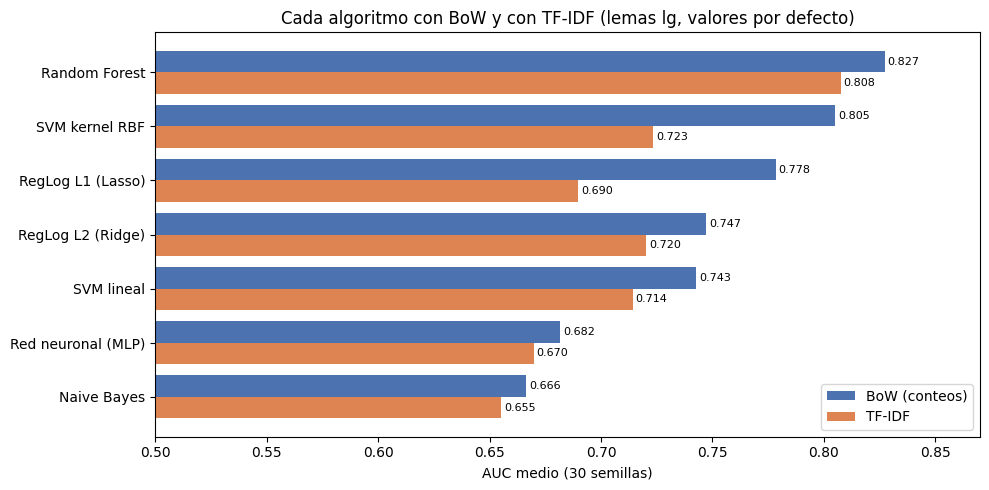

In [61]:
# ¿Y si TF-IDF solo perdía por ser regresión logística? En el 7.2 lo descartamos con L1 y L2,
# pero luego, en el 8.1, el algoritmo que ganó fue el bosque, así que TF-IDF nunca se ha probado
# con nuestro modelo final. Repetimos el 8.1 tal cual (mismos modelos con sus valores por defecto,
# mismas 30 semillas y vectorizador dentro del Pipeline) cambiando solo CountVectorizer por
# TfidfVectorizer, con los lemas lg quitando stopwords (lo que mejor le ha ido a TF-IDF arriba).
guardado = cargar('8_5_algoritmos_tfidf_30')
if guardado is not None:
    algoritmos_tfidf_30 = guardado
else:
    filas = []
    for nombre, modelo in modelos.items():
        print(f"Evaluando con TF-IDF y 30 semillas: {nombre} ...")
        pipe = make_pipeline(TfidfVectorizer(min_df=5, max_df=0.8), modelo)
        for semilla in semillas:
            r = cross_validate(pipe, textos_mejor, y, scoring=scoring, n_jobs=-1,
                               cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=semilla))
            filas.append({'Modelo': nombre, 'Semilla': semilla, **{m: r[f'test_{m}'].mean() for m in scoring}})
    algoritmos_tfidf_30 = pd.DataFrame(filas)
    guardar('8_5_algoritmos_tfidf_30', algoritmos_tfidf_30)

# Cada algoritmo con TF-IDF contra el mismo algoritmo con BoW (8.1), semilla a semilla
filas = []
for nombre in modelos:
    bow = algoritmos_30.query("Modelo == @nombre").sort_values('Semilla')['AUC'].values
    tfidf = algoritmos_tfidf_30.query("Modelo == @nombre").sort_values('Semilla')['AUC'].values
    filas.append({'Modelo': nombre, 'AUC con BoW (8.1)': f"{bow.mean():.3f}",
                  'AUC con TF-IDF': f"{tfidf.mean():.3f} ± {tfidf.std(ddof=1):.3f}",
                  'Diferencia': f"{(tfidf - bow).mean():+.3f}",
                  'Gana TF-IDF': f"{(tfidf > bow).sum()} de 30",
                  'p-valor (Wilcoxon)': formato_p(stats.wilcoxon(tfidf, bow).pvalue), '_orden': bow.mean()})
display(pd.DataFrame(filas).sort_values('_orden', ascending=False).drop(columns='_orden').style.hide(axis='index'))

# Gráfica: BoW frente a TF-IDF con cada algoritmo (media de las 30 semillas)
orden = algoritmos_30.groupby('Modelo')['AUC'].mean().sort_values().index
media_bow = algoritmos_30.groupby('Modelo')['AUC'].mean()[orden]
media_tfidf = algoritmos_tfidf_30.groupby('Modelo')['AUC'].mean()[orden]
posiciones = np.arange(len(orden))
fig, ax = plt.subplots(figsize=(10, 5))
barras = ax.barh(posiciones + 0.2, media_bow, height=0.4, label='BoW (conteos)', color='#4C72B0')
ax.bar_label(barras, fmt='%.3f', fontsize=8, padding=2)
barras = ax.barh(posiciones - 0.2, media_tfidf, height=0.4, label='TF-IDF', color='#DD8452')
ax.bar_label(barras, fmt='%.3f', fontsize=8, padding=2)
ax.set_yticks(posiciones, orden)
ax.set_xlim(0.5, 0.87)
ax.set_xlabel('AUC medio (30 semillas)')
ax.set_title('Cada algoritmo con BoW y con TF-IDF (lemas lg, valores por defecto)')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()


**TF-IDF pierde con los siete algoritmos**, así que no era cosa de la regresión logística:

* Con el **Random Forest**, que es el que nos interesa, baja de 0.827 a 0.808 y solo gana en 2 de
  las 30 semillas (p < 0.0001). Es la mejor combinación con TF-IDF, pero sigue 2 centésimas por debajo.
* Con la SVM RBF y la L1 la caída es enorme (−0.08 y −0.09). Pasa lo mismo que en el 7.2: con los
  valores entre 0 y 1 de TF-IDF, la `C` por defecto no castiga igual, y ajustándola se recuperaría
  parte. Pero al bosque le da igual la escala de las columnas, y en el 8.2 vimos que ajustarlo no
  cambia nada, así que su comparación es justa y es la que decide.
* Encaja con la BoW binaria. Creo que la explicación es la misma: el número de veces que sale una
  palabra sí informa, y TF-IDF normaliza cada informe, así que en los informes largos (que son más
  a menudo de múltiples neoplasias) los conteos pierden peso.

**Decisión**: también con el bosque **me quedo con la BoW de conteos**.

### 8.6 ¿Mejoraría con más pacientes?

Antes de pensar en usarlo de verdad, una pregunta importante es si el modelo ya ha llegado a su
techo o si con más informes etiquetados seguiría mejorando. Para verlo hacemos una curva de
aprendizaje: entrenamos con el 20%, 40%... 100% del train de cada fold y medimos siempre sobre
el mismo test (es parecido a lo que hicimos en Minería de Datos al variar la proporción de
train).

Pacientes de entrenamiento,AUC medio,Desv.,Ganancia vs el anterior,p-valor (Wilcoxon)
38,0.701,0.038,,
76,0.765,0.024,+0.064,< 0.0001
114,0.800,0.018,+0.036,< 0.0001
152,0.819,0.016,+0.018,< 0.0001
191,0.828,0.012,+0.010,< 0.0001


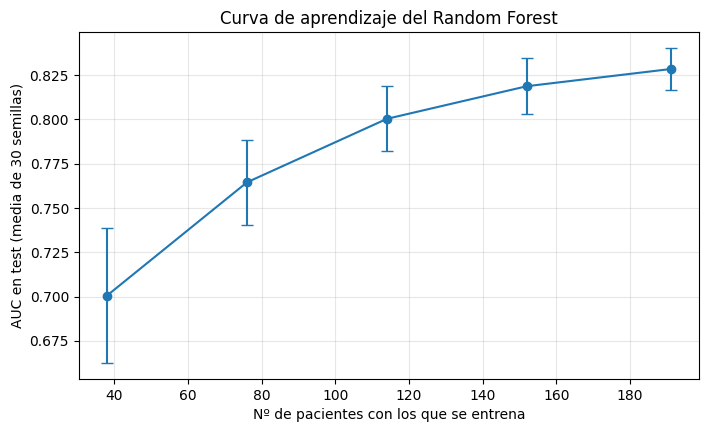

In [62]:
from sklearn.model_selection import learning_curve

# Curva de aprendizaje del modelo final: entrenamos con el 20%, 40%, ... 100% del
# train de cada fold y medimos siempre en el mismo test. Si la curva sigue subiendo
# al final, conseguir más informes etiquetados mejoraría el modelo.
proporciones = [0.2, 0.4, 0.6, 0.8, 1.0]
pipe_final = make_pipeline(crear_vectorizador_final(), crear_rf_final())
guardado = cargar('8_6_curva_aprendizaje')
if guardado is not None:
    curvas, tamanos = guardado
else:
    curvas = []
    for semilla in semillas:
        tamanos, _, test_scores = learning_curve(
            pipe_final, textos_final, y, train_sizes=proporciones, scoring='roc_auc', n_jobs=-1,
            cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=semilla), shuffle=True, random_state=semilla)
        curvas.append(test_scores.mean(axis=1))
    curvas = np.array(curvas)        # 30 semillas x 5 tamaños
    guardar('8_6_curva_aprendizaje', (curvas, tamanos))

tabla_curva = pd.DataFrame({'Pacientes de entrenamiento': tamanos,
                            'AUC medio': curvas.mean(axis=0), 'Desv.': curvas.std(axis=0, ddof=1)})
# Cuánto se gana en cada escalón, semilla a semilla
tabla_curva['Ganancia vs el anterior'] = [np.nan] + list(np.diff(curvas, axis=1).mean(axis=0))
tabla_curva['p-valor (Wilcoxon)'] = [''] + [formato_p(stats.wilcoxon(curvas[:, i + 1], curvas[:, i]).pvalue)
                                            for i in range(len(proporciones) - 1)]
display(tabla_curva.style.format({'AUC medio': '{:.3f}', 'Desv.': '{:.3f}',
                                  'Ganancia vs el anterior': '{:+.3f}'}, na_rep='').hide(axis='index'))

plt.figure(figsize=(8, 4.5))
plt.errorbar(tamanos, curvas.mean(axis=0), yerr=curvas.std(axis=0, ddof=1), marker='o', capsize=4)
plt.xlabel('Nº de pacientes con los que se entrena')
plt.ylabel('AUC en test (media de 30 semillas)')
plt.title('Curva de aprendizaje del Random Forest')
plt.grid(alpha=0.3)
plt.show()

La curva **no se ha aplanado todavía**. Cada escalón gana menos que el anterior (+0.064,
+0.036, +0.018, +0.010), pero de 152 a 191 pacientes todavía sube una centésima, y en las 30
semillas. La desviación entre semillas también va bajando al meter más pacientes.

Esto para mí es de las conclusiones más útiles de cara al hospital: **lo que más mejoraría el
modelo no es seguir retocando el preprocesado o los hiperparámetros, sino etiquetar más
informes**. Con 239 pacientes estamos en la parte de la curva donde los datos todavía se notan.

### 8.7 Elegimos el umbral pensando en la clínica

Hasta ahora todo se ha medido con AUC (para comparar modelos) y con el umbral de 0.5 por
defecto. Pero como dijimos al principio, el umbral se fija una vez elegido el modelo, y en este
problema no es lo mismo equivocarse hacia un lado que hacia el otro: si el modelo dice "única"
a un paciente con varias neoplasias, ese paciente se queda sin revisar; si dice "múltiples" a
uno que no lo es, solo cuesta que alguien lea un informe de más.

Así que me pongo un objetivo clínico: **detectar al menos 9 de cada 10 pacientes con
múltiples neoplasias** (recall ≥ 0.90), y miro cuánto nos cuesta en falsas alarmas. Para no
hacer trampa, el umbral se elige solo con los pacientes de entrenamiento de cada fold y se
aplica a los de test.

In [63]:
# Elegimos el umbral pensando en el uso clínico: queremos que se escapen pocos
# pacientes con múltiples neoplasias, así que fijamos como objetivo un recall de al menos 0.90
# (detectar 9 de cada 10) y miramos cuánto nos cuesta en falsas alarmas.
# Para no hacer trampa, el umbral se elige SOLO con el train de cada fold:
#   1) dentro del train sacamos probabilidades out-of-fold con otra CV de 5 folds
#   2) buscamos el umbral más alto que todavía llega a recall >= 0.90 en ese train
#   3) entrenamos con todo el train y aplicamos ese umbral a los pacientes de test
recall_objetivo = 0.90

def umbral_para_recall(y_real, probas, objetivo=recall_objetivo):
    # probabilidades de los positivos ordenadas de mayor a menor: el umbral es la
    # del positivo que hace que lleguemos justo al objetivo
    p_pos = np.sort(probas[y_real == 1])[::-1]
    return p_pos[int(np.ceil(objetivo * len(p_pos))) - 1]

y_arr = np.asarray(y)
filas, umbrales = [], []
for semilla in semillas:
    externa = StratifiedKFold(n_splits=5, shuffle=True, random_state=semilla)
    pred_05, pred_clin = np.zeros(len(y_arr)), np.zeros(len(y_arr))
    for train, test in externa.split(textos_final, y_arr):
        X_tr, y_tr = textos_final.iloc[train], y_arr[train]
        pipe = make_pipeline(crear_vectorizador_final(), crear_rf_final())
        p_interna = cross_val_predict(pipe, X_tr, y_tr, method='predict_proba', n_jobs=-1,
                                      cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=semilla + 100))[:, 1]
        u = umbral_para_recall(y_tr, p_interna)
        umbrales.append(u)
        p_test = pipe.fit(X_tr, y_tr).predict_proba(textos_final.iloc[test])[:, 1]
        pred_05[test], pred_clin[test] = p_test >= 0.5, p_test >= u
    for nombre, pred in [('0.5 (por defecto)', pred_05), (f'Elegido para recall ≥ {recall_objetivo}', pred_clin)]:
        tn, fp, fn, tp = confusion_matrix(y_arr, pred).ravel()
        filas.append({'Umbral': nombre, 'Semilla': semilla, 'Recall': tp / (tp + fn),
                      'Precision': tp / (tp + fp), 'Especificidad': tn / (tn + fp),
                      'Informes marcados (%)': 100 * (tp + fp) / len(y_arr), 'FN': fn, 'FP': fp})
umbral_30 = pd.DataFrame(filas)

resumen_umbral = umbral_30.groupby('Umbral', sort=False).agg(['mean', 'std']).drop(columns='Semilla')
resumen_umbral.columns = [f'{m} ({e})'.replace('(mean)', '(media)').replace('(std)', '(desv.)') for m, e in resumen_umbral.columns]
display(resumen_umbral.T.style.format('{:.3f}'))
print(f"Umbral elegido en los 150 folds: media {np.mean(umbrales):.3f} "
      f"(entre {np.min(umbrales):.3f} y {np.max(umbrales):.3f})")

Umbral,0.5 (por defecto),Elegido para recall ≥ 0.9
Recall (media),0.734,0.906
Recall (desv.),0.018,0.015
Precision (media),0.794,0.636
Precision (desv.),0.015,0.020
Especificidad (media),0.814,0.494
Especificidad (desv.),0.016,0.046
Informes marcados (%) (media),45.621,70.377
Informes marcados (%) (desv.),1.079,2.699
FN (media),31.433,11.067
FN (desv.),2.176,1.818


Umbral elegido en los 150 folds: media 0.376 (entre 0.300 y 0.440)


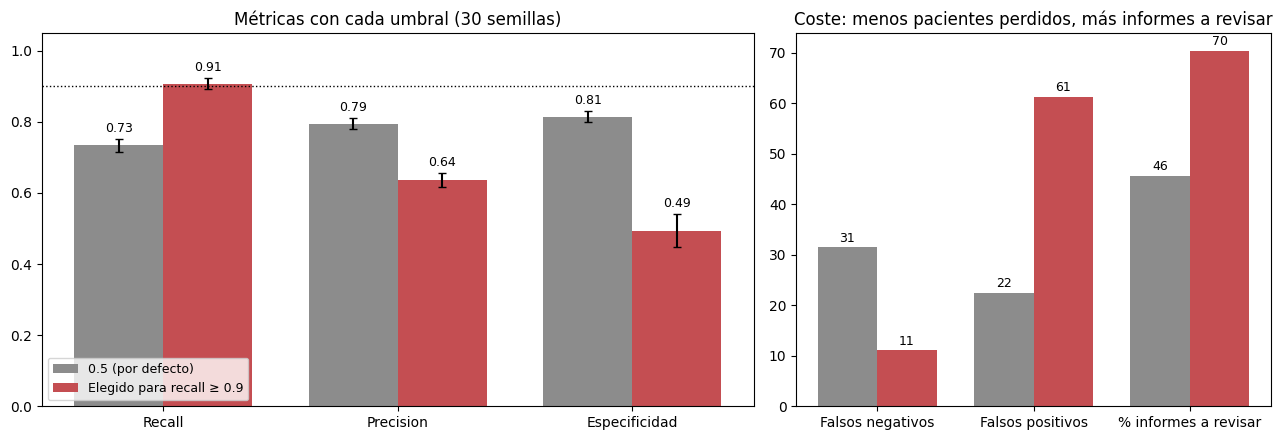

In [64]:
# Gráfica: qué cambia al pasar del umbral 0.5 al umbral clínico
metricas = ['Recall', 'Precision', 'Especificidad']
res_m = umbral_30.groupby('Umbral', sort=False)[metricas + ['Informes marcados (%)', 'FN', 'FP']].agg(['mean', 'std'])
nombres = list(res_m.index)
colores = ['#8C8C8C', '#C44E52']
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={'width_ratios': [3, 2]})
x = np.arange(len(metricas))
for k, nombre in enumerate(nombres):
    medias = [res_m.loc[nombre, (m, 'mean')] for m in metricas]
    desv = [res_m.loc[nombre, (m, 'std')] for m in metricas]
    barras = ax1.bar(x + (k - 0.5) * 0.38, medias, 0.38, yerr=desv, capsize=3, label=nombre, color=colores[k])
    ax1.bar_label(barras, fmt='%.2f', fontsize=9, padding=3)
ax1.axhline(0.9, color='black', ls=':', lw=1)
ax1.set_xticks(x, metricas)
ax1.set_ylim(0, 1.05)
ax1.set_title('Métricas con cada umbral (30 semillas)')
ax1.legend(loc='lower left', fontsize=9)
x2 = np.arange(3)
for k, nombre in enumerate(nombres):
    vals = [res_m.loc[nombre, (c, 'mean')] for c in ['FN', 'FP', 'Informes marcados (%)']]
    barras = ax2.bar(x2 + (k - 0.5) * 0.38, vals, 0.38, color=colores[k])
    ax2.bar_label(barras, fmt='%.0f', fontsize=9, padding=2)
ax2.set_xticks(x2, ['Falsos negativos', 'Falsos positivos', '% informes a revisar'])
ax2.set_title('Coste: menos pacientes perdidos, más informes a revisar')
plt.tight_layout()
plt.show()

| | Umbral 0.5 | Umbral para recall ≥ 0.90 (~0.38) |
|---|---|---|
| Pacientes con múltiples que detectamos (recall) | 73% | **91%** |
| Múltiples que se escapan (de 118) | 31 | **11** |
| Únicas bien descartadas (especificidad) | 81% | 49% |
| Informes que hay que revisar | 46% | 70% |

Lo que significa en la práctica: bajando el umbral a ~0.38 pasamos de dejar escapar 31
pacientes a 11, pero a cambio marcamos el 70% de los informes para revisar, y la mitad de las
únicas neoplasias salen como falsa alarma.

Mi lectura es que **este modelo no sirve para decidir solo, pero sí para priorizar**: si hay
que revisar informes a mano, ordenarlos por la probabilidad del modelo y empezar por arriba
permite encontrar 9 de cada 10 casos de múltiples neoplasias revisando el 70% de los informes,
y ahorrarse el 30% restante con poco riesgo. El umbral además sale estable (entre 0.30 y 0.44
en los 150 folds), que es importante si se va a fijar un único valor para usarlo de verdad.

### 8.8 ¿Qué pacientes se le escapan?

Para terminar con el modelo, leemos los pacientes con múltiples neoplasias que se le escapan
incluso con el umbral clínico, a ver si tienen algo en común.

In [65]:
# Leemos los pacientes con múltiples neoplasias que el modelo deja escapar incluso con
# el umbral clínico. Usamos la partición de siempre (random_state=42) y probabilidades
# out-of-fold, y el umbral medio de la celda anterior.
umbral_final = np.mean(umbrales)
pipe_final = make_pipeline(crear_vectorizador_final(), crear_rf_final())
proba_oof = cross_val_predict(pipe_final, textos_final, y, cv=skf, method='predict_proba', n_jobs=-1)[:, 1]

errores = df_clasbin[['ID_DOCENTE', 'TEXTO', 'MULTIPLES', 'TEXTO_LENGTH']].copy()
errores['Probabilidad'] = proba_oof
fn = errores[(errores['MULTIPLES'] == 1) & (errores['Probabilidad'] < umbral_final)].sort_values('Probabilidad')
fp = errores[(errores['MULTIPLES'] == 0) & (errores['Probabilidad'] >= umbral_final)]
print(f"Con umbral {umbral_final:.3f}: {len(fn)} falsos negativos y {len(fp)} falsos positivos (de 239)")
print(f"Longitud mediana: falsos negativos {fn['TEXTO_LENGTH'].median():.0f} caracteres | "
      f"resto de múltiples {errores.query('MULTIPLES == 1 and Probabilidad >= @umbral_final')['TEXTO_LENGTH'].median():.0f} caracteres\n")

for _, fila in fn.head(4).iterrows():
    print(f"{fila['ID_DOCENTE']} | probabilidad {fila['Probabilidad']:.2f} | {fila['TEXTO_LENGTH']} caracteres")
    print('-' * 100)
    print(textwrap.fill(fila['TEXTO'], width=100))
    print()

[Salida eliminada en la versión pública: mostraba fragmentos de las notas clínicas]


Leyendo los falsos negativos se ve un patrón bastante claro:

* **Son informes muy cortos**: la mediana es de 243 caracteres, frente a 787 de los múltiples
  que sí detecta. Con tan poco texto hay muy pocas palabras para que el bosque se agarre.
* **La segunda neoplasia se nombra de pasada o fuera del texto**: en uno de los casos el antecedente aparece solo como una abreviatura en medio de otra frase, y en otro el informe solo remite a "antecedentes" descritos en otra nota, así que la información está en otra nota
  que no tenemos.
* **Casos en duda**: en otro el segundo tumor está todavía en estudio y el informe entero son dos líneas.
* El caso que más me ha llamado la atención: son dos tumores muy claros (próstata y sigma)
  en una lista numerada. Aquí se ve la limitación de la BoW: sabe que salen "próstata" y "sigma",
  pero no sabe que son **dos órganos distintos**, que es justo lo que define el problema.

Así que buena parte de los errores no son fallos del modelo en sí, sino informes donde la
información no está en el texto (o está muy escondida). Ningún retoque del preprocesado los va a
arreglar, y en un uso real estos son los casos que habría que revisar siempre a mano.

## 9\. ¿En qué se está fijando el modelo?

Una cosa es tener el número y otra entender de dónde sale. Aquí aprovechamos las dos
vías que tenemos: los coeficientes de la regresión logística L1 (que dicen hacia
qué lado empuja cada palabra) y las importancias del Random Forest (que dicen qué
palabras usa más para partir los árboles).

In [66]:
# --- Lo propio de L1: cuántas palabras ha descartado y cuáles se quedan
modelo_L1.fit(X_final, y)
coeficientes = pd.Series(modelo_L1.coef_[0], index=vectorizer_final.get_feature_names_out())

print(f"Palabras con coeficiente distinto de 0: {(coeficientes != 0).sum()} de {len(coeficientes)}")
print("(o sea que Lasso se ha cargado el resto del vocabulario él solito)\n")

print("Palabras que empujan hacia MÚLTIPLES neoplasias:")
display(coeficientes.sort_values(ascending=False).head(15).round(3).to_frame('Coeficiente'))

print("Palabras que empujan hacia ÚNICA neoplasia:")
display(coeficientes.sort_values().head(15).round(3).to_frame('Coeficiente'))


Palabras con coeficiente distinto de 0: 87 de 666
(o sea que Lasso se ha cargado el resto del vocabulario él solito)

Palabras que empujan hacia MÚLTIPLES neoplasias:


,Coeficiente
sincrónico,1.325
neoplasia,1.314
ht,1.212
cm,1.169
oncológico,1.112
adenocarcinoma,1.111
escamoso,1.105
colon,1.086
radical,1.064
ki67,0.991


Palabras que empujan hacia ÚNICA neoplasia:


,Coeficiente
quimioterapia,-1.317
77,-1.135
tejido,-0.894
g3,-0.749
iniciar,-0.701
cea,-0.644
desde,-0.585
implante,-0.572
recidivo,-0.570
paciente,-0.556


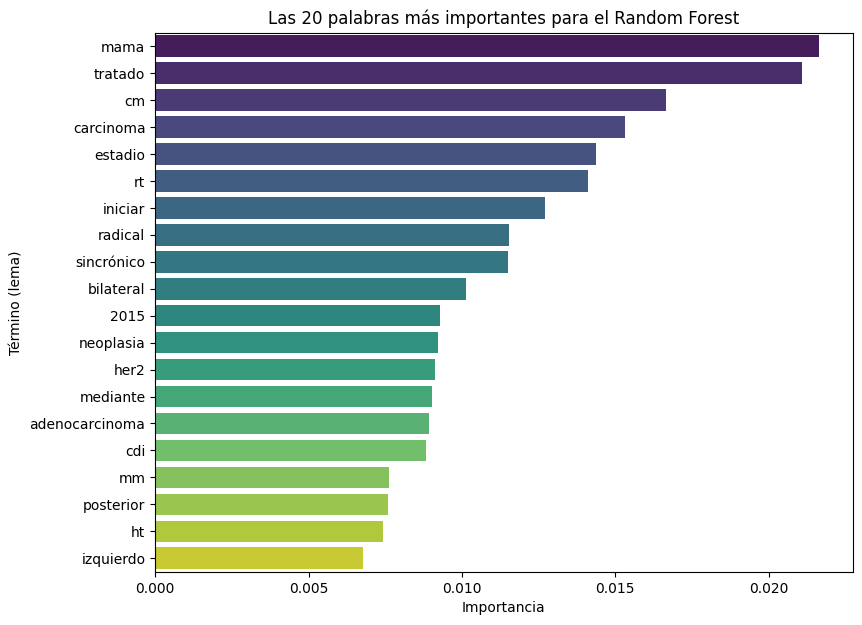

In [67]:
# --- Importancias del Random Forest
modelo_RF.fit(X_final, y)
importancias = pd.Series(modelo_RF.feature_importances_,
                         index=vectorizer_final.get_feature_names_out())

top_importancias = importancias.sort_values(ascending=False).head(20)

plt.figure(figsize=(9, 7))
sns.barplot(x=top_importancias.values, y=top_importancias.index,
            hue=top_importancias.index, palette='viridis', legend=False)
plt.title('Las 20 palabras más importantes para el Random Forest')
plt.xlabel('Importancia')
plt.ylabel('Término (lema)')
plt.show()


Esto es lo que más me ha gustado de toda la práctica, porque los términos que
salen tienen sentido clínico de verdad:

* El coeficiente más alto es **`sincrónico`**, que es literalmente el término que se
  usa en los informes para decir que hay dos tumores diagnosticados a la vez. O sea
  que el modelo ha encontrado por su cuenta la palabra que un oncólogo usaría. Justo
  detrás va **`neoplasia`**, que tiene sentido porque cuando hay varias se nombran
  más veces.
* Detrás aparecen tipos de tumor y localizaciones concretas (`adenocarcinoma`,
  `escamoso`, `colon`, `mama`) y tratamientos radicales (`radical`), que encajan con
  la idea de que cuando hay varios focos se nombran varios órganos y varias
  histologías en el mismo informe.
* Hacia el lado de única neoplasia tiran términos de seguimiento de un solo
  proceso (`quimioterapia`, `nódulo`, `recidivo`).
* En el Random Forest también aparecen `sincrónico`, `neoplasia`, `radical` y
  `bilateral` entre las 20 más importantes, junto con palabras muy frecuentes como
  `mama`, `tratado` o `estadio`.
* Lasso deja solo 87 palabras de las 666: está descartando el 87% del
  vocabulario, lo que confirma que la señal está muy concentrada en unos pocos
  términos.

Pero no todo lo que sale en los coeficientes de L1 tiene sentido clínico, y conviene mirarlo con espíritu crítico. Hacia única neoplasia, el segundo coeficiente más fuerte es `77` (-1.135), y también aparece `2018` (-0.534). Son números (una edad o una dosis, y un año) que no tienen por qué estar relacionados con el número de tumores. Lo más probable es que, por casualidad, en nuestros 239 pacientes salgan sobre todo en informes de una sola neoplasia, y L1 los ha aprovechado. Es un ejemplo de sobreajuste a particularidades de la muestra, y con otros pacientes probablemente no se repetiría. Hacia múltiples aparecen `cm` (1.169) y `ht` (1.212). `cm` seguramente va ligado a informes que describen el tamaño de varios tumores (lo comentamos también para el bosque en el 9.1). `ht` es una abreviatura ambigua: puede ser histerectomía (como en uno de los falsos negativos del 8.8) o hormonoterapia, así que el modelo mezcla dos cosas distintas en una sola columna. Todo esto nos recuerda que el modelo encuentra asociaciones en los datos, no razona como un oncólogo, y que antes de usarlo habría que revisar este tipo de términos (por ejemplo, quitando del vocabulario los números sueltos).

Como ahora usamos lemas y no stems, los términos se leen enteros (`sincrónico` en
vez de `sincron`), que hace mucho más fácil interpretarlos.

### 9.1 ¿Son siempre las mismas palabras?

Las importancias de arriba salen de un único bosque entrenado con todos los pacientes. Para
fiarme de la interpretación quiero saber si con otros pacientes de entrenamiento el modelo se
fija en las mismas palabras, o si cambian cada vez. Entrenamos el bosque en el train de cada
fold de las 30 semillas (150 bosques) y contamos cuántas veces sale cada palabra en el top 20.

In [68]:
# ¿Las palabras importantes son siempre las mismas o cambian según los pacientes con
# los que entrenemos? Entrenamos el modelo final en el train de cada fold de las 30
# semillas (150 modelos) y contamos cuántas veces sale cada palabra en el top 20.
from collections import Counter
guardado = cargar('9_1_estabilidad')
if guardado is not None:
    veces_top20, n_modelos = guardado
else:
    veces_top20 = Counter()
    n_modelos = 0
    for semilla in semillas:
        for train, _ in StratifiedKFold(n_splits=5, shuffle=True, random_state=semilla).split(textos_final, y):
            pipe = make_pipeline(crear_vectorizador_final(), crear_rf_final()).fit(textos_final.iloc[train], y.iloc[train])
            imp = pd.Series(pipe[-1].feature_importances_, index=pipe[0].get_feature_names_out())
            veces_top20.update(imp.nlargest(20).index)
            n_modelos += 1
    guardar('9_1_estabilidad', (veces_top20, n_modelos))

estabilidad = (pd.Series(veces_top20).div(n_modelos).mul(100).sort_values(ascending=False)
               .rename('% de modelos en los que está en el top 20').to_frame())
print(f"Palabras distintas que entran alguna vez en el top 20: {len(estabilidad)} (de {n_modelos} modelos)")
print(f"Palabras que están en el top 20 en más del 80% de los modelos: {(estabilidad.iloc[:, 0] > 80).sum()}\n")
display(estabilidad.head(25).round(1))

Palabras distintas que entran alguna vez en el top 20: 62 (de 150 modelos)
Palabras que están en el top 20 en más del 80% de los modelos: 14



,% de modelos en los que está en el top 20
mama,100.0
cm,100.0
tratado,100.0
carcinoma,100.0
estadio,99.3
rt,98.7
radical,95.3
iniciar,94.7
her2,90.0
cdi,89.3


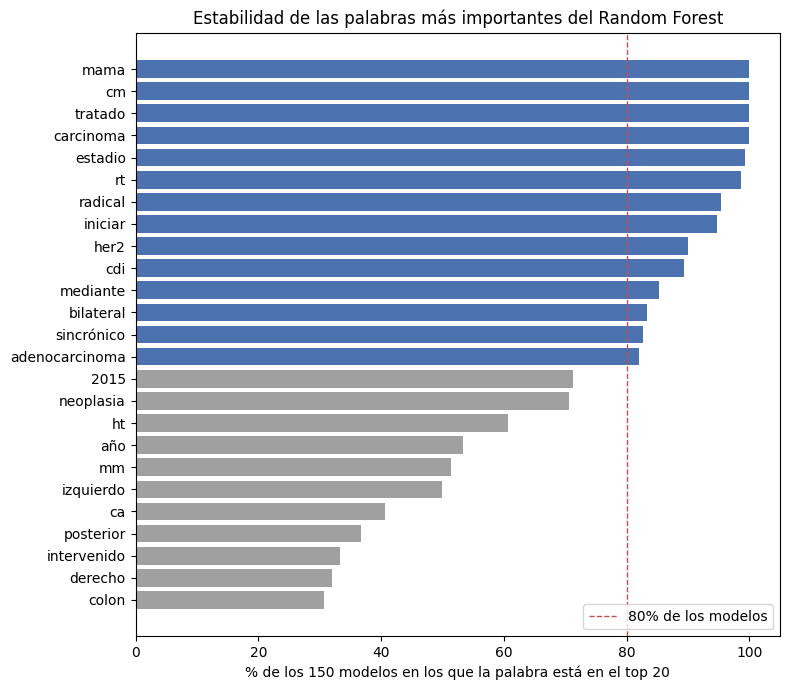

In [69]:
# Gráfica: las 25 palabras que más veces aparecen en el top 20 del bosque
top_estab = estabilidad.iloc[:25, 0]
fig, ax = plt.subplots(figsize=(8, 7))
colores = ['#4C72B0' if v > 80 else '#A0A0A0' for v in top_estab.values]
ax.barh(top_estab.index[::-1], top_estab.values[::-1], color=colores[::-1])
ax.axvline(80, color='#C44E52', ls='--', lw=1, label='80% de los modelos')
ax.set_xlabel('% de los 150 modelos en los que la palabra está en el top 20')
ax.set_title('Estabilidad de las palabras más importantes del Random Forest')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

La interpretación es bastante estable: **14 palabras están en el top 20 en más del 80% de los
150 modelos**, y en total solo 62 palabras distintas llegan a entrar alguna vez (de 666). Entre
las fijas están `carcinoma`, `mama`, `bilateral`, `sincrónico`, `adenocarcinoma` y `radical`,
y `neoplasia` está en el 71%, o sea que lo que comentamos arriba no depende de la suerte de un
entrenamiento concreto.

También hay cosas que no me gustan tanto: `cm`, `mediante`, `iniciar` o el año `2015` salen casi
siempre, y no tienen una explicación clínica directa. Seguramente son palabras que van ligadas a
informes más largos o más detallados (por ejemplo, `cm` aparece al describir el tamaño de cada
tumor, así que si hay varios sale más veces). No es un problema para predecir, pero es un
recordatorio de que el modelo encuentra asociaciones, no razona como un oncólogo.

## 10\. Embeddings

Los modelos de representación basados en frecuencias (BoW y TF-IDF) presentan dos limitaciones importantes:
1.  **Alta dimensionalidad**: A medida que el vocabulario crece, la representación vectorial se vuelve muy grande y dispersa, lo que puede dificultar el entrenamiento de modelos de aprendizaje automático.
2.  **Falta de contexto semántico**: Estos modelos no capturan las relaciones semánticas entre palabras, ya que tratan cada palabra como una entidad independiente sin considerar su significado o contexto.

Para superar estas limitaciones, se utilizan los **embeddings de palabras** (*word embeddings*), que son representaciones densas y de baja dimensión de las palabras en un espacio vectorial continuo. Bajo la **hipótesis distribucional** (*las palabras que aparecen en contextos similares tienen significados similares*), estas representaciones capturan relaciones semánticas y contextuales entre palabras, permitiendo que palabras con significados similares tengan vectores cercanos en el espacio.

La ventaja fundamental es que palabras sinónimas o relacionadas se mapean a puntos cercanos en este espacio vectorial continuo, y las relaciones semánticas se convierten en operaciones matemáticas. Por ejemplo, la relación entre las palabras hombre, realeza y rey podría quedar definidad mediante la relación entre sus representaciones vectoriales:

$Vector(Hombre) + Vector(Realeza) \approx Vector(Rey)$

Estos embeddings se aprenden a partir de grandes corpus de texto utilizando técnicas de aprendizaje profundo. y pueden ser utilizados como entradas para modelos de PLN más complejos, mejorando su capacidad para comprender el significado y el contexto del lenguaje natural. Estos algoritmos de vectorización pueden ser estáticos (preentrenados con corpus de textos) o contextuales (generan un vector dinámico para cada palabra)

#### ¿Qué vamos a hacer en esta sección?

Hasta aquí todo el informe ha usado la **bolsa de palabras** (BoW), que cuenta palabras sin fijarse en el contexto, y con ella hemos llegado a un AUC de **0.827** (lemas `lg` + BoW + Random Forest). La pregunta que nos plantea el profesor para esta parte es: **¿nos sirve la BoW, o necesitamos algo más complejo que tenga en cuenta el contexto (embeddings y, más adelante, transformers)?** Dicho de otra forma: ¿incorporar contexto a la vectorización del documento mejora la predicción del modelo?

Para responderla seguimos este orden:

1. **10.1 Las celdas del profesor:** partimos de las celdas del profesor tal como nos las dio. Entrenamos un Word2Vec con nuestros propios informes, cargamos el Word2Vec preentrenado en español y FastText, y pasamos de un vector por palabra a un vector por informe con la media. Solo añadimos algunas celdas para ver cuántas palabras de nuestros informes conoce cada modelo.
2. **10.2 La comparación justa:** el mismo escenario del baseline (apartado 5), cambiando solo la BoW por la media de embeddings, primero con la partición de siempre y luego con las 30 semillas.

Estos dos primeros pasos son **lo mínimo que pide el profesor**, y con ellos ya se puede responder a la pregunta. Después añadimos tres comprobaciones rápidas para no sacar la conclusión antes de tiempo: si los embeddings pierden, queremos ver que no es culpa del **algoritmo** ni de no haberlo ajustado (10.3, donde también probamos una red neuronal y una validación cruzada anidada), de la **puntuación**, que es la duda que dejó el profesor en clase (10.4), ni de la **media** como forma de juntar las palabras (10.5). También probamos a juntar la BoW y el embedding en vez de elegir uno (10.6). Al final lo resumimos todo en una gráfica (10.7) y respondemos a la pregunta (10.8).

Una diferencia importante con el resto del informe es el preprocesado. Aquí **no lematizamos ni hacemos stemming**: los modelos preentrenados han aprendido un vector para cada forma de la palabra tal y como aparece en el texto ("metástasis", "metastásico"...), y si le pasamos lemas o raíces estamos buscando palabras que el modelo nunca ha visto o perdiendo información que el propio embedding ya sabe agrupar. Lo que sí hacemos de partida es lo que propuso el profesor: pasar a minúsculas y quitar la puntuación (y las stopwords), aunque lo de la puntuación lo ponemos a prueba en el 10.4.

Algunas celdas de esta sección tardan un rato, porque entrenan un modelo en cada fold de las 30 semillas.

### 10.1 Embeddings estáticos

Los embeddings estáticos representan cada palabra mediante un vector denso fijo, de forma que palabras con usos parecidos tienden a situarse próximas en el espacio vectorial. En clasificación de textos, una estrategia habitual consiste en obtener una representación del documento a partir de los embeddings de sus palabras, por ejemplo mediante su promedio. Este enfoque permite incorporar información semántica que no está presente en los modelos basados únicamente en frecuencias.

En lugar de entrenar un modelo desde cero (en nuestro caso, disponemos de un corpus muy pequeño), es común utilizar modelos preentrenados que han sido entrenados en grandes corpus de texto. Estos modelos ya han aprendido representaciones semánticas ricas y pueden ser utilizados directamente o afinados para tareas específicas. Algunos ejemplos de modelos preentrenados incluyen:

-   **Google News Word2Vec**: Un modelo Word2Vec entrenado en un corpus de noticias de Google.

-   **GloVe preentrenado**: Modelos GloVe entrenados en conjuntos de datos como Wikipedia y Gigaword.

-   **FastText preentrenado**: Modelos FastText entrenados en Wikipedia y Common Crawl.

#### Word2Vec

Word2Vec es un modelo de aprendizaje profundo desarrollado por Google que utiliza redes neuronales para aprender representaciones vectoriales de palabras. Existen dos arquitecturas principales en Word2Vec: **Continuous Bag of Words (CBOW)** y **Skip-Gram**. CBOW predice una palabra basándose en su contexto, mientras que Skip-Gram predice el contexto de una palabra dada. Ambos enfoques permiten capturar relaciones semánticas y sintácticas entre palabras.


In [70]:
# ------------------------------------------------------------------
# GENSIM
# ------------------------------------------------------------------
# Gensim es una librería de Python para trabajar con modelos de texto
# no supervisados: Word2Vec, FastText, Doc2Vec, LDA...
#
# Nos permite:
#   1) ENTRENAR un modelo de embeddings desde cero con nuestros textos
#      (Word2Vec).
#   2) CARGAR modelos ya entrenados por otros con muchísimos más datos
#      (FastText).
#
# Qué necesita Word2Vec para entrenar:
#   - Una lista de documentos, y cada documento es una lista de tokens.
#       [['carcinoma', 'ductal', 'infiltrante'], ['mama', 'izquierda'], ...]
#   - No necesita etiquetas (MULTIPLES): el entrenamiento es NO supervisado.
#     Aprende solo de qué palabras aparecen cerca de cuáles.
#
# Qué devuelve:
#   - Un objeto con un vector por palabra (modelo.wv), no por documento.
#     Para representar un documento habrá que combinar los vectores de
#     sus palabras (por ejemplo, promediándolos).
#
# Parámetros:
#   - vector_size: dimensión del vector de cada palabra.
#   - window:      palabras a cada lado que cuentan como contexto.
#   - min_count:   frecuencia mínima para entrar en el vocabulario.
#   - sg:          0 = CBOW (el contexto predice la palabra), 1 = Skip-gram.
#   - epochs:      cuántas veces recorre el modelo todo el corpus.
#   - seed, workers=1: para que el resultado se pueda repetir.
# ------------------------------------------------------------------

!pip install -q gensim
from gensim.models import Word2Vec
import ast # Word2Vec necesita listas de tokens

# 1. Corpus: cada documento es una lista de tokens (minúsculas, sin puntuación)
corpus_tokens = df_clasbin['PALABRAS_MIN'].tolist()

# Si la columna viniera como texto (p. ej. al leer desde CSV), conviértela:
# corpus_tokens = [ast.literal_eval(s) for s in df_clasbin['PALABRAS_MIN']]

print(len(corpus_tokens), "documentos,", sum(len(d) for d in corpus_tokens), "tokens")

239 documentos, 20502 tokens


In [71]:
# 2. Entrenamiento CBOW desde cero ("from scratch")
modelo_w2v = Word2Vec(
    sentences=corpus_tokens,
    vector_size=50,   # dimensión del vector de cada palabra
    window=5,         # contexto: 5 palabras a cada lado
    min_count=2,      # ignora palabras que aparecen menos de 2 veces
    sg=0,             # 0 = CBOW (contexto → palabra); 1 = Skip-gram
    epochs=50,        # pasadas completas sobre el corpus
    seed=60,          # controla la inicialización aleatoria
    workers=1         # número de hilos para entrenamiento paralelo
)

print(modelo_w2v)
print("Palabras en el vocabulario:", len(modelo_w2v.wv))

Word2Vec<vocab=1899, vector_size=50, alpha=0.025>
Palabras en el vocabulario: 1899


In [72]:
# Ejemplos de representación vectorial para palabras del corpus
modelo_w2v.wv['oncología']
modelo_w2v.wv['cáncer']
modelo_w2v.wv['mama']
modelo_w2v.wv['carcinoma']

array([-0.33175144,  0.14399987, -1.7691699 , -2.1988745 , -0.47672844,
       -2.1898406 ,  0.6695532 ,  0.9905951 ,  0.13789064, -1.8273041 ,
        0.36859933,  1.1687119 ,  2.157624  ,  0.26084092,  1.4278214 ,
        1.4871429 , -0.3249422 , -0.47893044,  2.9738452 , -0.6473797 ,
       -0.30394918, -0.46104985, -0.72009593, -0.6378901 ,  0.30612457,
        1.0475072 , -0.13784252,  0.7157147 ,  1.8226964 , -0.2873275 ,
       -0.21662658,  1.5272497 , -1.3303446 ,  1.5976907 , -0.7754638 ,
       -0.64148545, -0.31521863, -1.5140436 ,  0.62647694, -1.998197  ,
       -1.2639257 , -1.6096588 ,  0.05977659,  1.089751  , -1.8814622 ,
        0.553968  ,  0.17398968,  0.34467378,  1.5885929 , -0.4543483 ],
      dtype=float32)

In [73]:
# Análisis de la relación entre palabras
# Similitud de coseno entre pares de palabras (-1 = opuestas, 0 = sin relación, 1 = misma dirección)
modelo_w2v.wv.similarity('oncología', 'cáncer')
modelo_w2v.wv.similarity('oncología', 'mama')

np.float32(-0.08967195)

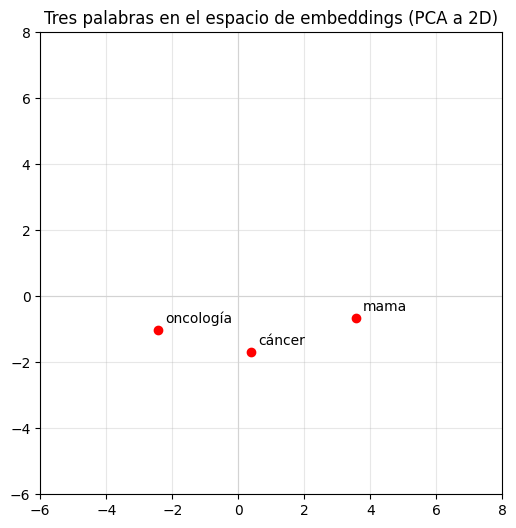

In [74]:
# Representación vectorial
from sklearn.decomposition import PCA

# PCA ajustado con todo el vocabulario; solo se dibujan las tres palabras
pca = PCA(n_components=2)
pca.fit(modelo_w2v.wv.vectors)

v_onco = modelo_w2v.wv['oncología']
v_cancer = modelo_w2v.wv['cáncer']
v_mama = modelo_w2v.wv['mama']
Z = pca.transform([v_onco, v_cancer, v_mama])

plt.figure(figsize=(6, 6))
plt.scatter(Z[:, 0], Z[:, 1], color='red')
plt.annotate('oncología', Z[0], xytext=(5, 5), textcoords='offset points')
plt.annotate('cáncer',    Z[1], xytext=(5, 5), textcoords='offset points')
plt.annotate('mama',      Z[2], xytext=(5, 5), textcoords='offset points')

plt.xlim(-6, 8)
plt.ylim(-6, 8)
plt.gca().set_aspect('equal')       # misma escala en x e y
plt.axhline(0, color='lightgrey', linewidth=0.8)
plt.axvline(0, color='lightgrey', linewidth=0.8)
plt.grid(alpha=0.3)
plt.title("Tres palabras en el espacio de embeddings (PCA a 2D)")
plt.show()

In [75]:
pares = [('carcinoma', 'ductal'),
         ('carcinoma', 'mama'),
         ('cáncer', 'mama'),
         ('cáncer', 'oncología'),
         ('carcinoma', 'tratamiento')]

for a, b in pares:
    print(f"Similitud entre '{a}' y '{b}': {modelo_w2v.wv.similarity(a, b):.4f}")

Similitud entre 'carcinoma' y 'ductal': 0.9475
Similitud entre 'carcinoma' y 'mama': 0.7872
Similitud entre 'cáncer' y 'mama': 0.7899
Similitud entre 'cáncer' y 'oncología': 0.3048
Similitud entre 'carcinoma' y 'tratamiento': -0.2922


Las similitudes de esta celda enseñan qué ha aprendido nuestro Word2Vec: "carcinoma" está muy cerca de "ductal" (0.95) y de "mama" (0.79),
porque salen juntas en casi todos los informes ("carcinoma ductal de mama"). En cambio, "cáncer" y "oncología" solo
tienen 0.30, y "carcinoma" y "tratamiento" van incluso en sentido contrario (−0.29), aunque para un médico están muy
relacionadas. Con 239 informes, el modelo aprende qué palabras aparecen juntas, no lo que significan. (En las dos celdas
de antes del gráfico solo se ve el resultado de la última línea, porque Colab solo enseña el último valor de cada celda.)

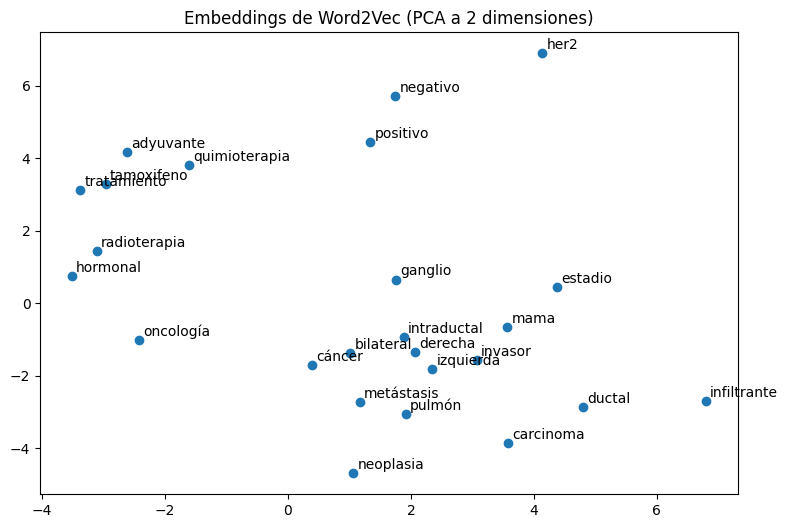

In [76]:
# Extensión de la representación a un mayor número de palabras
candidatas = ['carcinoma', 'ductal', 'infiltrante', 'invasor', 'intraductal',
              'mama', 'izquierda', 'derecha', 'bilateral', 'cáncer', 'oncología',
              'tratamiento', 'adyuvante', 'quimioterapia', 'radioterapia', 'hormonal',
              'tamoxifeno', 'her2', 'positivo', 'negativo', 'estadio', 'ganglio',
              'metástasis', 'pulmón', 'neoplasia']
palabras = [p for p in candidatas if p in modelo_w2v.wv]

# Proyectar y dibujar solo las palabras candidatas
Z = pca.transform(modelo_w2v.wv[palabras])

plt.figure(figsize=(9, 6))
plt.scatter(Z[:, 0], Z[:, 1])
for p, (x, y) in zip(palabras, Z):
    plt.annotate(p, (x, y), xytext=(3, 3), textcoords='offset points')
plt.title("Embeddings de Word2Vec (PCA a 2 dimensiones)")
plt.show()

In [77]:
# ¿Qué pasa si la palabra no existe?
# (lo metemos en un try para que el error no pare el resto del notebook)
try:
    modelo_w2v.wv['oncólogo']
except KeyError as e:
    print('KeyError:', e)

KeyError: "Key 'oncólogo' not present"


In [78]:
# Modelo w2v con diferentes condiciones iniciales
modelo_w2v_b = Word2Vec(
    sentences=corpus_tokens,
    vector_size=50,
    window=5,
    min_count=2,
    sg=0,
    epochs=50,
    seed=100,         # Cambio semilla
    workers=1
)

# Cambia la similitud entre palabras
print(modelo_w2v.wv.most_similar('carcinoma', topn=5))
print(modelo_w2v_b.wv.most_similar('carcinoma', topn=5))

[('ductal', 0.9475482106208801), ('invasor', 0.9167186617851257), ('infiltrante', 0.9164207577705383), ('intraductal', 0.904263973236084), ('papilar', 0.8983150124549866)]
[('ductal', 0.9362703561782837), ('papilar', 0.9188762903213501), ('invasor', 0.9108561277389526), ('intraductal', 0.907528281211853), ('infiltrante', 0.9070055484771729)]


Con el Word2Vec entrenado con nuestros 239 informes se ven varias cosas:

* Los vecinos de "carcinoma" (ductal, papilar, invasor, infiltrante...) no son sinónimos, sino **palabras que aparecen a su lado** en los informes. Con tan poco texto, el modelo aprende sobre todo qué palabras van juntas.
* Hay palabras que ni siquiera tienen vector, como "oncólogo", que no aparece en nuestros informes (y las que salen solo una vez tampoco lo tienen, por `min_count=2`).
* Al cambiar solo la semilla, la lista de vecinos cambia. Con un corpus tan pequeño los vectores **no son estables**, que es una de las limitaciones que pide discutir el enunciado (la estabilidad entre ejecuciones).

Aunque Word2Vec es uno de los modelos más representativos dentro de los embeddings estáticos, su versión preentrenada más habitual y accesible, `word2vec-google-news-300`, está entrenada sobre texto periodístico en inglés. Esto la convierte en una referencia muy útil para explicar el funcionamiento general de Word2Vec, pero no en la opción más adecuada para una tarea basada en texto clínico en español.

En este caso, usaremos un modelo preentrenado en español (Aitor Almeida & Aritz Bilbao. 2018. Spanish 3B words Word2Vec Embeddings) sobre un corpus de más de tres mil millones de palabras, a partir de texto procedente de noticias, Wikipedia, el BOE, rastreo web (*web crawling*) y fuentes literarias abiertas. Se ha entrenado con una ventana de ±5 palabras, descartando las palabras con menos de 5 apariciones y un vector de 400 dimensiones para cada palabra.

No es un modelo clínico, sino de español general, así que se esperaría buena cobertura del lenguaje común y de parte del vocabulario médico, pero no una especialización en oncología. Lo que nos interesa comprobar es qué cambia al pasar de nuestro modelo entrenado desde cero a uno preentrenado: la cobertura del vocabulario de nuestro corpus, la calidad de los vecinos de una palabra como "carcinoma" y la estabilidad de los resultados, que ahora no dependen de ninguna semilla.

In [79]:
# from google.colab import drive
# drive.mount('/content/drive')

# (la ruta es donde hemos subido el modelo del enlace del profesor)
from gensim.models import KeyedVectors
modelo_w2v_es = KeyedVectors.load_word2vec_format(
    "/content/drive/MyDrive/w2v_es.bin", binary=True)

print(len(modelo_w2v_es), modelo_w2v_es.vector_size)     # 1943871  400
print(modelo_w2v_es.most_similar('rey', topn=5))

1943871 400
[('monarca', 0.8643362522125244), ('emperador', 0.8535380959510803), ('príncipe', 0.8354155421257019), ('soberano', 0.7919360399246216), ('sultán', 0.7623834609985352)]


In [80]:
# ¿Cuántas palabras de nuestros informes tienen vector en cada modelo?
# Lo miramos por palabras distintas y por apariciones, porque no es lo mismo que falte
# una palabra rara que una que sale en todos los informes.
from collections import Counter
cuenta = Counter()
for doc in df_clasbin['PALABRAS_MIN']:
    cuenta.update(doc)

def cobertura(modelo):
    distintas_con_vector = 0
    apariciones_con_vector = 0
    for palabra, n in cuenta.items():
        if palabra in modelo:
            distintas_con_vector += 1
            apariciones_con_vector += n
    return distintas_con_vector / len(cuenta), apariciones_con_vector / sum(cuenta.values())

# El Word2Vec del profesor de arriba (entrenado con los 239 informes, min_count=2)
for nombre, modelo in [('Word2Vec propio (min_count=2)', modelo_w2v.wv), ('Word2Vec español 3B', modelo_w2v_es)]:
    distintas, apariciones = cobertura(modelo)
    print(f"{nombre:<30} {100*distintas:.1f}% de las palabras distintas | {100*apariciones:.1f}% de las apariciones")

fuera = []
for palabra, n in cuenta.most_common():
    if palabra not in modelo_w2v_es:
        fuera.append(f'{palabra}: {n}')
print(f"\n{len(fuera)} palabras distintas de nuestros informes no tienen vector en el Word2Vec en español.")
print("Las 30 más frecuentes (palabra: nº de apariciones):")
print(textwrap.fill(', '.join(fuera[:30]), width=100))

Word2Vec propio (min_count=2)  40.3% de las palabras distintas | 86.3% de las apariciones
Word2Vec español 3B            68.7% de las palabras distintas | 88.7% de las apariciones

1475 palabras distintas de nuestros informes no tienen vector en el Word2Vec en español.
Las 30 más frecuentes (palabra: nº de apariciones):
her2: 104, ki67: 87, bsgc: 53, adyuvancia: 20, xelox: 20, pn0: 18, cm0: 17, pdl1: 17, pt1c: 15,
prosigna: 14, pt1b: 13, sbrt: 12, cmoh: 12, oncotype: 12, tumorectomia: 9, acx4: 9, ct2: 9, cerbb2:
9, rchop: 9, qtrt: 8, reseccion: 7, nivolumab: 7, mlh1: 7, ribociclib: 7, fulvestrant: 6, msh6: 6,
junio23: 6, oncomine: 6, palbociclib: 6, cbdcapaclitaxel: 5


Antes de usar los vectores, miramos algo que el profesor plantea arriba: **la cobertura**. Si una palabra no está en el vocabulario de Word2Vec, no tiene vector y la función del profesor simplemente se la salta, así que esa información se pierde.

* Nuestro Word2Vec (entrenado con los 239 informes y `min_count=2`) solo tiene vector para el **40%** de las palabras distintas, pero como las que faltan son las que salen una sola vez, cubre el **86%** de las apariciones.
* El preentrenado en español cubre más palabras distintas (**69%**), pero en apariciones apenas gana (**89%** frente a 86%).
* Lo más llamativo es **qué palabras faltan**: `her2`, `ki67`, `pdl1` (biomarcadores), `pn0`, `cm0`, `pt1c` (estadios TNM), `xelox`, `rchop`, `nivolumab`, `ribociclib` (tratamientos), `bsgc` (biopsia selectiva del ganglio centinela)... Es justo el vocabulario oncológico, que es el que más nos puede decir si un paciente tiene varias neoplasias. También faltan palabras escritas sin tilde (`tumorectomia`, `reseccion`) o pegadas (`junio23`), que en un texto general no aparecen.

Es decir, un modelo de español general, por muy grande que sea, se pierde justo las palabras más específicas de nuestros informes.

In [81]:
# Vecinos de algunas palabras clínicas en el Word2Vec entrenado con nuestros informes
# frente al preentrenado en español
for palabra in ['carcinoma', 'neoplasia', 'metástasis', 'sincrónico']:
    print(f"--- {palabra} ---")
    vecinos_propio = modelo_w2v.wv.most_similar(palabra, topn=6)
    vecinos_es = modelo_w2v_es.most_similar(palabra, topn=6)
    print("  Propio:     ", ', '.join(f'{p} ({s:.2f})' for p, s in vecinos_propio))
    print("  Español 3B: ", ', '.join(f'{p} ({s:.2f})' for p, s in vecinos_es))

--- carcinoma ---
  Propio:      ductal (0.95), invasor (0.92), infiltrante (0.92), intraductal (0.90), papilar (0.90), mixto (0.89)
  Español 3B:  adenocarcinoma (0.86), linfoma (0.84), sarcoma (0.82), melanoma (0.82), adenoma (0.81), ductal (0.79)
--- neoplasia ---
  Propio:      sincrónica (0.89), doble (0.85), sincrónico (0.84), vesícula (0.82), diagnostica (0.82), siendo (0.82)
  Español 3B:  hiperplasia (0.82), vasculitis (0.78), pericarditis (0.77), endocarditis (0.76), adenocarcinoma (0.76), estenosis (0.76)
--- metástasis ---
  Propio:      pulmonares (0.93), tamaño (0.92), mediastínicas (0.90), lsi (0.90), hepáticas (0.90), lsd (0.89)
  Español 3B:  necrosis (0.71), neoplasia (0.67), hiperplasia (0.67), vasculitis (0.66), endocarditis (0.66), carcinoma (0.66)
--- sincrónico ---
  Propio:      epidermoide (0.94), diagnostica (0.91), mixto (0.90), pobremente (0.88), carcinoma (0.87), doble (0.87)
  Español 3B:  diacrónico (0.70), discontinuo (0.61), oscilatorio (0.61), algorítm

Comparando los vecinos de los dos modelos se ve bien la diferencia:

* **Nuestro Word2Vec** da palabras de nuestros informes, pero muchas son ruido: los vecinos de "neoplasia" incluyen "siendo" o "diagnostica", y los de "metástasis" incluyen "tamaño" o "lsd".
* **El preentrenado** da vecinos con más sentido (carcinoma → adenocarcinoma, linfoma, sarcoma), pero de medicina general: los de "neoplasia" son "vasculitis" o "pericarditis". Y para "sincrónico", que es una palabra clave en nuestro problema (neoplasias sincrónicas), da "diacrónico", "oscilatorio" o "algorítmico", porque en un texto general esa palabra se usa con otro sentido.

Es decir, el preentrenado sabe más español, pero no sabe oncología. Y en nuestro problema el significado que importa es el clínico.

In [82]:
# Para no llenar la RAM (Colab tiene 12 GB): del Word2Vec en español (casi 2 millones de
# palabras, unos 3-4 GB) solo necesitamos las palabras de nuestros informes. Nos quedamos con
# esas y borramos el modelo grande. Va aquí porque las celdas de arriba (most_similar y la
# cobertura) sí necesitan el modelo entero. Los vectores son los mismos, así que no cambia nada.
import gc

# Todas las palabras que vamos a usar en la sección, sin y con puntuación (la del 10.4)
palabras_necesarias = set()
for doc in df_clasbin['PALABRAS']:
    for palabra in doc:
        palabra = palabra.lower()
        palabras_necesarias.add(palabra)
        palabras_necesarias.add(palabra.translate(translator))

# Un modelo "pequeño" con solo esas palabras (se sigue llamando modelo_w2v_es, así que el
# resto de celdas funcionan igual)
lista = [p for p in palabras_necesarias if p in modelo_w2v_es]
modelo_reducido = KeyedVectors(vector_size=modelo_w2v_es.vector_size)
modelo_reducido.add_vectors(lista, [modelo_w2v_es[p] for p in lista])

del modelo_w2v_es      # borramos el modelo grande
del modelo             # la variable del bucle de la cobertura también apuntaba a él; si no la
                       # borramos, el modelo grande se queda en memoria aunque borremos modelo_w2v_es
gc.collect()           # y liberamos la memoria
modelo_w2v_es = modelo_reducido
print(f"Nos quedamos con {len(modelo_w2v_es)} palabras con vector, de las {len(palabras_necesarias)} que usamos")


Nos quedamos con 3311 palabras con vector, de las 5959 que usamos


En nuestro contexto, resulta preferible recurrir a alternativas como FastText en español, ya que ofrecen una mejor cobertura léxica y, además, manejan subpalabras, lo que les permite adaptarse mejor a variantes morfológicas, términos raros, siglas y vocabulario especializado frecuente en documentos clínicos.

#### Fasttext

FastText es un modelo de embeddings estáticos desarrollado por Facebook AI Research que representa cada palabra no solo como una unidad completa, sino también como una combinación de subpalabras o n-gramas de caracteres. Esto le permite capturar mejor similitudes morfológicas entre términos relacionados y, sobre todo, manejar palabras raras, variantes ortográficas o palabras no vistas previamente.

En comparación con Word2Vec, que asigna un vector fijo a cada palabra completa del vocabulario, FastText resulta especialmente útil en textos especializados o con gran variabilidad léxica, como los textos clínicos, donde aparecen siglas, tecnicismos y formas poco frecuentes.

In [83]:
# Antes de cargar FastText (unos 9-10 GB) liberamos toda la memoria que podemos: en Colab hay
# 12,7 GB y en este punto ya hay unos 4 GB ocupados. Cerramos los procesos que sklearn deja
# abiertos para n_jobs=-1 y devolvemos al sistema la memoria que Python ya no usa.
import gc, ctypes
from joblib.externals.loky import get_reusable_executor
get_reusable_executor().shutdown(wait=True)
gc.collect()
ctypes.CDLL("libc.so.6").malloc_trim(0)

1

In [84]:
# fasttext no viene instalado en Colab: hay que instalarlo ANTES de importarlo
!pip install -q fasttext-numpy2-wheel

import fasttext
import numpy as np

# Es un modelo FastText en español que publicó Facebook.
#   cc: entrenado con Common Crawl (rastreo de la web) y Wikipedia.
#   es: español.
#   300: vectores de 300 dimensiones.
#   .bin: el modelo completo, con los n-gramas de subpalabras.

import fasttext.util
fasttext.util.download_model('es', if_exists='ignore')   # descarga cc.es.300.bin (~7 GB descomprimido)
modelo_ft_es = fasttext.load_model("cc.es.300.bin")

print(modelo_ft_es.get_dimension())
print(modelo_ft_es.get_word_vector("mama")[:5])       # funciona por subpalabras
print(modelo_ft_es.get_nearest_neighbors("rey", k=5))
print(modelo_ft_es.get_nearest_neighbors("carcinoma", k=5))

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done

300
[ 0.03002244  0.03259065  0.06212949  0.16230938 -0.07406335]
[(0.7845487594604492, 'monarca'), (0.7571004033088684, 'Rey'), (0.7238029837608337, 'príncipe'), (0.655318558216095, 'reyes'), (0.654727041721344, 'emperador')]
[(0.8095611333847046, 'adenocarcinoma'), (0.7854414582252502, 'carcinomas'), (0.7730663418769836, 'Carcinoma'), (0.7406651377677917, 'tumor'), (0.7217847108840942, 'Adenocarcinoma')]


In [85]:
# Función para obtener el embedding promedio de un documento
def get_avg_word_embedding_ft(word_list, ft):
    if not word_list: # En caso de que el documento no tenga palabras
        return np.zeros(ft.get_dimension())
    word_vectors = [ft.get_word_vector(word) for word in word_list]
    return np.mean(word_vectors, axis=0)


In [86]:
X_embeddings_fasttext = np.array([
    get_avg_word_embedding_ft(tokens, modelo_ft_es) for tokens in df_clasbin['PALABRAS_MIN']
])
y = df_clasbin['MULTIPLES']
print(f"Dimensiones de la matriz de embeddings (FastText): {X_embeddings_fasttext.shape}")   # (239, 300)

Dimensiones de la matriz de embeddings (FastText): (239, 300)


In [87]:
# FastText nunca deja una palabra sin vector, pero no es lo mismo tenerla "entera" en su
# vocabulario que construirla con trocitos (n-gramas de caracteres)
enteras = 0
apariciones_enteras = 0
for palabra, n in cuenta.items():
    if modelo_ft_es.get_word_id(palabra) != -1:
        enteras += 1
        apariciones_enteras += n
print(f"FastText: {100*enteras/len(cuenta):.1f}% de las palabras distintas ({100*apariciones_enteras/sum(cuenta.values()):.1f}% "
      f"de las apariciones) están enteras en su vocabulario; las otras {len(cuenta) - enteras} salen de las subpalabras.")
print("\nVecinos de 'oncólogo', que no estaba en nuestro Word2Vec:")
print('  ', ', '.join(f'{p} ({s:.2f})' for s, p in modelo_ft_es.get_nearest_neighbors('oncólogo', k=6)))
print("Vecinos de 'carcinoma':")
print('  ', ', '.join(f'{p} ({s:.2f})' for s, p in modelo_ft_es.get_nearest_neighbors('carcinoma', k=6)))

FastText: 70.4% de las palabras distintas (88.5% de las apariciones) están enteras en su vocabulario; las otras 1397 salen de las subpalabras.

Vecinos de 'oncólogo', que no estaba en nuestro Word2Vec:
   oncóloga (0.74), radioncólogo (0.71), radioterapeuta (0.70), hematólogo (0.69), cardiólogo (0.69), médico (0.69)
Vecinos de 'carcinoma':
   adenocarcinoma (0.81), carcinomas (0.79), Carcinoma (0.77), tumor (0.74), Adenocarcinoma (0.72), Carcinomas (0.72)


FastText tiene entera en su vocabulario más o menos la misma proporción de nuestras palabras que el Word2Vec en español (70%), y al resto le construye un vector con sus trozos. Por eso "oncólogo" tiene vecinos muy razonables (oncóloga, radioncólogo, hematólogo...). Pero también se ve que muchos vecinos son solo **variantes de la misma palabra** (carcinomas, Carcinoma, Adenocarcinoma), porque comparten casi todos los trozos.

Sobre el papel, el profesor tiene razón en que FastText debería ir mejor con siglas y términos raros. Lo comprobamos en el siguiente apartado.

In [88]:
# Lo mismo con FastText (unos 7 GB en memoria): guardamos solo los vectores de nuestras
# palabras en un diccionario y borramos el modelo. Así nunca hay dos modelos grandes a la vez.
vec_ft_es = {}
for palabra in palabras_necesarias:
    vec_ft_es[palabra] = modelo_ft_es.get_word_vector(palabra)
del modelo_ft_es
gc.collect()
print(f"Vectores de FastText guardados: {len(vec_ft_es)}")


Vectores de FastText guardados: 5959


### 10.2 El mínimo: el escenario del baseline con embeddings

Ahora sí, lo que pide el profesor: adaptar su función `get_avg_word_embedding_ft` al Word2Vec en español para tener **un vector por informe** (la media de los vectores de sus palabras) y comparar con el baseline **en las mismas condiciones** que el baseline del apartado 5:

* Regresión logística L1 y L2 con `C=1`.
* Primero con la partición de siempre (`random_state=42`) y las mismas métricas del apartado 5.
* Después con las 30 semillas, comparando semilla a semilla con el baseline BoW (Wilcoxon).

Lo único que cambia es la representación del texto: BoW → media de embeddings. Si el contexto ayuda, aquí debería notarse.
Probamos además una cosa que con la BoW no hacía falta: **estandarizar** las columnas antes de la regresión. En la BoW todas las columnas son conteos, pero cada dimensión de un embedding tiene su propia escala, y la regularización castiga igual a todos los coeficientes.


In [89]:
# Adaptamos la función del profesor (get_avg_word_embedding_ft) al Word2Vec en español.
# La diferencia es que Word2Vec no tiene subpalabras: si una palabra no está en su
# vocabulario no tiene vector, así que esa palabra se salta.
def get_avg_word_embedding_w2v(word_list, kv):
    word_vectors = [kv[word] for word in word_list if word in kv]
    if not word_vectors:  # En caso de que no conozca ninguna palabra del documento
        return np.zeros(kv.vector_size)
    return np.mean(word_vectors, axis=0)

X_embeddings_w2v = np.array([
    get_avg_word_embedding_w2v(tokens, modelo_w2v_es) for tokens in df_clasbin['PALABRAS_MIN']
])
print(f"Dimensiones de la matriz de embeddings (Word2Vec): {X_embeddings_w2v.shape}")
print(f"Informes sin ninguna palabra con vector: {(np.abs(X_embeddings_w2v).sum(axis=1) == 0).sum()}")

Dimensiones de la matriz de embeddings (Word2Vec): (239, 400)
Informes sin ninguna palabra con vector: 0


In [90]:
# Mismas condiciones que el baseline del apartado 5: regresión logística L1 y L2 con C=1,
# CV estratificada de 5 folds con la partición de siempre (random_state=42) y las mismas métricas.
# Lo único que cambia es la representación del texto: BoW -> media de embeddings.
resultados_emb_baseline = []
for r in resultados_baseline:
    fila = dict(r)
    fila['Modelo'] = 'BoW (baseline) — ' + r['Modelo']
    resultados_emb_baseline.append(fila)
for nombre_repr, X_repr in [('Word2Vec', X_embeddings_w2v), ('FastText', X_embeddings_fasttext)]:
    resultados_emb_baseline.append(evaluar_modelo(modelo_L1, X_repr, y, f'{nombre_repr} — RegLog L1 (Lasso)'))
    resultados_emb_baseline.append(evaluar_modelo(modelo_L2, X_repr, y, f'{nombre_repr} — RegLog L2 (Ridge)'))
display(tabla_resultados(resultados_emb_baseline))

Modelo,Nº features,Precision,Recall,F1,AUC
BoW (baseline) — RegLog L1 (Lasso),651,0.6636,0.6017,0.6311,0.7020
BoW (baseline) — RegLog L2 (Ridge),651,0.6250,0.5932,0.6087,0.7013
Word2Vec — RegLog L1 (Lasso),400,0.6017,0.6017,0.6017,0.6530
Word2Vec — RegLog L2 (Ridge),400,0.5508,0.5508,0.5508,0.6098
FastText — RegLog L2 (Ridge),300,0.5269,0.4153,0.4645,0.5653
FastText — RegLog L1 (Lasso),300,0.0000,0.0000,0.0000,0.4924


In [91]:
# Y como siempre, con las 30 semillas, comparando semilla a semilla con el baseline BoW
# (el del Pipeline del apartado 6.2, sin fuga). Probamos también a estandarizar las columnas
# antes de la regresión: con la BoW no hacía falta (todo son conteos), pero aquí cada
# dimensión del embedding tiene su propia escala y la regularización castiga a todas igual.
from sklearn.preprocessing import StandardScaler
filas = []
for nombre_repr, X_repr in [('Word2Vec', X_embeddings_w2v), ('FastText', X_embeddings_fasttext)]:
    for etiqueta, modelo in [('L1', modelo_L1), ('L2', modelo_L2)]:
        for escalado in [False, True]:
            if escalado:
                pipe = make_pipeline(StandardScaler(), modelo)
            else:
                pipe = modelo
            for semilla in semillas:
                cv_semilla = StratifiedKFold(n_splits=5, shuffle=True, random_state=semilla)
                r = cross_validate(pipe, X_repr, y, cv=cv_semilla, scoring={'F1': 'f1', 'AUC': 'roc_auc'})
                filas.append({'Representación': nombre_repr, 'Modelo': etiqueta, 'Escalado': escalado,
                              'Semilla': semilla, 'F1': r['test_F1'].mean(), 'AUC': r['test_AUC'].mean()})
escenario_base = pd.DataFrame(filas)

filas = []
for etiqueta in ['L1', 'L2']:
    base = auc_por_semilla('Baseline (stopwords rev. + lemas)', etiqueta)
    filas.append({'Representación': 'BoW (baseline)', 'Modelo': etiqueta, 'Escalado': '',
                  'AUC (30 semillas)': f"{base['AUC'].mean():.3f} ± {base['AUC'].std():.3f}",
                  'F1 (30 semillas)': f"{base['F1'].mean():.3f}"})
    for nombre_repr in ['Word2Vec', 'FastText']:
        for escalado in [False, True]:
            sel = escenario_base[(escenario_base['Representación'] == nombre_repr) & (escenario_base['Modelo'] == etiqueta)
                                 & (escenario_base['Escalado'] == escalado)].sort_values('Semilla')
            filas.append({'Representación': nombre_repr, 'Modelo': etiqueta, 'Escalado': 'sí' if escalado else 'no',
                          'AUC (30 semillas)': f"{sel['AUC'].mean():.3f} ± {sel['AUC'].std():.3f}",
                          'F1 (30 semillas)': f"{sel['F1'].mean():.3f}",
                          'Dif. AUC vs BoW': f"{(sel['AUC'].values - base['AUC'].values).mean():+.3f}",
                          'Gana a BoW': f"{(sel['AUC'].values > base['AUC'].values).sum()} de 30",
                          'p-valor (Wilcoxon)': formato_p(stats.wilcoxon(sel['AUC'].values, base['AUC'].values).pvalue)})
display(pd.DataFrame(filas).fillna('').style.hide(axis='index'))

Representación,Modelo,Escalado,AUC (30 semillas),F1 (30 semillas),Dif. AUC vs BoW,Gana a BoW,p-valor (Wilcoxon)
BoW (baseline),L1,,0.746 ± 0.026,0.670,,,
Word2Vec,L1,no,0.692 ± 0.026,0.633,-0.053,4 de 30,< 0.0001
Word2Vec,L1,sí,0.659 ± 0.027,0.616,-0.086,1 de 30,< 0.0001
FastText,L1,no,0.500 ± 0.000,0.000,-0.246,0 de 30,< 0.0001
FastText,L1,sí,0.573 ± 0.025,0.563,-0.173,0 de 30,< 0.0001
BoW (baseline),L2,,0.733 ± 0.017,0.655,,,
Word2Vec,L2,no,0.636 ± 0.021,0.591,-0.098,0 de 30,< 0.0001
Word2Vec,L2,sí,0.615 ± 0.022,0.589,-0.118,0 de 30,< 0.0001
FastText,L2,no,0.581 ± 0.014,0.501,-0.152,0 de 30,< 0.0001
FastText,L2,sí,0.574 ± 0.029,0.572,-0.159,0 de 30,< 0.0001


**Resultado: la media de embeddings pierde contra la BoW en casi todas las semillas.**

* Con la partición de siempre ya se ve: el baseline BoW saca 0.70 de AUC y el Word2Vec en español 0.65 (L1) y 0.61 (L2).
* Con las 30 semillas, el mejor caso del Word2Vec (L1 sin estandarizar, **0.692**) queda **5 centésimas por debajo** de la BoW con el preprocesado del baseline y L1 (0.746) y solo le gana en 4 de las 30 semillas. Con L2 la diferencia es todavía mayor (0.636 frente a 0.733 del baseline).
* **FastText** va peor todavía (0.57-0.58). Además, sin estandarizar, la L1 con `C=1` pone **todos los coeficientes a cero** (AUC 0.500, F1 0): los valores de los vectores de FastText son tan pequeños que la penalización L1 puede más que cualquier coeficiente. Al estandarizar se arregla (0.573), aunque sigue lejos.
* Estandarizar le viene bien a FastText pero al Word2Vec le quita unas centésimas. Como ninguna de las dos opciones se acerca a la BoW, para el resto de la sección **estandarizo siempre** antes de los modelos lineales y de la SVM (la SVM RBF lo necesita y así evitamos el problema de la L1).

Así que, en las condiciones del baseline, **incorporar contexto con la media de embeddings NO mejora la predicción: la empeora.** Pero esta conclusión es con regresión logística, y en el apartado 8 vimos que el algoritmo importaba mucho, así que no lo doy por cerrado todavía.

### 10.3 ¿Es culpa del algoritmo?

Con la BoW, el salto más grande de todo el informe vino al pasar de la regresión logística al Random Forest (+0.049, apartado 8.1). Puede que con los embeddings pase lo mismo, así que probamos los mismos cuatro algoritmos del 8.1 (L1, L2, SVM RBF y Random Forest de 500 árboles) con los tres embeddings: el Word2Vec entrenado con nuestros informes (con la configuración del profesor), el preentrenado en español y FastText.

La referencia ya no es el baseline sino **nuestro mejor modelo** (lemas `lg` + BoW + Random Forest, 0.827), porque lo que queremos saber es si los embeddings pueden sustituirlo.

Antes preparamos unas herramientas. La más importante es una validación cruzada "a mano": nuestro Word2Vec (y luego el Doc2Vec y el IDF) tiene que aprender **solo con los informes de train de cada fold**, igual que hacíamos con el `CountVectorizer` dentro del Pipeline en el 6.3. Si lo entrenáramos con todos los informes, los de test habrían ayudado a crear sus propios vectores.

In [92]:
# Herramientas para el resto de la sección.
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import StandardScaler

# Los clasificadores, como crear_rf_final(): una función que crea el modelo nuevo cada vez.
# A los lineales y a la SVM les ponemos StandardScaler delante: en el 10.2 hemos visto que a FastText
# le hace falta (sin escalar la L1 se queda a cero), y la SVM RBF siempre lo necesita.
def crear_l1():
    return make_pipeline(StandardScaler(), LogisticRegression(penalty='l1', C=1.0, solver='liblinear', max_iter=1000, random_state=42))
def crear_l2():
    return make_pipeline(StandardScaler(), LogisticRegression(penalty='l2', C=1.0, solver='liblinear', max_iter=1000, random_state=42))
def crear_svm():
    return make_pipeline(StandardScaler(), SVC(kernel='rbf', C=1.0, probability=True, random_state=42))
clasificadores_emb = {'RegLog L1': crear_l1, 'RegLog L2': crear_l2, 'SVM RBF': crear_svm, 'Random Forest': crear_rf_final}

# Media de los vectores de las palabras de cada informe (la misma idea que la función del
# profesor, pero sirve para cualquier modelo: KeyedVectors, el .wv de un Word2Vec o un diccionario)
def media_vectores(docs, vectores, dim):
    X = np.zeros((len(docs), dim))
    for i, doc in enumerate(docs):
        lista = [vectores[p] for p in doc if p in vectores]
        if len(lista) > 0:
            X[i] = np.mean(lista, axis=0)
    return X

# Validación cruzada "a mano". La necesitamos porque nuestro Word2Vec (y el Doc2Vec, y el IDF)
# tienen que aprender SOLO con los informes de train de cada fold: si no, es la misma fuga
# que vimos en el 6.3 con el CountVectorizer.
#   - representar(docs_train, docs_test, ...) aprende con el train y devuelve X_train, X_test
#   - en cada fold se entrena una sola vez la representación y encima se prueban los clasificadores
# Devuelve, para cada clasificador, el AUC medio de cada semilla (igual que cross_val_score).
def auc_por_folds(docs, representar, opciones, clasificadores, semillas_usar=semillas):
    resultados = {}
    for nombre in clasificadores:
        resultados[nombre] = []
    for semilla in semillas_usar:
        cv_semilla = StratifiedKFold(n_splits=5, shuffle=True, random_state=semilla)
        aucs_fold = {}
        for nombre in clasificadores:
            aucs_fold[nombre] = []
        for train, test in cv_semilla.split(np.zeros(len(docs)), y):
            docs_train = [docs[i] for i in train]
            docs_test = [docs[i] for i in test]
            X_train, X_test = representar(docs_train, docs_test, **opciones)
            for nombre, crear in clasificadores.items():
                modelo = crear()
                modelo.fit(X_train, y.iloc[train])
                prob = modelo.predict_proba(X_test)[:, 1]
                aucs_fold[nombre].append(roc_auc_score(y.iloc[test], prob))
        for nombre in clasificadores:
            resultados[nombre].append(np.mean(aucs_fold[nombre]))
    for nombre in clasificadores:
        resultados[nombre] = np.array(resultados[nombre])
    return resultados

# Representación 1: Word2Vec entrenado con el train del fold (por defecto, la config. del profesor)
def w2v_propio(docs_train, docs_test, vector_size=50, window=5, min_count=2, sg=0, epochs=50):
    w2v = Word2Vec(sentences=docs_train, vector_size=vector_size, window=window, min_count=min_count,
                   sg=sg, epochs=epochs, seed=60, workers=1)
    return media_vectores(docs_train, w2v.wv, vector_size), media_vectores(docs_test, w2v.wv, vector_size)

# Representación 2: vectores ya calculados (los preentrenados), no hay nada que aprender
def fija(docs_train, docs_test):
    return np.array(docs_train), np.array(docs_test)

# Referencia: nuestro mejor modelo (lemas lg + BoW + Random Forest), mismas 30 semillas
auc_bow_rf = algoritmos_30[algoritmos_30['Modelo'] == 'Random Forest'].sort_values('Semilla')['AUC'].values

def tabla_vs_bow(aucs):
    filas = []
    for (repr_, modelo), v in aucs.items():
        filas.append({'Representación': repr_, 'Modelo': modelo,
                      'AUC (30 semillas)': f"{v.mean():.3f} ± {v.std(ddof=1):.3f}",
                      'Dif. vs BoW + RF': f"{(v - auc_bow_rf).mean():+.3f}",
                      'Gana a BoW + RF': f"{(v > auc_bow_rf).sum()} de 30",
                      'p-valor (Wilcoxon)': formato_p(stats.wilcoxon(v, auc_bow_rf).pvalue), 'orden': v.mean()})
    tabla = pd.DataFrame(filas).sort_values('orden', ascending=False).drop(columns='orden')
    return tabla.style.hide(axis='index')

tokens_min = list(df_clasbin['PALABRAS_MIN'])
aucs_emb = {}   # aquí vamos guardando todo: (representación, clasificador) -> AUC de las 30 semillas

In [93]:
# Los tres embeddings con los cuatro algoritmos, 30 semillas
guardado = cargar('10_3_algoritmos')
if guardado is not None:
    aucs_emb = guardado
else:
    print("Evaluando el Word2Vec propio (config. del profesor) ...")
    res = auc_por_folds(tokens_min, w2v_propio, {}, clasificadores_emb)
    for nombre in res:
        aucs_emb[('Word2Vec propio (config. del profesor)', nombre)] = res[nombre]
    for nombre_repr, X_repr in [('Word2Vec español 3B', X_embeddings_w2v), ('FastText español', X_embeddings_fasttext)]:
        print(f"Evaluando {nombre_repr} ...")
        res = auc_por_folds(list(X_repr), fija, {}, clasificadores_emb)
        for nombre in res:
            aucs_emb[(nombre_repr, nombre)] = res[nombre]
    guardar('10_3_algoritmos', aucs_emb)
print(f"\nReferencia, lemas lg + BoW + Random Forest: AUC = {auc_bow_rf.mean():.3f} ± {auc_bow_rf.std(ddof=1):.3f}")
display(tabla_vs_bow(aucs_emb))


Referencia, lemas lg + BoW + Random Forest: AUC = 0.827 ± 0.011


Representación,Modelo,AUC (30 semillas),Dif. vs BoW + RF,Gana a BoW + RF,p-valor (Wilcoxon)
Word2Vec español 3B,Random Forest,0.700 ± 0.016,-0.127,0 de 30,< 0.0001
Word2Vec propio (config. del profesor),RegLog L1,0.689 ± 0.022,-0.138,0 de 30,< 0.0001
Word2Vec propio (config. del profesor),RegLog L2,0.689 ± 0.017,-0.139,0 de 30,< 0.0001
Word2Vec español 3B,SVM RBF,0.686 ± 0.017,-0.141,0 de 30,< 0.0001
Word2Vec propio (config. del profesor),Random Forest,0.679 ± 0.018,-0.149,0 de 30,< 0.0001
Word2Vec propio (config. del profesor),SVM RBF,0.670 ± 0.018,-0.158,0 de 30,< 0.0001
FastText español,SVM RBF,0.669 ± 0.017,-0.159,0 de 30,< 0.0001
Word2Vec español 3B,RegLog L1,0.658 ± 0.027,-0.169,0 de 30,< 0.0001
FastText español,Random Forest,0.650 ± 0.019,-0.177,0 de 30,< 0.0001
Word2Vec español 3B,RegLog L2,0.615 ± 0.021,-0.213,0 de 30,< 0.0001


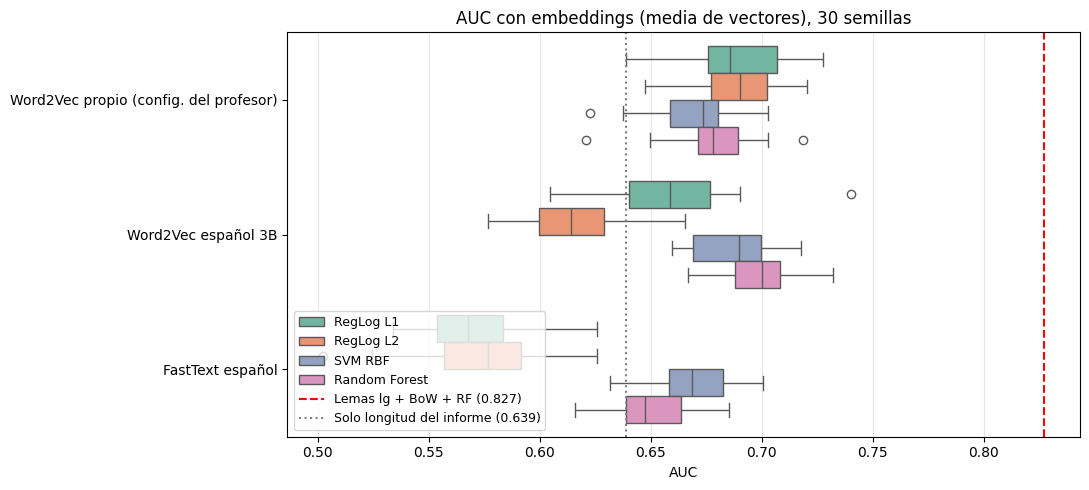

In [94]:
# Gráfica: todas las combinaciones frente a nuestro bosque BoW
filas = []
for (r, m), v in aucs_emb.items():
    for a in v:
        filas.append({'Representación': r, 'Modelo': m, 'AUC': a})
datos = pd.DataFrame(filas)
plt.figure(figsize=(11, 5))
sns.boxplot(data=datos, y='Representación', x='AUC', hue='Modelo', palette='Set2')
plt.axvline(auc_bow_rf.mean(), color='red', ls='--', label=f'Lemas lg + BoW + RF ({auc_bow_rf.mean():.3f})')
plt.axvline(0.639, color='grey', ls=':', label='Solo longitud del informe (0.639)')
plt.title('AUC con embeddings (media de vectores), 30 semillas')
plt.ylabel('')
plt.legend(loc='lower left', fontsize=9)
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

**Ningún embedding se acerca a la BoW con Random Forest, con ningún algoritmo.**

* El mejor es el Word2Vec preentrenado con Random Forest (**0.700**), que queda **0.127 por debajo** de nuestro modelo y pierde en las 30 semillas. El resto está entre 0.57 y 0.69.
* Nuestro Word2Vec, entrenado solo con 239 informes, va **casi igual que el preentrenado** con tres mil millones de palabras (0.689 frente a 0.700). Cuadra con lo que vimos en la cobertura: al preentrenado le faltan justo las palabras clínicas.
* A diferencia de la BoW, aquí el bosque no da un salto. Solo mejora un poco al preentrenado; con nuestro Word2Vec, los lineales van incluso algo mejor que el bosque.
* **FastText**, que según el texto del profesor debería ir mejor en textos clínicos por las subpalabras, es el peor de los tres con los modelos lineales (0.57) y no pasa de 0.669 con la SVM.

Así que, con los cuatro algoritmos del 8.1, tampoco parece cuestión de algoritmo: con cualquiera de ellos la media de embeddings se queda a más de una décima de la BoW. Antes de cerrarlo nos faltan dos cosas que sí probamos con la BoW: la red neuronal y ajustar los hiperparámetros.

#### ¿Y con una red neuronal?

Arriba hemos usado los cuatro algoritmos que mejor iban en el 8.1, pero el enunciado pide probar
también las redes neuronales con las distintas representaciones. Además, aquí hay un motivo para
pensar que podrían ir mejor que con la BoW: una red neuronal está pensada para entradas densas y
continuas como un embedding, no para cientos de columnas casi todas a cero. Así que probamos la red
del 8.1 (una capa oculta de 100 neuronas, valores por defecto) con los tres embeddings.

Naive Bayes no lo probamos: el `MultinomialNB` del 8.1 trabaja con conteos (valores positivos), y los
embeddings tienen valores negativos. Tampoco la SVM lineal, porque ya tenemos dos modelos lineales (L1 y L2).

In [95]:
# La red neuronal con los tres embeddings, con la misma configuración por defecto que en el 8.1
# (una capa oculta de 100 neuronas) y StandardScaler delante, igual que los lineales y la SVM.
def crear_mlp():
    return make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(100,), max_iter=1000, random_state=42))

guardado = cargar('10_3_red_neuronal')
if guardado is not None:
    mlp_emb, aucs_emb = guardado
else:
    mlp_emb = {}
    print("Evaluando el Word2Vec propio (config. del profesor) ...")
    res = auc_por_folds(tokens_min, w2v_propio, {}, {'Red neuronal (MLP)': crear_mlp})
    mlp_emb[('Word2Vec propio (config. del profesor)', 'Red neuronal (MLP)')] = res['Red neuronal (MLP)']
    for nombre_repr, X_repr in [('Word2Vec español 3B', X_embeddings_w2v), ('FastText español', X_embeddings_fasttext)]:
        print(f"Evaluando {nombre_repr} ...")
        res = auc_por_folds(list(X_repr), fija, {}, {'Red neuronal (MLP)': crear_mlp})
        mlp_emb[(nombre_repr, 'Red neuronal (MLP)')] = res['Red neuronal (MLP)']
    aucs_emb.update(mlp_emb)
    guardar('10_3_red_neuronal', (mlp_emb, aucs_emb))
display(tabla_vs_bow(mlp_emb))

# ¿Mejora a lo mejor que teníamos con cada embedding en el 10.3?
for nombre_repr in ['Word2Vec propio (config. del profesor)', 'Word2Vec español 3B', 'FastText español']:
    otros = {m: aucs_emb[(nombre_repr, m)] for m in clasificadores_emb}
    mejor = max(otros, key=lambda m: otros[m].mean())
    mlp = mlp_emb[(nombre_repr, 'Red neuronal (MLP)')]
    print(f"{nombre_repr}: red neuronal {mlp.mean():.3f} frente a {mejor} {otros[mejor].mean():.3f} "
          f"(gana en {(mlp > otros[mejor]).sum()} de 30, p = {formato_p(stats.wilcoxon(mlp, otros[mejor]).pvalue)})")


Representación,Modelo,AUC (30 semillas),Dif. vs BoW + RF,Gana a BoW + RF,p-valor (Wilcoxon)
Word2Vec propio (config. del profesor),Red neuronal (MLP),0.648 ± 0.024,-0.179,0 de 30,< 0.0001
FastText español,Red neuronal (MLP),0.612 ± 0.024,-0.216,0 de 30,< 0.0001
Word2Vec español 3B,Red neuronal (MLP),0.607 ± 0.018,-0.220,0 de 30,< 0.0001


Word2Vec propio (config. del profesor): red neuronal 0.648 frente a RegLog L1 0.689 (gana en 2 de 30, p = < 0.0001)
Word2Vec español 3B: red neuronal 0.607 frente a Random Forest 0.700 (gana en 0 de 30, p = < 0.0001)
FastText español: red neuronal 0.612 frente a SVM RBF 0.669 (gana en 0 de 30, p = < 0.0001)


**Con los valores por defecto, la red neuronal es el peor algoritmo con los tres embeddings**:
0.648 con nuestro Word2Vec, 0.607 con el preentrenado y 0.612 con FastText, por debajo del mejor
algoritmo de cada embedding en casi todas las semillas. Pero en el 8.2 ya nos pasó que la red sin
ajustar parecía mucho peor de lo que es (con la BoW subió más de una décima al ajustarla). Y hay algo
más: **ningún modelo de esta sección está ajustado**, mientras que el bosque de la BoW con el que lo
comparamos sí lo comprobamos en el 8.2. Así que, antes de concluir nada, toca ajustar.

#### ¿Y si ajustamos los hiperparámetros?

La pega es justa: si los embeddings los dejamos con los valores por defecto y la BoW la hemos mirado
con lupa, la comparación no está limpia. Hacemos la misma validación cruzada anidada que en el 8.2,
con los cinco algoritmos (L1, L2, SVM RBF, Random Forest y red neuronal). Las rejillas son las del
8.2, ya ampliadas hacia donde allí se quedaban en el borde.

La hacemos solo con el **Word2Vec en español**, y no con todos los embeddings, por dos motivos:

* Sus vectores ya están calculados, así que dentro de cada fold no hay que entrenar nada. Con nuestro
  Word2Vec o con el Doc2Vec habría que entrenar el embedding dentro de cada fold externo y ajustar el
  clasificador encima, y la celda pasaría de tardar un rato a tardar horas.
* Es el embedding donde más cambia el resultado según el algoritmo (de 0.61 a 0.70), así que es donde
  más margen tiene el ajuste. Si ajustando no se acerca a la BoW, no esperamos que los demás lo hagan.

Es una celda pesada (tarda bastante), pero la dejo porque sin ella la comparación con la BoW no sería justa.

In [96]:
# Validación cruzada anidada con el Word2Vec en español, igual que la del 8.2 con la BoW:
#  - bucle externo: 5 folds x 30 semillas, para medir
#  - bucle interno: GridSearchCV con 5 folds, solo con el train, para elegir los hiperparámetros
# Las rejillas son las del 8.2, ya ampliadas hacia donde allí se quedaban en el borde (C pequeñas en
# la L2, alpha grandes en la red neuronal), y para los lineales probamos también C muy pequeñas,
# porque aquí hay 400 columnas densas en vez de palabras sueltas.
# (Esta celda es pesada, tarda bastante: 5 algoritmos x 30 semillas x 5 folds x 5 folds internos x
# cada combinación de la rejilla. La dejamos porque sin ella la comparación con la BoW no es justa:
# el bosque de la BoW ya sabemos que no mejora al ajustarlo (8.2), pero los embeddings no los hemos ajustado.)
rejillas_emb = {
    'RegLog L1':          (LogisticRegression(penalty='l1', solver='liblinear', max_iter=1000, random_state=42),
                           {'C': [0.001, 0.01, 0.03, 0.1, 0.3, 1, 10]}),
    'RegLog L2':          (LogisticRegression(penalty='l2', solver='liblinear', max_iter=1000, random_state=42),
                           {'C': [0.0001, 0.001, 0.01, 0.1, 1, 10]}),
    'SVM RBF':            (SVC(kernel='rbf', random_state=42),
                           {'C': [0.1, 1, 10, 100], 'gamma': ['scale', 0.0001, 0.001, 0.01]}),
    'Random Forest':      (RandomForestClassifier(n_estimators=500, random_state=42),
                           {'max_features': ['sqrt', 0.1, 0.3], 'min_samples_leaf': [1, 3, 5]}),
    'Red neuronal (MLP)': (MLPClassifier(max_iter=1000, random_state=42),
                           {'hidden_layer_sizes': [(20,), (100,)], 'alpha': [0.0001, 0.01, 1, 10, 30, 100]}),
}

guardado = cargar('10_3_anidada_emb')
if guardado is not None:
    anidada_emb, elegidos_emb = guardado
else:
    filas, elegidos_emb = [], []
    for nombre, (modelo, rejilla) in rejillas_emb.items():
        print(f"CV anidada con el Word2Vec en español: {nombre} ...")
        paso = type(modelo).__name__.lower()          # nombre que le da make_pipeline al modelo
        rejilla_pipe = {f'{paso}__{k}': v for k, v in rejilla.items()}
        if nombre == 'Random Forest':
            pipe = make_pipeline(modelo)              # al bosque le da igual la escala
        else:
            pipe = make_pipeline(StandardScaler(), modelo)
        for semilla in semillas:
            externa = StratifiedKFold(n_splits=5, shuffle=True, random_state=semilla)
            interna = StratifiedKFold(n_splits=5, shuffle=True, random_state=semilla + 100)
            busqueda = GridSearchCV(pipe, rejilla_pipe, cv=interna, scoring='roc_auc', n_jobs=-1)
            r = cross_validate(busqueda, X_embeddings_w2v, y, cv=externa, return_estimator=True, scoring='roc_auc')
            filas.append({'Modelo': nombre, 'Semilla': semilla, 'AUC': r['test_score'].mean()})
            elegidos_emb += [{'Modelo': nombre, **{k.split('__')[1]: str(v) for k, v in m.best_params_.items()}}
                             for m in r['estimator']]
    anidada_emb = pd.DataFrame(filas)
    elegidos_emb = pd.DataFrame(elegidos_emb)
    guardar('10_3_anidada_emb', (anidada_emb, elegidos_emb))

# Ajustado contra por defecto (10.3 y la red de arriba), en las mismas particiones externas,
# y contra nuestro modelo final (BoW + Random Forest)
filas = []
for nombre in rejillas_emb:
    aj = anidada_emb.query("Modelo == @nombre").sort_values('Semilla')['AUC'].values
    de = aucs_emb[('Word2Vec español 3B', nombre)]
    aucs_emb[('Word2Vec español 3B (ajustado)', nombre)] = aj
    filas.append({'Modelo': nombre,
                  'AUC por defecto': f"{de.mean():.3f}",
                  'AUC ajustado (CV anidada)': f"{aj.mean():.3f} ± {aj.std(ddof=1):.3f}",
                  'Mejora al ajustar': f"{(aj - de).mean():+.3f}",
                  'p-valor (Wilcoxon)': formato_p(stats.wilcoxon(aj, de).pvalue),
                  'Dif. vs BoW + RF': f"{(aj - auc_bow_rf).mean():+.3f}",
                  'Gana a BoW + RF': f"{(aj > auc_bow_rf).sum()} de 30"})
display(pd.DataFrame(filas).style.hide(axis='index'))

# Qué hiperparámetros elige el bucle interno en los 150 folds externos (para ver si alguno se queda en el borde)
for nombre in rejillas_emb:
    sel = elegidos_emb[elegidos_emb['Modelo'] == nombre].drop(columns='Modelo').dropna(axis=1)
    print(f"\n{nombre}: combinaciones más elegidas en los 150 folds externos")
    print(sel.value_counts().head(4).to_string())


Modelo,AUC por defecto,AUC ajustado (CV anidada),Mejora al ajustar,p-valor (Wilcoxon),Dif. vs BoW + RF,Gana a BoW + RF
RegLog L1,0.658,0.660 ± 0.027,+0.001,0.5028,-0.168,0 de 30
RegLog L2,0.615,0.617 ± 0.022,+0.002,0.7000,-0.211,0 de 30
SVM RBF,0.686,0.675 ± 0.027,-0.012,0.0016,-0.153,0 de 30
Random Forest,0.700,0.702 ± 0.016,+0.002,0.4280,-0.125,0 de 30
Red neuronal (MLP),0.607,0.661 ± 0.024,+0.053,< 0.0001,-0.167,0 de 30



RegLog L1: combinaciones más elegidas en los 150 folds externos
C  
0.3    92
1      24
10     18
0.1    16

RegLog L2: combinaciones más elegidas en los 150 folds externos
C     
0.001     42
0.01      42
0.1       25
0.0001    20

SVM RBF: combinaciones más elegidas en los 150 folds externos
C    gamma
1    0.001    47
100  0.001    32
10   scale    26
     0.001    19

Random Forest: combinaciones más elegidas en los 150 folds externos
max_features  min_samples_leaf
0.3           5                   25
              3                   24
sqrt          1                   21
0.1           1                   17

Red neuronal (MLP): combinaciones más elegidas en los 150 folds externos
alpha   hidden_layer_sizes
30      (20,)                 64
10      (20,)                 26
0.0001  (20,)                 21
0.01    (20,)                 12


**Ajustar casi no cambia nada, salvo en la red neuronal:**

* La L1, la L2 y el bosque se quedan igual (diferencias de 1-2 milésimas, p > 0.4). Sus valores por
  defecto ya estaban bien, como le pasó al bosque de la BoW en el 8.2.
* La SVM RBF incluso baja un poco (0.686 → 0.675, p = 0.002). El bucle interno elige combinaciones
  muy distintas en cada fold (por ejemplo `C = 1` y `C = 100` con la misma `gamma`), así que con tan
  pocos pacientes elige en parte por ruido, igual que nos pasó con la `C` de la logística en el 7.3.
* La red neuronal es la única que mejora de verdad (+0.053, de 0.607 a 0.661), igual que en el 8.2.
  Elige casi siempre una regularización fuerte (`alpha = 30`) y una red pequeña.
* Aun así, **lo mejor con el embedding ajustado es el Random Forest (0.702), 0.125 por debajo de
  nuestro modelo final**, y ninguno gana a la BoW en ninguna semilla.

Mirando qué valores elige cada uno, la L2 elige a veces la `C` más pequeña (20 de 150 folds), pero lo
que más elige está en medio (0.001 y 0.01), así que no hace falta ampliarla. La red neuronal, en cambio,
se queda casi siempre en la capa oculta más pequeña de la rejilla (20 neuronas), que es el borde. Como
hicimos en el 8.2, ampliamos la rejilla hacia ese lado antes de dar el resultado por bueno.

In [97]:
# La red neuronal elige casi siempre la capa oculta más pequeña de la rejilla (20 neuronas), que está
# en el BORDE. Igual que en el 8.2, ampliamos la rejilla hacia ese lado (redes más pequeñas todavía)
# y repetimos la CV anidada solo para la red.
rejilla_mlp = {'mlpclassifier__hidden_layer_sizes': [(5,), (10,), (20,)],
               'mlpclassifier__alpha': [1, 10, 30, 100]}
guardado = cargar('10_3_mlp_ampliada')
if guardado is not None:
    mlp_ampliada, elegidos_mlp = guardado
else:
    filas, elegidos_mlp = [], []
    for semilla in semillas:
        externa = StratifiedKFold(n_splits=5, shuffle=True, random_state=semilla)
        interna = StratifiedKFold(n_splits=5, shuffle=True, random_state=semilla + 100)
        pipe = make_pipeline(StandardScaler(), MLPClassifier(max_iter=1000, random_state=42))
        busqueda = GridSearchCV(pipe, rejilla_mlp, cv=interna, scoring='roc_auc', n_jobs=-1)
        r = cross_validate(busqueda, X_embeddings_w2v, y, cv=externa, return_estimator=True, scoring='roc_auc')
        filas.append({'Semilla': semilla, 'AUC': r['test_score'].mean()})
        elegidos_mlp += [{k.split('__')[1]: str(v) for k, v in m.best_params_.items()} for m in r['estimator']]
    mlp_ampliada = pd.DataFrame(filas).sort_values('Semilla')['AUC'].values
    guardar('10_3_mlp_ampliada', (mlp_ampliada, elegidos_mlp))
antes = aucs_emb[('Word2Vec español 3B (ajustado)', 'Red neuronal (MLP)')]
rf_ajustado = aucs_emb[('Word2Vec español 3B (ajustado)', 'Random Forest')]
print(f"Red neuronal, rejilla original: AUC = {antes.mean():.3f}")
print(f"Red neuronal, rejilla ampliada: AUC = {mlp_ampliada.mean():.3f} ± {mlp_ampliada.std(ddof=1):.3f} "
      f"(diferencia {(mlp_ampliada - antes).mean():+.3f}, p = {formato_p(stats.wilcoxon(mlp_ampliada, antes).pvalue)})")
print(f"Contra el Random Forest ajustado ({rf_ajustado.mean():.3f}): gana en {(mlp_ampliada > rf_ajustado).sum()} de 30")
print("\nValores elegidos en los 150 folds externos:")
print(pd.DataFrame(elegidos_mlp).value_counts().head(5).to_string())


Red neuronal, rejilla original: AUC = 0.661
Red neuronal, rejilla ampliada: AUC = 0.657 ± 0.025 (diferencia -0.003, p = 0.1791)
Contra el Random Forest ajustado (0.702): gana en 0 de 30

Valores elegidos en los 150 folds externos:
alpha  hidden_layer_sizes
30     (20,)                 63
10     (20,)                 29
1      (20,)                 26
30     (10,)                 11
100    (5,)                   4


Con la rejilla ampliada la red neuronal sigue eligiendo 20 neuronas en la mayoría de los folds (las
redes de 5 y 10 neuronas casi nunca las coge), así que ese valor ya no está en el borde, y el AUC no
cambia (0.657 frente a 0.661, p = 0.18). El ajuste ya estaba bien hecho.

**Conclusión del 10.3**: no es culpa del algoritmo ni de no haberlo ajustado. Con cinco algoritmos,
con y sin ajustar, lo mejor que sacamos con el Word2Vec en español es 0.702, a más de una décima de la
BoW con Random Forest. La red neuronal, que en teoría era la que mejor podía aprovechar los vectores
densos, es de las peores.

### 10.4 ¿Es culpa de la puntuación?

En clase el profesor comentó que para embeddings quitaría la puntuación y las mayúsculas, pero que a lo mejor el punto está cortando el contexto, y que había que hacer pruebas. Lo comprobamos de dos formas:

* **Dejando la puntuación como tokens** en vez de quitarla (el resto igual: sin stopwords y en minúsculas).
* **Entrenando nuestro Word2Vec frase a frase**, para que la ventana nunca salte de una oración a la siguiente. Esto solo tiene sentido para nuestro Word2Vec, porque los preentrenados ya vienen entrenados.

Lo hacemos con los tres embeddings, los cuatro clasificadores y las 30 semillas, porque con una sola partición no podríamos fiarnos de diferencias de una o dos centésimas.

In [98]:
# Dos versiones del texto: la de siempre (sin puntuación) y otra dejando la puntuación
# como tokens (el "." puede estar cortando el contexto). El resto igual: sin stopwords y en minúsculas.
variantes = {}
for sin_punt in [True, False]:
    docs = df_clasbin['PALABRAS']
    docs = docs.apply(remove_stopwords)
    if sin_punt:
        docs = docs.apply(remove_punctuation)
    docs = docs.apply(minusculas)
    nombre = 'minúsculas, sin stopwords, ' + ('sin' if sin_punt else 'con') + ' puntuación'
    variantes[nombre] = list(docs)
referencia = 'minúsculas, sin stopwords, sin puntuación'     # = PALABRAS_MIN, la que llevamos usando

# Cobertura del Word2Vec en español con cada versión (FastText siempre da vector)
filas = []
for nombre, docs in variantes.items():
    c = Counter()
    for doc in docs:
        c.update(doc)
    distintas = sum(1 for p in c if p in modelo_w2v_es)
    apariciones = sum(n for p, n in c.items() if p in modelo_w2v_es)
    filas.append({'Variante': nombre, 'Palabras distintas': len(c),
                  '% distintas con vector (W2V 3B)': f'{100*distintas/len(c):.1f}%',
                  '% apariciones con vector (W2V 3B)': f'{100*apariciones/sum(c.values()):.1f}%'})
display(pd.DataFrame(filas).style.hide(axis='index'))

Variante,Palabras distintas,% distintas con vector (W2V 3B),% apariciones con vector (W2V 3B)
"minúsculas, sin stopwords, sin puntuación",4718,68.7%,88.7%
"minúsculas, sin stopwords, con puntuación",5032,61.2%,64.1%


In [99]:
# Los tres embeddings x los cuatro clasificadores con cada versión, 30 semillas
# (tarda un rato: 2 versiones x 3 embeddings x 30 semillas x 5 folds)
guardado = cargar('10_4_prepro_emb')
if guardado is not None:
    prepro_emb = guardado
else:
    filas = []
    for nombre_var, docs in variantes.items():
        print(f"Evaluando: {nombre_var} ...")
        X_w2v_var = media_vectores(docs, modelo_w2v_es, 400)
        X_ft_var = np.array([np.mean([vec_ft_es[p] for p in d], axis=0) for d in docs])
        for nombre_repr, representar, entrada in [('Word2Vec español 3B', fija, list(X_w2v_var)),
                                                  ('FastText español', fija, list(X_ft_var)),
                                                  ('Word2Vec propio (config. del profesor)', w2v_propio, docs)]:
            res = auc_por_folds(entrada, representar, {}, clasificadores_emb)
            for nombre in res:
                filas.append({'Representación': nombre_repr, 'Modelo': nombre, 'Variante': nombre_var,
                              'AUC': res[nombre].mean(), 'aucs': res[nombre]})
    prepro_emb = pd.DataFrame(filas)
    guardar('10_4_prepro_emb', prepro_emb)

In [100]:
# La otra forma de que el "." corte el contexto: entrenar nuestro Word2Vec FRASE A FRASE
# (cada oración es una "frase" para Word2Vec, así la ventana nunca salta de una oración a
# la siguiente). El vector del informe sigue siendo la media de todas sus palabras.
# (Solo tiene sentido para el Word2Vec propio: los preentrenados ya vienen entrenados.)
def w2v_propio_frases(docs_train, docs_test, vector_size=50, window=5, min_count=2, sg=0, epochs=50):
    frases = []
    for doc in docs_train:
        for frase in doc:
            if len(frase) > 0:
                frases.append(frase)
    w2v = Word2Vec(sentences=frases, vector_size=vector_size, window=window, min_count=min_count,
                   sg=sg, epochs=epochs, seed=60, workers=1)
    palabras_train = [[p for frase in doc for p in frase] for doc in docs_train]
    palabras_test = [[p for frase in doc for p in frase] for doc in docs_test]
    return media_vectores(palabras_train, w2v.wv, vector_size), media_vectores(palabras_test, w2v.wv, vector_size)

# Cada informe como lista de oraciones, y cada oración limpia igual que PALABRAS_MIN
oraciones_min = []
for texto in df_clasbin['TEXTO']:
    doc = []
    for oracion in nltk.sent_tokenize(texto, language='spanish'):
        doc.append(minusculas(remove_punctuation(remove_stopwords(nltk.word_tokenize(oracion, language='spanish')))))
    oraciones_min.append(doc)

guardado = cargar('10_4_frase_a_frase')
if guardado is not None:
    prepro_emb = guardado
else:
    res = auc_por_folds(oraciones_min, w2v_propio_frases, {}, clasificadores_emb)
    for nombre in res:
        prepro_emb.loc[len(prepro_emb)] = {'Representación': 'Word2Vec propio (config. del profesor)', 'Modelo': nombre,
                                           'Variante': 'minúsculas, sin stopwords, entrenado frase a frase',
                                           'AUC': res[nombre].mean(), 'aucs': res[nombre]}
    guardar('10_4_frase_a_frase', prepro_emb)

tabla = prepro_emb.pivot_table(index='Variante', columns=['Representación', 'Modelo'], values='AUC')
tabla = tabla.loc[list(variantes) + ['minúsculas, sin stopwords, entrenado frase a frase']]
display(tabla.style.format('{:.3f}', na_rep='—').highlight_max(axis=0, color='#c6efce'))

# Cada variante contra la de siempre, con el mejor clasificador de cada embedding
filas = []
for nombre_repr in prepro_emb['Representación'].unique():
    sel = prepro_emb[prepro_emb['Representación'] == nombre_repr]
    mejor_clf = sel[sel['Variante'] == referencia].sort_values('AUC').iloc[-1]['Modelo']
    sel = sel[sel['Modelo'] == mejor_clf]
    base = sel[sel['Variante'] == referencia]['aucs'].iloc[0]
    for _, f in sel.sort_values('AUC', ascending=False).iterrows():
        if f['Variante'] == referencia:
            continue
        if (f['aucs'] == base).all():
            p = 'idénticas'
        else:
            p = formato_p(stats.wilcoxon(f['aucs'], base).pvalue)
        filas.append({'Representación': nombre_repr, 'Modelo': mejor_clf, 'Variante': f['Variante'],
                      'AUC': f"{f['AUC']:.3f}", 'Dif. vs la de siempre': f"{(f['aucs'] - base).mean():+.3f}",
                      'Gana': f"{(f['aucs'] > base).sum()} de 30", 'p-valor (Wilcoxon)': p})
display(pd.DataFrame(filas).style.hide(axis='index'))

Representación,Modelo,Variante,AUC,Dif. vs la de siempre,Gana,p-valor (Wilcoxon)
Word2Vec español 3B,Random Forest,"minúsculas, sin stopwords, con puntuación",0.700,-0.001,14 de 30,0.6702
FastText español,SVM RBF,"minúsculas, sin stopwords, con puntuación",0.622,-0.047,0 de 30,< 0.0001
Word2Vec propio (config. del profesor),RegLog L1,"minúsculas, sin stopwords, entrenado frase a frase",0.693,+0.004,22 de 30,0.0137
Word2Vec propio (config. del profesor),RegLog L1,"minúsculas, sin stopwords, con puntuación",0.657,-0.032,2 de 30,< 0.0001


Lo que vemos:

* **Dejar la puntuación empeora o no cambia nada.** A nuestro Word2Vec le quita 3 centésimas (0.657 frente a 0.689 con la L1) y a FastText casi 5 (0.622 frente a 0.669 con la SVM), porque los signos acaban teniendo vector y "ensucian" la media. Al Word2Vec en español le da igual (0.700 en los dos casos), porque los signos no están en su vocabulario y se los salta, aunque por eso mismo su cobertura baja del 89% al 64% de las apariciones.
* **Entrenar frase a frase** le da a nuestro Word2Vec **+0.004** (0.693 frente a 0.689, gana en 22 de 30 semillas). El efecto que sospechaba el profesor existe, pero es de 4 milésimas.

Así que el profesor tenía razón en quitar la puntuación, y me quedo con el preprocesado de partida. Una diferencia de milésimas no cambia nada frente a una diferencia de más de 0.12 con la BoW, así que el problema tampoco es la puntuación.

### 10.5 ¿Es culpa de la media?

En clase el profesor insistió en que el problema de fondo es que los embeddings dan **un vector por palabra y no por documento**, y la media es la forma más simple de pasar de uno a otro. Pero la media tiene un problema claro en nuestro caso: un informe tiene cientos de palabras y las que nos interesan ("sincrónico", "segunda neoplasia", "metacrónico"...) son muy pocas, así que en la media quedan diluidas entre todas las demás. La BoW, en cambio, deja a cada palabra en su propia columna y el bosque puede ir a buscarla.

Probamos dos alternativas:

1. **Media ponderada por TF-IDF**: que las palabras que salen en casi todos los informes pesen poco y las raras pesen más.
2. **Doc2Vec**: un modelo que, en vez de promediar, aprende directamente un vector para cada documento.

In [101]:
# Alternativa 1: media PONDERADA por el IDF de cada palabra. Las palabras que salen en casi
# todos los informes pesan poco y las raras pesan más. Como cada palabra cuenta tantas veces
# como aparece, en realidad es una media ponderada por TF-IDF. El IDF se calcula SOLO con el
# train (la fórmula es la misma que usa TfidfVectorizer).
def media_tfidf(docs_train, docs_test, vectores=None, dim=50):
    if vectores is None:     # Word2Vec propio: lo entrenamos con el train
        w2v = Word2Vec(sentences=docs_train, vector_size=50, window=5, min_count=2, sg=0, epochs=50, seed=60, workers=1)
        vectores = w2v.wv
    n = len(docs_train)
    df_palabra = Counter()
    for doc in docs_train:
        df_palabra.update(set(doc))
    idf = {}
    for palabra, c in df_palabra.items():
        idf[palabra] = np.log((1 + n) / (1 + c)) + 1
    idf_nueva = np.log(1 + n) + 1          # palabra que no salía en el train

    def ponderar(docs):
        X = np.zeros((len(docs), dim))
        for i, doc in enumerate(docs):
            palabras = [p for p in doc if p in vectores]
            if len(palabras) > 0:
                pesos = [idf.get(p, idf_nueva) for p in palabras]
                X[i] = np.average([vectores[p] for p in palabras], axis=0, weights=pesos)
        return X
    return ponderar(docs_train), ponderar(docs_test)

# (vec_ft_es, el diccionario con los vectores FastText de nuestras palabras, ya lo creamos en el 10.1)

guardado = cargar('10_5_media_tfidf')
if guardado is not None:
    filas, aucs_emb = guardado
else:
    filas = []
    for nombre_repr, opciones in [('Word2Vec propio (config. del profesor)', {}),
                                  ('Word2Vec español 3B', {'vectores': modelo_w2v_es, 'dim': 400}),
                                  ('FastText español', {'vectores': vec_ft_es, 'dim': 300})]:
        print(f"Media ponderada por TF-IDF: {nombre_repr} ...")
        res = auc_por_folds(tokens_min, media_tfidf, opciones, clasificadores_emb)
        for nombre in res:
            media = aucs_emb[(nombre_repr, nombre)]          # la media normal, la del 10.3
            pond = res[nombre]
            aucs_emb[(nombre_repr + ', media TF-IDF', nombre)] = pond
            filas.append({'Embedding': nombre_repr, 'Modelo': nombre, 'AUC media': f"{media.mean():.3f}",
                          'AUC media TF-IDF': f"{pond.mean():.3f} ± {pond.std(ddof=1):.3f}",
                          'Diferencia': f"{(pond - media).mean():+.3f}", 'Gana la ponderada': f"{(pond > media).sum()} de 30",
                          'p-valor (Wilcoxon)': formato_p(stats.wilcoxon(pond, media).pvalue)})
    guardar('10_5_media_tfidf', (filas, aucs_emb))
display(pd.DataFrame(filas).style.hide(axis='index'))

Embedding,Modelo,AUC media,AUC media TF-IDF,Diferencia,Gana la ponderada,p-valor (Wilcoxon)
Word2Vec propio (config. del profesor),RegLog L1,0.689,0.680 ± 0.021,-0.009,3 de 30,< 0.0001
Word2Vec propio (config. del profesor),RegLog L2,0.689,0.680 ± 0.019,-0.009,2 de 30,< 0.0001
Word2Vec propio (config. del profesor),SVM RBF,0.670,0.662 ± 0.019,-0.008,5 de 30,< 0.0001
Word2Vec propio (config. del profesor),Random Forest,0.679,0.670 ± 0.020,-0.008,9 de 30,0.0113
Word2Vec español 3B,RegLog L1,0.658,0.603 ± 0.024,-0.055,0 de 30,< 0.0001
Word2Vec español 3B,RegLog L2,0.615,0.575 ± 0.018,-0.039,0 de 30,< 0.0001
Word2Vec español 3B,SVM RBF,0.686,0.631 ± 0.018,-0.056,0 de 30,< 0.0001
Word2Vec español 3B,Random Forest,0.700,0.644 ± 0.021,-0.057,0 de 30,< 0.0001
FastText español,RegLog L1,0.573,0.560 ± 0.030,-0.013,7 de 30,0.0028
FastText español,RegLog L2,0.574,0.557 ± 0.030,-0.017,4 de 30,< 0.0001


**La media ponderada va peor que la media normal en todos los casos**: poco con nuestro Word2Vec (−0.008) y bastante con el preentrenado (unas 5 centésimas). Mi interpretación es que, al dar más peso a las palabras raras, el vector del informe pasa a depender sobre todo de palabras poco frecuentes, cuyo vector es menos fiable (o que ni siquiera tienen vector y se pierden), y en cambio se apagan palabras como "neoplasia" o "carcinoma", que salen en muchos informes pero importan. Me quedo con la media normal.

In [102]:
# Alternativa 2: Doc2Vec (gensim). En vez de promediar, aprende directamente un vector por
# documento. Se entrena con los informes de train y a los de test se les "infiere" su vector
# (a los de train también, para que todos estén en las mismas condiciones).
#   dm: 1 = PV-DM (parecido a CBOW) / 0 = PV-DBOW (parecido a Skip-gram)
# Usamos PV-DM con la misma configuración que el Word2Vec del profesor (50 dimensiones,
# 50 épocas, ventana 5, min_count=2), sin ajustarla, y lo probamos con la SVM y el Random
# Forest, que son los que mejor funcionaron con los embeddings preentrenados en el 10.3.
from gensim.models.doc2vec import Doc2Vec, TaggedDocument

def doc2vec(docs_train, docs_test, dm=1, vector_size=50, epochs=50):
    etiquetados = [TaggedDocument(doc, [i]) for i, doc in enumerate(docs_train)]
    d2v = Doc2Vec(etiquetados, dm=dm, vector_size=vector_size, window=5, min_count=2,
                  epochs=epochs, seed=60, workers=1)
    X_train = np.array([d2v.infer_vector(doc, epochs=epochs) for doc in docs_train])
    X_test = np.array([d2v.infer_vector(doc, epochs=epochs) for doc in docs_test])
    return X_train, X_test

opciones = {'dm': 1, 'vector_size': 50, 'epochs': 50}
guardado = cargar('10_5_doc2vec')
if guardado is not None:
    filas, aucs_emb = guardado
else:
    filas = []
    for nombre, crear in [('SVM RBF', crear_svm), ('Random Forest', crear_rf_final)]:
        v = auc_por_folds(tokens_min, doc2vec, opciones, {nombre: crear})[nombre]
        aucs_emb[('Doc2Vec', nombre)] = v
        filas.append({'Modelo': nombre, 'Hiperparámetros': f"dm={opciones['dm']}, vector_size={opciones['vector_size']}, epochs={opciones['epochs']}",
                      'AUC (30 semillas)': f"{v.mean():.3f} ± {v.std(ddof=1):.3f}",
                      'Dif. vs BoW + RF': f"{(v - auc_bow_rf).mean():+.3f}",
                      'p-valor vs BoW + RF': formato_p(stats.wilcoxon(v, auc_bow_rf).pvalue)})
    guardar('10_5_doc2vec', (filas, aucs_emb))
display(pd.DataFrame(filas).style.hide(axis='index'))

Modelo,Hiperparámetros,AUC (30 semillas),Dif. vs BoW + RF,p-valor vs BoW + RF
SVM RBF,"dm=1, vector_size=50, epochs=50",0.737 ± 0.020,-0.090,< 0.0001
Random Forest,"dm=1, vector_size=50, epochs=50",0.727 ± 0.019,-0.100,< 0.0001


**Doc2Vec es la mejor forma de representar el documento con embeddings que hemos probado, pero sigue lejos de la BoW.** Con la SVM saca **0.737** y con el bosque 0.727, por encima de todas las medias de vectores del 10.3 (la mejor era 0.700), pero **0.090 por debajo** de nuestro modelo final (p < 0.0001), y un poco por debajo incluso del baseline BoW con L1 (0.746).

No hemos ajustado sus hiperparámetros ni los de nuestro Word2Vec (tamaño del vector, ventana, épocas, CBOW o Skip-gram...), así que puede que se pueda sacar algo más. Pero viendo la distancia con la BoW, no esperamos que eso cambie la conclusión.

Un detalle a tener en cuenta: el vector que Doc2Vec infiere para cada informe tiene una parte aleatoria que depende de la sesión de Python, aunque fijemos la semilla. Así que, si se vuelve a ejecutar esta parte, los AUC del Doc2Vec pueden cambiar ligeramente.

### 10.6 ¿Y si juntamos BoW y embedding?

Quizá no hace falta elegir: la BoW sabe qué palabras concretas aparecen y el embedding aporta el "significado general" del informe, así que a lo mejor se complementan. Probamos a juntar las columnas de las dos representaciones (la BoW de lemas `lg` del modelo final y, a continuación, las del embedding) y pasárselas a nuestro Random Forest. Es barato, porque los embeddings preentrenados ya están calculados.

In [103]:
# ¿Y si no elegimos? BoW y embedding juntos: las columnas de la BoW (lemas lg, como en el
# modelo final) y a continuación las del embedding, todo al Random Forest.
# Cada informe es una pareja (texto lematizado, vector del embedding).
from scipy.sparse import hstack, csr_matrix

def bow_mas_embedding(docs_train, docs_test):
    vectorizador = crear_vectorizador_final()
    bow_train = vectorizador.fit_transform([d[0] for d in docs_train])   # vocabulario solo con el train
    bow_test = vectorizador.transform([d[0] for d in docs_test])
    emb_train = csr_matrix(np.array([d[1] for d in docs_train]))
    emb_test = csr_matrix(np.array([d[1] for d in docs_test]))
    return hstack([bow_train, emb_train]).tocsr(), hstack([bow_test, emb_test]).tocsr()

guardado = cargar('10_6_bow_mas_embedding')
if guardado is not None:
    filas, aucs_emb = guardado
else:
    filas = []
    for nombre_repr, X_repr in [('Word2Vec español 3B', X_embeddings_w2v), ('FastText español', X_embeddings_fasttext)]:
        print(f"Evaluando BoW + {nombre_repr} ...")
        parejas = list(zip(textos_final, X_repr))
        v = auc_por_folds(parejas, bow_mas_embedding, {}, {'Random Forest': crear_rf_final})['Random Forest']
        aucs_emb[('BoW + ' + nombre_repr, 'Random Forest')] = v
        filas.append({'Representación': 'BoW (lemas lg) + ' + nombre_repr, 'AUC (30 semillas)': f"{v.mean():.3f} ± {v.std(ddof=1):.3f}",
                      'Dif. vs BoW sola': f"{(v - auc_bow_rf).mean():+.3f}", 'Gana a BoW sola': f"{(v > auc_bow_rf).sum()} de 30",
                      'p-valor (Wilcoxon)': formato_p(stats.wilcoxon(v, auc_bow_rf).pvalue)})
    guardar('10_6_bow_mas_embedding', (filas, aucs_emb))
print(f"\nBoW sola + Random Forest: AUC = {auc_bow_rf.mean():.3f} ± {auc_bow_rf.std(ddof=1):.3f}")
display(pd.DataFrame(filas).style.hide(axis='index'))


BoW sola + Random Forest: AUC = 0.827 ± 0.011


Representación,AUC (30 semillas),Dif. vs BoW sola,Gana a BoW sola,p-valor (Wilcoxon)
BoW (lemas lg) + Word2Vec español 3B,0.736 ± 0.016,-0.091,0 de 30,< 0.0001
BoW (lemas lg) + FastText español,0.696 ± 0.017,-0.131,0 de 30,< 0.0001


**Juntarlas empeora mucho** (0.736 con el Word2Vec y 0.696 con FastText, frente a 0.827 con la BoW sola, y pierde en las 30 semillas). Creo que el motivo es cómo funciona el bosque: en cada división, cada árbol solo mira una muestra aleatoria de columnas (`max_features='sqrt'`, unas 30 de más de mil). Las columnas del embedding son numéricas y casi siempre algo informativas, así que tienden a ganar las divisiones frente a las palabras concretas, que son las que de verdad distinguen los informes. Así que añadir el embedding no aporta y además le quita sitio a las palabras.

### 10.7 Resumen

Juntamos en una gráfica el mejor resultado de cada representación que hemos probado, frente al baseline BoW y a nuestro modelo final.

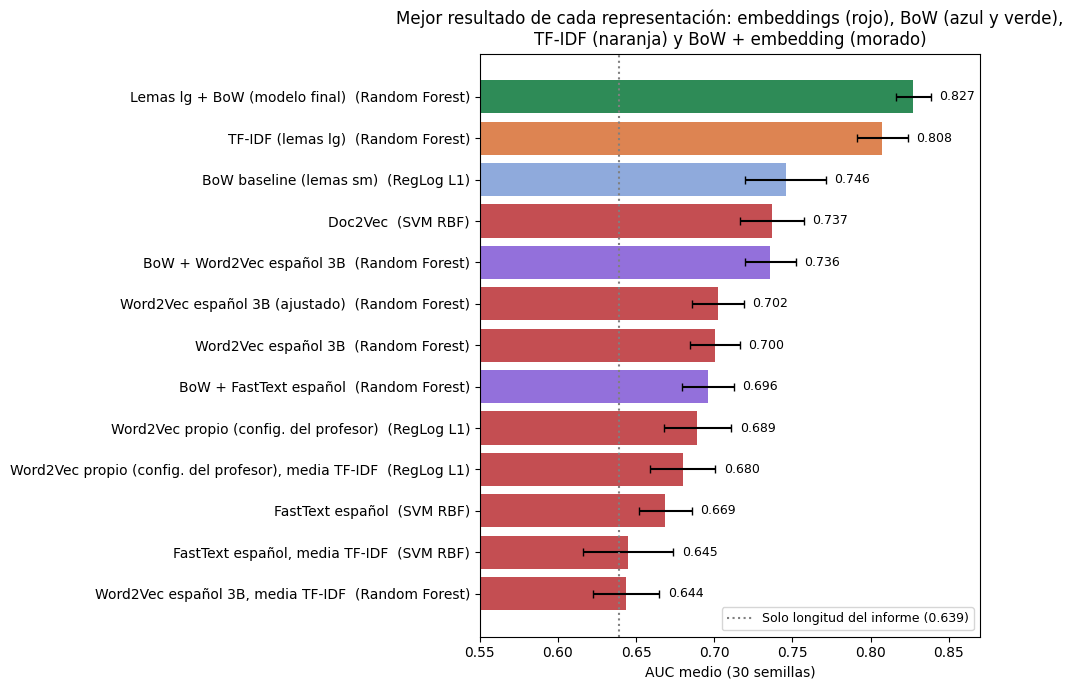

In [104]:
# Resumen: lo mejor de cada representación frente al baseline y a nuestro modelo final
mejores = {}
for (r, m), v in aucs_emb.items():
    if r not in mejores or v.mean() > mejores[r][1].mean():
        mejores[r] = (m, v)
mejores['BoW baseline (lemas sm)'] = ('RegLog L1', auc_por_semilla('Baseline (stopwords rev. + lemas)', 'L1')['AUC'].values)
mejores['Lemas lg + BoW (modelo final)'] = ('Random Forest', auc_bow_rf)
# TF-IDF (apartados 7.2 y 8.5): su mejor algoritmo, que también lo comparamos aquí
medias_tfidf = algoritmos_tfidf_30.groupby('Modelo')['AUC'].mean()
mejor_tfidf_alg = medias_tfidf.idxmax()
mejores['TF-IDF (lemas lg)'] = (mejor_tfidf_alg, algoritmos_tfidf_30.query("Modelo == @mejor_tfidf_alg").sort_values('Semilla')['AUC'].values)
filas = []
for r, (m, v) in mejores.items():
    filas.append({'Representación': r, 'Mejor modelo': m, 'AUC': v.mean(), 'std': v.std(ddof=1)})
resumen = pd.DataFrame(filas).sort_values('AUC')

colores = []
for r in resumen['Representación']:
    if r.startswith('Lemas lg'):
        colores.append('#2E8B57')
    elif r.startswith('TF-IDF'):
        colores.append('#DD8452')
    elif r.startswith('BoW +'):
        colores.append('#9370DB')
    elif r.startswith('BoW'):
        colores.append('#8FAADC')
    else:
        colores.append('#C44E52')
fig, ax = plt.subplots(figsize=(10, 7))
etiquetas = resumen['Representación'] + '  (' + resumen['Mejor modelo'] + ')'
barras = ax.barh(etiquetas, resumen['AUC'], xerr=resumen['std'], color=colores, capsize=3)
ax.bar_label(barras, labels=[f'{a:.3f}' for a in resumen['AUC']], padding=6, fontsize=9)
ax.axvline(0.639, color='grey', ls=':', label='Solo longitud del informe (0.639)')
ax.set_xlim(0.55, 0.87)
ax.set_xlabel('AUC medio (30 semillas)')
ax.set_title('Mejor resultado de cada representación: embeddings (rojo), BoW (azul y verde),\nTF-IDF (naranja) y BoW + embedding (morado)')
ax.legend(loc='lower right', fontsize=9)
plt.tight_layout()
plt.show()

### 10.8 Respuesta a la pregunta del profesor

**¿Incorporar contexto a la vectorización del documento mejora la predicción? En nuestro problema, no.** En la gráfica se ve: todo lo que hemos probado con embeddings (en rojo) queda por debajo de nuestro modelo BoW (en verde), y también de la BoW con el preprocesado del baseline (en azul, con L1, 0.746). Ni con otros algoritmos (tampoco con una red neuronal ni ajustando los hiperparámetros con CV anidada), ni dejando la puntuación, ni entrenando frase a frase, ni ponderando la media, ni con Doc2Vec, ni juntándolo con la BoW (en morado). En el escenario que pedía el profesor (media del Word2Vec en español con regresión logística) sacamos 0.692 con L1 frente a 0.746 de la BoW con el preprocesado del baseline y L1, perdiendo en las 30 semillas. Y lo mejor que hemos conseguido con embeddings, Doc2Vec con la SVM (**0.737**), queda **0.090 por debajo** del modelo final (0.827).

**¿Y frente a TF-IDF?** El enunciado pide compararlos también con TF-IDF, y la gráfica deja un orden
claro: **BoW > TF-IDF > embeddings**. Con el mismo algoritmo (Random Forest), la BoW saca 0.827, TF-IDF
0.808 (8.5) y el mejor embedding, el Doc2Vec, 0.727 (con las medias de vectores no pasamos de 0.702,
ni ajustando). Y en el escenario del
baseline, con L1 y `C = 1`, TF-IDF y la media del Word2Vec van casi empatados (0.690 y 0.692), los dos
por debajo de la BoW. O sea que todo lo que se aleja de "contar cuántas veces sale cada palabra" pierde,
y cuanto más se aleja, más pierde: TF-IDF solo cambia el peso de cada palabra, pero el embedding las
mezcla todas en un solo vector.

¿Por qué? Por lo que hemos ido viendo en la sección:

1. **Lo que distingue a un paciente con varias neoplasias son palabras concretas** ("sincrónico", "segunda neoplasia", nombres de tumores en distintos órganos...). La BoW deja cada una en su columna y el bosque las encuentra. La media de embeddings las mezcla con cientos de palabras más.
2. **Los modelos preentrenados son de español general**: les faltan justo las palabras clínicas (her2, ki67, estadios TNM, tratamientos) y las que tienen las entienden con su sentido general.
3. **Nuestro corpus es muy pequeño** (239 informes) para aprender buenos vectores desde cero.

**¿Cuándo tendría sentido usar un modelo preentrenado?** El enunciado también pide discutirlo, y con
lo que hemos visto lo resumiría así. Un preentrenado aporta algo que nosotros no tenemos: haber visto
miles de millones de palabras. Eso compensa sobre todo cuando:

* el corpus propio es **pequeño**, demasiado para aprender buenos vectores desde cero;
* el **vocabulario** de la tarea está en el preentrenado y con el **mismo sentido**, es decir, el texto
  con el que se entrenó se parece al nuestro;
* lo que importa para clasificar es el **significado general** del texto (por ejemplo, si una opinión es
  positiva o negativa), y no que aparezcan unas pocas palabras concretas.

En nuestro problema se cumple la primera condición (nuestro Word2Vec cambia de vecinos con solo cambiar
la semilla), pero no las otras dos: al Word2Vec y a FastText en español les faltan justo los términos
clínicos (her2, ki67, estadios TNM, tratamientos), "sincrónico" lo entienden con su sentido general, y lo
que separa las clases son palabras concretas. Por eso nuestro Word2Vec entrenado con 239 informes va
casi igual que el preentrenado con tres mil millones de palabras. Para que un preentrenado ayudase aquí
tendría que estar entrenado con texto clínico en español.

Así que, respondiendo a "¿me sirve la BoW o necesito algo más complejo?": **para este problema me quedo con la BoW**. Además de ir mejor, es más rápida y se puede interpretar, porque podemos ver qué palabras usa el modelo. Mi modelo final no cambia: **lemas `lg` + BoW + Random Forest (AUC 0.827)**.

Lo que sí dejo apuntado es que esto no significa que el contexto no sirva nunca. Lo que no sirve aquí es el contexto **genérico y promediado**. Un modelo que sí entiende contexto y está entrenado con texto clínico en español (por ejemplo, un transformer clínico de Hugging Face) podría cambiar el resultado. Ese sería el siguiente paso si quisiéramos seguir subiendo el AUC.

## 11\. Conclusiones

### Del baseline al modelo final

Esta es la respuesta corta a "¿cuál es nuestro mejor modelo?". Todas las filas están medidas igual (30 semillas, CV estratificada de 5 folds, vectorizador dentro del Pipeline), así que se pueden comparar entre sí:

| Paso | Qué cambiamos | AUC (30 semillas) | Mejora | ¿Nos lo quedamos? |
|---|---|---|---|---|
| **Baseline** | Lemas `sm` + BoW + **RegLog L2** | **0.733** | - | Punto de partida |
| 5.1 | L2 → L1 | 0.746 | +0.013 | Sí |
| 6.2 | Lemas `sm` → lemas `lg` | 0.778 | +0.032 | Sí |
| 6.2 / 6.4 | Stemming, mayúsculas, sin stopwords, sin quitar puntuación... | 0.75-0.77 | negativa | No |
| 7.1 / 7.2 | Bigramas/trigramas, TF-IDF | 0.775 / 0.734 | negativa | No |
| 7.2 | TF-IDF sin quitar stopwords | 0.721 | negativa | No |
| 7.3 | Ajustar la `C` con CV anidada | 0.765 | negativa | No |
| 8.1 | RegLog L1 → **Random Forest** | **0.827** | +0.049 | Sí |
| 8.2 / 8.3 | Otros algoritmos ajustados (red neuronal, SVM, Gradient Boosting, ensemble) | 0.72-0.82 | negativa | No |
| 8.2 / 8.4 | Ajustar el bosque, 1000 árboles | 0.827 / 0.829 | ~0 | No hace falta |
| 8.5 | Mejor preprocesado de la búsqueda exhaustiva (todas las stopwords de NLTK + stemming, `min_df=10`) | 0.834 | +0.007 | No (interpretabilidad) |
| 8.5 | BoW binaria | 0.782 | negativa | No |
| 8.5 | TF-IDF con el Random Forest (y con el resto de algoritmos) | 0.808 | negativa | No |
| 10 | BoW → embeddings (mejor: Doc2Vec + SVM) | 0.737 | negativa | No |
| 10.3 | Embeddings con red neuronal y con CV anidada (mejor: Word2Vec en español + RF ajustado) | 0.702 | negativa | No |

> **Nuestro mejor modelo**: stopwords revisadas + quitar puntuación + minúsculas + lematización con `es_core_news_lg` + BoW de palabras sueltas (`min_df=5`, `max_df=0.8`) + **Random Forest de 500 árboles**. AUC = **0.827 ± 0.011** (F1 = 0.760, recall = 0.730, precision = 0.800 con umbral 0.5), es decir, **+0.094 de AUC sobre el baseline**. Para usarlo en la clínica, con un umbral de ~0.38 detecta el 91% de los pacientes con múltiples neoplasias.

(Con la partición de `random_state=42` los números salen más bajos, porque es de las más desfavorables: por ejemplo el baseline da 0.70 y el bosque 0.815. Por eso las decisiones están tomadas siempre con las 30 semillas.)

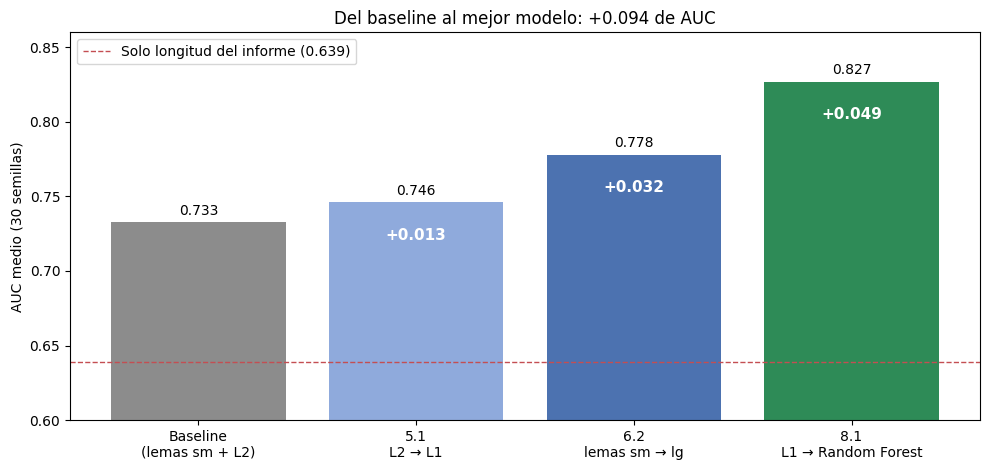

In [105]:
# Gráfica: el camino desde el baseline hasta el mejor modelo (valores de la tabla de arriba, 30 semillas)
pasos = ['Baseline\n(lemas sm + L2)', '5.1\nL2 → L1', '6.2\nlemas sm → lg', '8.1\nL1 → Random Forest']
auc_pasos = [0.733, 0.746, 0.778, 0.827]
fig, ax = plt.subplots(figsize=(10, 4.8))
barras = ax.bar(pasos, auc_pasos, color=['#8C8C8C', '#8FAADC', '#4C72B0', '#2E8B57'])
ax.bar_label(barras, fmt='%.3f', padding=3, fontsize=10)
for i in range(1, len(auc_pasos)):
    ax.annotate(f'+{auc_pasos[i] - auc_pasos[i-1]:.3f}', xy=(i, auc_pasos[i] - 0.025), ha='center', color='white', fontsize=11, fontweight='bold')
ax.axhline(0.639, color='#C44E52', ls='--', lw=1, label='Solo longitud del informe (0.639)')
ax.set_ylim(0.6, 0.86)
ax.set_ylabel('AUC medio (30 semillas)')
ax.set_title('Del baseline al mejor modelo: +0.094 de AUC')
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

### Aspectos importantes resumidos

1. **Una sola partición engaña.** Con `random_state=42` habría elegido el stemming y los bigramas con L2, y con 30 semillas las dos decisiones se dan la vuelta. Repetir con 30 semillas y comparar semilla a semilla con Wilcoxon es lo que más ha cambiado el informe.

2. **El baseline aprende de verdad** (test de permutaciones, p = 0.001) **y no solo la longitud** del informe, que sola da 0.639.

3. **El preprocesado importa, pero poco.** Lo que más ha aportado es el lematizador (`lg` frente a `sm`). En la búsqueda exhaustiva de 54 combinaciones para el bosque, todas quedan entre 0.80 y 0.83, y la mejor solo le saca 7 milésimas a la nuestra.

4. **El salto grande lo da pasar de un modelo lineal a árboles** (+0.05). Mi interpretación es que la señal está en combinaciones de palabras (varios órganos o varias histologías en el mismo informe), que es lo que un árbol puede capturar y una suma de pesos no.

5. **No he dejado ningún hiperparámetro sin justificar**: todos los algoritmos se han ajustado con validación cruzada anidada, ampliando la rejilla cuando el valor elegido quedaba en el borde. Ajustar no le hace falta al bosque, pero a la red neuronal y a la SVM lineal sí (sin ajustar parecían mucho peores de lo que son). Con los embeddings también lo hemos hecho (10.3, con el Word2Vec en español) y pasa lo mismo: solo mejora la red neuronal, y sin acercarse a la BoW. El Doc2Vec y nuestro Word2Vec no los hemos ajustado, porque habría que entrenarlos dentro de cada fold y están a más de 0.09 de la BoW.

6. **El modelo es interpretable y estable**: las palabras en las que se fija tienen sentido clínico (`sincrónico`, `bilateral`, `neoplasia`, tipos de tumor) y son casi siempre las mismas con cualquier partición.

7. **Incorporar contexto con embeddings no mejora a la BoW en este problema.** Lo mejor que conseguimos (Doc2Vec + SVM, 0.737) se queda incluso por debajo de la BoW con el preprocesado del baseline y L1 (0.746) y 0.090 por debajo del modelo final. Los preentrenados son de español general: les faltan las palabras clínicas (her2, ki67, estadios TNM) y las que tienen las entienden con su sentido general. Además, la media diluye las pocas palabras que distinguen a un paciente con varias neoplasias.

8. **TF-IDF tampoco mejora a la BoW, ni con la logística ni con el bosque** (0.808 frente a 0.827), y no es por las stopwords: sin quitarlas va todavía peor. El número de veces que sale cada palabra informa, y tanto la BoW binaria como TF-IDF lo estropean.

### Limitaciones

* 239 pacientes son pocos, y la curva de aprendizaje dice que el modelo todavía no ha tocado techo. Además, aunque usemos 30 semillas, todas reparten los mismos 239 pacientes, así que los p-valores salen algo más pequeños de lo que deberían (lo comentamos en el 5.1).
* El 0.827 del modelo final lo hemos elegido después de comparar muchas configuraciones (preprocesados, representaciones y algoritmos) con los mismos 239 pacientes. Aunque cada comparación es honesta, quedarnos con la mejor entre muchas hace que su AUC sea probablemente algo optimista, y por eso es tan importante el punto siguiente.
* No tenemos un conjunto de test externo (por ejemplo, de otro hospital u otro año). Todo está medido con validación cruzada sobre los mismos datos, así que antes de usarlo habría que probarlo con informes nuevos.
* Los errores se concentran en informes muy cortos o que remiten a otras notas ("antecedentes previamente descritos"). Eso no lo arregla ningún modelo de texto, porque la información no está.
* La BoW no sabe que dos órganos distintos son dos tumores distintos, ni entiende el contexto (un tumor "en estudio" frente a uno confirmado).

### ¿Lo pondría en producción?

**Como herramienta para decidir sola, no**: con el umbral clínico se le siguen escapando 1 de cada 10 pacientes con múltiples neoplasias. **Como herramienta de apoyo, sí**: ordenar los informes por la probabilidad del modelo y revisar primero los de arriba permite encontrar el 91% de los casos revisando el 70% de los informes. Antes de eso haría dos cosas: etiquetar más informes, que según la curva de aprendizaje es lo que más subiría el AUC, y validarlo con informes nuevos que el modelo no haya visto nunca.

**Por dónde seguiría**: Los embeddings estáticos ya los hemos probado en el apartado 10 y no mejoran, así que lo siguiente sería probar un transformer, a ser posible entrenado con texto clínico en español.